In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
import matplotlib
import statsmodels
import sklearn
import xgboost
import torch
import time
import helper_functions as hf

In [2]:
print(f'Pandas version: {pd.__version__}')
print(f'Numpy version: {np.__version__}')
print(f'Seaborn version: {sns.__version__}')
print(f'Matplotlib version: {matplotlib.__version__}')
print(f'Statsmodels version: {statsmodels.__version__}')
print(f'Scikit-learn version: {sklearn.__version__}')
print(f'XGBoost version: {xgboost.__version__}')
print(f'Torch version: {torch.__version__}')

Pandas version: 2.3.3
Numpy version: 1.26.4
Seaborn version: 0.13.2
Matplotlib version: 3.10.6
Statsmodels version: 0.14.5
Scikit-learn version: 1.7.1
XGBoost version: 2.0.3
Torch version: 2.2.2


In [3]:
global_start_time = time.time()
try:
	customer_data = pd.read_csv('./data/Lending Club Loan Data/X.csv')
	target = pd.read_csv('./data/Lending Club Loan Data/target.csv')
	customer_data['target'] = target['y']
	pd.options.display.max_columns = None
	pd.options.display.max_rows = 100
except Exception as e:
	print(f"An error occurred while loading the data: '{e}'")

In [4]:
customer_data.head()

,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,verification_status,loan_purpose,addr_state,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,mths_since_last_delinq,num_open_credit_lines,num_derogatory_pub_rec,total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,initial_list_status,remaining_princ_for_tot_amnt_fund,paym_rec_for_tot_amnt_fund,princ_rec,interest_rec,late_fees_rec,num_open_trades_in_6mths,num_installment_acc_op_in_12mths,num_installment_acc_op_in_24mths,mths_since_last_installment_acc_op,num_rev_trades_op_in_12mths,num_rev_trades_op_in_24mths,max_bal_owed,bal_to_cred_lim,num_inq,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_revol_delinq,disbursement_method,loan_term_months,issue_date_month,issue_date_year,region_code,earliest_cr_line_month,earliest_cr_line_year,target
0,2500,13.56,84.92,C1,Chef,10+ years,RENT,55000.0,Not Verified,debt_consolidation,NY,18.24,0,1,NaN,9,1,4341,10.3,34,w,2386.02,167.02,113.98,53.04,0.0,2.0,1.0,2.0,2.0,2.0,7.0,2137.0,28.0,1.0,2,NaN,NaN,Cash,36,Dec,2018,1,Apr,2001,0
1,30000,18.94,777.23,D2,Postmaster,10+ years,MORTGAGE,90000.0,Source Verified,debt_consolidation,LA,26.52,0,0,71.0,13,1,12315,24.2,44,w,29387.75,1507.11,612.25,894.86,0.0,4.0,2.0,3.0,3.0,4.0,5.0,998.0,57.0,2.0,2,NaN,NaN,Cash,60,Dec,2018,7,Jun,1987,0
2,5000,17.97,180.69,D1,Administrative,6 years,MORTGAGE,59280.0,Source Verified,debt_consolidation,MI,10.51,0,0,NaN,8,0,4599,19.1,13,w,4787.21,353.89,212.79,141.10,0.0,0.0,0.0,2.0,14.0,0.0,2.0,0.0,35.0,1.0,0,NaN,NaN,Cash,36,Dec,2018,4,Apr,2011,0
3,4000,18.94,146.51,D2,IT Supervisor,10+ years,MORTGAGE,92000.0,Source Verified,debt_consolidation,WA,16.74,0,0,NaN,10,0,5468,78.1,13,w,3831.93,286.71,168.07,118.64,0.0,1.0,3.0,5.0,5.0,0.0,0.0,3761.0,70.0,2.0,3,NaN,NaN,Cash,36,Dec,2018,9,Feb,2006,0
4,30000,16.14,731.78,C4,Mechanic,10+ years,MORTGAGE,57250.0,Not Verified,debt_consolidation,MD,26.35,0,0,NaN,12,0,829,3.6,26,w,29339.02,1423.21,660.98,762.23,0.0,3.0,3.0,5.0,4.0,2.0,4.0,516.0,54.0,1.0,0,NaN,NaN,Cash,60,Dec,2018,2,Dec,2000,0


In [5]:
customer_data.columns

Index(['funded_amnt', 'interest_rate', 'monthly_payment', 'grade', 'emp_title',
       'emp_length', 'home_ownership_status', 'annual_income',
       'verification_status', 'loan_purpose', 'addr_state',
       'dept_paym_income_ratio', 'num_30+_delinq_in_2yrs', 'num_inq_in_6mths',
       'mths_since_last_delinq', 'num_open_credit_lines',
       'num_derogatory_pub_rec', 'total_credit_revolving_bal',
       'used_credit_share', 'tot_num_credit_lines', 'initial_list_status',
       'remaining_princ_for_tot_amnt_fund', 'paym_rec_for_tot_amnt_fund',
       'princ_rec', 'interest_rec', 'late_fees_rec',
       'num_open_trades_in_6mths', 'num_installment_acc_op_in_12mths',
       'num_installment_acc_op_in_24mths',
       'mths_since_last_installment_acc_op', 'num_rev_trades_op_in_12mths',
       'num_rev_trades_op_in_24mths', 'max_bal_owed', 'bal_to_cred_lim',
       'num_inq', 'num_inq_in_12mths', 'mths_since_recent_bankcard_delinq',
       'mths_since_recent_revol_delinq', 'disbursement_m

### We have 2 139 643 records and 46 columns

In [6]:
customer_data.shape

(2139643, 46)

Data is inbalanced, around 13 % of data refer to the default case (1), other refer to non-default case (0)

In [7]:
from sklearn.model_selection import train_test_split

# Reducing the dataset to 2% of its original size while maintaining the class distribution
random_state = 68
customer_data, _ = train_test_split(
	customer_data,
	train_size=0.02,
	stratify=customer_data['target'],
	random_state=random_state
)
customer_data = customer_data.reset_index(drop=True)
customer_data['target'].value_counts()

target
0    37198
1     5594
Name: count, dtype: int64

### Handling columns with many NaN values

In [8]:
nans_count_per_feat = pd.DataFrame(
    data=customer_data.isna().sum().sort_values(ascending=False),
    index=customer_data.isna().sum().sort_values(ascending=False).index,
    columns=['Missing count']
)
nans_count_per_feat['Feature'] = nans_count_per_feat.index
nans_count_per_feat = nans_count_per_feat.reset_index(drop=True)
nans_count_per_feat = nans_count_per_feat[['Feature', 'Missing count']]
nans_count_per_feat[nans_count_per_feat['Missing count'] > 0]

,Feature,Missing count
0,mths_since_recent_bankcard_delinq,32719
1,mths_since_recent_revol_delinq,28512
2,mths_since_last_delinq,21619
3,mths_since_last_installment_acc_op,18207
4,bal_to_cred_lim,17401
5,num_installment_acc_op_in_12mths,17400
6,num_installment_acc_op_in_24mths,17400
7,num_rev_trades_op_in_12mths,17400
8,num_rev_trades_op_in_24mths,17400
9,max_bal_owed,17400


In [9]:
import os 

""" Saving results in pd.DataFrame to LaTeX tables"""
def save_latex_table(df, cwd_rel_path, include_index=False, float_format="%.2f", max_rows=30, max_table_width=190):
	cwd = os.getcwd() # get current directory
	# Convert the DataFrame to LaTeX format and save it to a file
	df_latex = (
		df
		.to_latex(index=include_index, float_format=float_format)
		.replace('_', ' ') # replace underscores with spaces for better readability in LaTeX tables and to avoid LaTeX treating underscores as lower indexing 
	)
	filename = os.path.join(cwd, cwd_rel_path)
	with open(filename, 'w') as f:
		f.write(df_latex)

save_latex_table(
	df=nans_count_per_feat[nans_count_per_feat['Missing count'] > 0],
	cwd_rel_path='latex_tables/missing_values.tex',
	include_index=False,
	float_format="%.0f"
 )

In [10]:
""" 
Filling missing values in 'emp_title' and 'emp_length' with 'unknown' value to indicate missing employment information. 
Both of the variables will be treated as categorical featues.
"""
customer_data[['emp_title', 'emp_length']] = (
    customer_data[['emp_title', 'emp_length']].fillna('unknown')
)

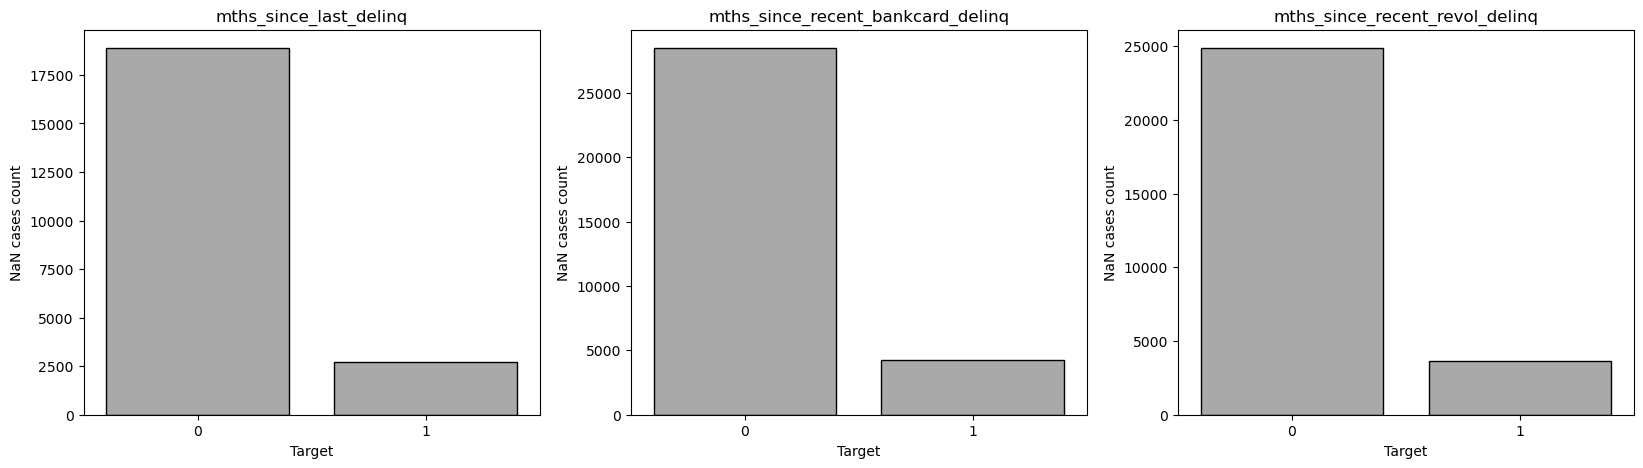

In [11]:
"""
Analysis for 'mths_since_delinq_...' like columns, because the NaNs in those columns may indicate that the customer has never been 
delinquent, which is a valuable information.
"""
mths_since_like_cols = [
	'mths_since_last_delinq',
	'mths_since_recent_bankcard_delinq',
	'mths_since_recent_revol_delinq'
]
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(20, 5))
for i, col in enumerate(mths_since_like_cols):
	nan_cases_per_target = customer_data[ customer_data[col].isna() ]['target'].value_counts()
	sns.barplot(
		x=nan_cases_per_target.index, 
		y=nan_cases_per_target.values, 
		ax=axes[i],
		edgecolor='black',
		color='darkgrey'
	)
	axes[i].set_xlabel('Target')
	axes[i].set_ylabel('NaN cases count')
	axes[i].set_title(col)
plt.show()

In [12]:
"""
The mths_since_delinq_... like columns have a significant number of NaN values, and the majority of those NaN values belong to the customers with target=0 (non-defaulters).
This suggests that the NaN values in these columns likely indicate that the customer has never been delinquent, which is a valuable information for the credit scoring model.
So we will fill missing values in the columns, 'mths_since_recent_bankcard_delinq', and 'mths_since_recent_revol_delinq', -1 or 999 (to indicate this special case)
"""
customer_data[mths_since_like_cols] = (
    customer_data[mths_since_like_cols].fillna(-1)
)


In [13]:
"""
Adding binary flag columns to indicate whether the original 'mths_since_delinq_...' like columns had missing values (which we have
filled with -1). At the same time reorganizing the columns to place the new flag columns next to their corresponding original columns.
"""
current_cols = customer_data.columns.tolist()
new_cols_order = []
for col in current_cols:
    if col in mths_since_like_cols:
        customer_data[f'{col}_flag'] = np.where(customer_data[col] == -1, 0, 1)
        new_cols_order.extend([col, f'{col}_flag'])
    else:
        new_cols_order.append(col)
        
customer_data = customer_data[new_cols_order]
customer_data.head()

,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,verification_status,loan_purpose,addr_state,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,mths_since_last_delinq,mths_since_last_delinq_flag,num_open_credit_lines,num_derogatory_pub_rec,total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,initial_list_status,remaining_princ_for_tot_amnt_fund,paym_rec_for_tot_amnt_fund,princ_rec,interest_rec,late_fees_rec,num_open_trades_in_6mths,num_installment_acc_op_in_12mths,num_installment_acc_op_in_24mths,mths_since_last_installment_acc_op,num_rev_trades_op_in_12mths,num_rev_trades_op_in_24mths,max_bal_owed,bal_to_cred_lim,num_inq,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_bankcard_delinq_flag,mths_since_recent_revol_delinq,mths_since_recent_revol_delinq_flag,disbursement_method,loan_term_months,issue_date_month,issue_date_year,region_code,earliest_cr_line_month,earliest_cr_line_year,target
0,5000,16.99,178.24,D1,Secretary I,< 1 year,RENT,40000.0,Source Verified,other,MD,15.75,1,0,19.0,1,8,0,4437,65.3,22,w,2395.13,3765.420000,2604.87,1160.55,0.0,0.0,0.0,1.0,13.0,2.0,2.0,0.0,27.0,0.0,1,-1.0,0,19.0,1,Cash,36,May,2017,2,Sep,2000,0
1,1500,18.25,54.42,D3,Payroll Administrator,10+ years,RENT,63749.0,Verified,vacation,MD,7.32,0,0,25.0,1,4,1,746,74.6,8,w,0.00,1955.932732,1500.00,455.93,0.0,0.0,0.0,0.0,63.0,0.0,1.0,746.0,41.0,0.0,0,-1.0,0,36.0,1,Cash,36,Feb,2016,2,Jun,1991,0
2,33425,20.49,1250.56,E1,Saint Anthony Hospital,10+ years,RENT,75000.0,Verified,debt_consolidation,IL,31.58,0,2,-1.0,0,16,0,38198,58.6,51,f,0.00,40285.089985,33425.00,6860.09,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,-1.0,0,-1.0,0,Cash,36,Nov,2012,6,Oct,1994,0
3,15000,17.09,373.52,D1,Estimator,3 years,RENT,95000.0,Source Verified,debt_consolidation,NY,12.62,0,0,38.0,1,7,0,8841,65.5,10,w,11332.27,7490.220000,3667.73,3822.49,0.0,0.0,1.0,1.0,10.0,0.0,1.0,3206.0,66.0,1.0,3,-1.0,0,-1.0,0,Cash,60,Jun,2017,1,Jul,2011,0
4,20000,18.25,725.56,E1,Foreman,10+ years,MORTGAGE,70000.0,Verified,small_business,NC,26.97,0,2,47.0,1,15,0,21524,47.8,28,w,0.00,25468.895172,20000.00,5468.90,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,-1.0,0,-1.0,0,Cash,36,Apr,2015,2,Mar,1996,0


In [14]:
major_nans_in_columns = (
    customer_data
    .isna()
    .sum() > 0.3 * len(customer_data)
)
customer_data = customer_data.loc[:, ~major_nans_in_columns]

In [15]:
any( (customer_data.isna().values.flatten()) )

False

In [16]:
customer_data = (
	customer_data
	.dropna()
	.reset_index(drop=True)
)
customer_data.shape

(42792, 40)

In [17]:
customer_data.head()

,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,verification_status,loan_purpose,addr_state,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,mths_since_last_delinq,mths_since_last_delinq_flag,num_open_credit_lines,num_derogatory_pub_rec,total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,initial_list_status,remaining_princ_for_tot_amnt_fund,paym_rec_for_tot_amnt_fund,princ_rec,interest_rec,late_fees_rec,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_bankcard_delinq_flag,mths_since_recent_revol_delinq,mths_since_recent_revol_delinq_flag,disbursement_method,loan_term_months,issue_date_month,issue_date_year,region_code,earliest_cr_line_month,earliest_cr_line_year,target
0,5000,16.99,178.24,D1,Secretary I,< 1 year,RENT,40000.0,Source Verified,other,MD,15.75,1,0,19.0,1,8,0,4437,65.3,22,w,2395.13,3765.420000,2604.87,1160.55,0.0,1,-1.0,0,19.0,1,Cash,36,May,2017,2,Sep,2000,0
1,1500,18.25,54.42,D3,Payroll Administrator,10+ years,RENT,63749.0,Verified,vacation,MD,7.32,0,0,25.0,1,4,1,746,74.6,8,w,0.00,1955.932732,1500.00,455.93,0.0,0,-1.0,0,36.0,1,Cash,36,Feb,2016,2,Jun,1991,0
2,33425,20.49,1250.56,E1,Saint Anthony Hospital,10+ years,RENT,75000.0,Verified,debt_consolidation,IL,31.58,0,2,-1.0,0,16,0,38198,58.6,51,f,0.00,40285.089985,33425.00,6860.09,0.0,2,-1.0,0,-1.0,0,Cash,36,Nov,2012,6,Oct,1994,0
3,15000,17.09,373.52,D1,Estimator,3 years,RENT,95000.0,Source Verified,debt_consolidation,NY,12.62,0,0,38.0,1,7,0,8841,65.5,10,w,11332.27,7490.220000,3667.73,3822.49,0.0,3,-1.0,0,-1.0,0,Cash,60,Jun,2017,1,Jul,2011,0
4,20000,18.25,725.56,E1,Foreman,10+ years,MORTGAGE,70000.0,Verified,small_business,NC,26.97,0,2,47.0,1,15,0,21524,47.8,28,w,0.00,25468.895172,20000.00,5468.90,0.0,2,-1.0,0,-1.0,0,Cash,36,Apr,2015,2,Mar,1996,0


In [18]:
(customer_data['funded_amnt'].value_counts().index.min(),
customer_data['funded_amnt'].value_counts().index.max())

(900, 40000)

In [19]:
customer_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42792 entries, 0 to 42791
Data columns (total 40 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   funded_amnt                             42792 non-null  int64  
 1   interest_rate                           42792 non-null  float64
 2   monthly_payment                         42792 non-null  float64
 3   grade                                   42792 non-null  object 
 4   emp_title                               42792 non-null  object 
 5   emp_length                              42792 non-null  object 
 6   home_ownership_status                   42792 non-null  object 
 7   annual_income                           42792 non-null  float64
 8   verification_status                     42792 non-null  object 
 9   loan_purpose                            42792 non-null  object 
 10  addr_state                              42792 non-null  ob

In [20]:
""" Inserting new feature - credit_history_age column based on the appropriate date columns """
try:
	credit_history_col_index = (
		customer_data
		.columns
		.to_list()
		.index('issue_date_year') + 1
	)
	customer_data.insert(
		credit_history_col_index,
		'credit_history_age',
		customer_data['issue_date_year'] - customer_data['earliest_cr_line_year']
	)
	# removing the columns related to credit history column
	customer_data = customer_data.drop(
		columns=['issue_date_month', 'issue_date_year', 'earliest_cr_line_month', 'earliest_cr_line_year']
	)
except Exception as e:
	print(f"The 'credit_history' column has been inserted already: '{e}'")

In [21]:
""" Save flag cols to exclude them from numerical describe table, because those are binary values """
flag_col_mask = customer_data.columns.str.contains('_flag')
flag_cols = customer_data.columns[flag_col_mask]
flag_cols

Index(['mths_since_last_delinq_flag', 'mths_since_recent_bankcard_delinq_flag',
       'mths_since_recent_revol_delinq_flag'],
      dtype='object')

In [22]:
""" Excluding flag cols and target col from numeric describe table, because they are binary """
numerical_data, numerical_data_describe = hf.numeric_describe(
    customer_data[ customer_data.columns.difference([*flag_cols, 'target']) ]
)
numerical_data_describe

,count,mean,std,min,25%,50%,75%,max,unique,var_coeff [%],median,skew,kurtosis
annual_income,42792.00,78906.08,82574.66,5000.00,47501.50,65000.00,95000.00,8365188.00,4510.00,104.65,65000.00,49.40,4243.20
credit_history_age,42792.00,16.37,7.63,0.00,11.00,15.00,20.00,61.00,57.00,46.61,15.00,1.04,1.51
dept_paym_income_ratio,42792.00,18.07,8.40,0.00,11.76,17.60,24.02,49.15,3932.00,46.48,17.60,0.23,-0.54
funded_amnt,42792.00,14685.99,8961.07,900.00,8000.00,12000.00,20000.00,40000.00,1285.00,61.02,12000.00,0.80,-0.03
interest_rate,42792.00,13.06,4.78,5.31,9.49,12.62,15.80,30.99,506.00,36.58,12.62,0.75,0.58
interest_rec,42792.00,2385.68,2662.22,0.00,697.53,1479.34,3037.92,27082.45,39440.00,111.59,1479.34,2.53,8.94
late_fees_rec,42792.00,1.45,11.39,0.00,0.00,0.00,0.00,748.56,1051.00,786.04,0.00,20.11,735.00
loan_term_months,42792.00,42.73,10.78,36.00,36.00,36.00,60.00,60.00,2.00,25.23,36.00,0.98,-1.04
monthly_payment,42792.00,436.17,260.48,25.16,248.82,371.96,576.02,1587.23,17199.00,59.72,371.96,1.03,0.81
mths_since_last_delinq,42792.00,16.57,23.57,-1.00,-1.00,-1.00,31.00,152.00,118.00,142.21,-1.00,1.19,0.29


"loan_term_months" column has only 2 values so we can treat it as category variable, the "region_code" variable is also converted to object

In [23]:
customer_data['loan_term_months'] = customer_data['loan_term_months'].astype('object')
customer_data['region_code'] = customer_data['region_code'].astype('object')

In [24]:
""" 
Adding log-transformed columns for annual_income, late_fees_rec and total_credit_revolving_bal, because of high 
variability and extremely high positive skewness, log(x+1) transformation is applied to avoid 0 inside log 
"""
try:
	ann_inc_idx = customer_data.columns.to_list().index('annual_income')
	customer_data.insert(
		ann_inc_idx + 1, 
		'log_annual_income', 
		np.log(customer_data['annual_income'] + 1)
	)
	
	interest_rec_idx = customer_data.columns.to_list().index('interest_rec')
	customer_data.insert(
		interest_rec_idx + 1, 
		'log_interest_rec', 
		np.log(customer_data['interest_rec'] + 1)
	)

	late_fees_rec_idx = customer_data.columns.to_list().index('late_fees_rec')
	customer_data.insert(
		late_fees_rec_idx + 1, 
		'log_late_fees_rec', 
		np.log(customer_data['late_fees_rec'] + 1)
	)
	
	remaining_princ_for_tot_amnt_fund_idx = customer_data.columns.to_list().index('remaining_princ_for_tot_amnt_fund')
	customer_data.insert(
		remaining_princ_for_tot_amnt_fund_idx + 1, 
		'log_remaining_princ_for_tot_amnt_fund', 
		np.log(customer_data['remaining_princ_for_tot_amnt_fund'] + 1)
	)
	
	tot_credit_revol_bal_idx = customer_data.columns.to_list().index('total_credit_revolving_bal')
	customer_data.insert(
		tot_credit_revol_bal_idx + 1, 
		'log_total_credit_revolving_bal', 
		np.log(customer_data['total_credit_revolving_bal'] + 1)
	)
except Exception as e:
	print(f"The log-transformed columns have been inserted already: '{e}'")

In [25]:
customer_data.head()

,funded_amnt,interest_rate,monthly_payment,grade,emp_title,emp_length,home_ownership_status,annual_income,log_annual_income,verification_status,loan_purpose,addr_state,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,mths_since_last_delinq,mths_since_last_delinq_flag,num_open_credit_lines,num_derogatory_pub_rec,total_credit_revolving_bal,log_total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,initial_list_status,remaining_princ_for_tot_amnt_fund,log_remaining_princ_for_tot_amnt_fund,paym_rec_for_tot_amnt_fund,princ_rec,interest_rec,log_interest_rec,late_fees_rec,log_late_fees_rec,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_bankcard_delinq_flag,mths_since_recent_revol_delinq,mths_since_recent_revol_delinq_flag,disbursement_method,loan_term_months,credit_history_age,region_code,target
0,5000,16.99,178.24,D1,Secretary I,< 1 year,RENT,40000.00,10.60,Source Verified,other,MD,15.75,1,0,19.00,1,8,0,4437,8.40,65.30,22,w,2395.13,7.78,3765.42,2604.87,1160.55,7.06,0.00,0.00,1,-1.00,0,19.00,1,Cash,36,17,2,0
1,1500,18.25,54.42,D3,Payroll Administrator,10+ years,RENT,63749.00,11.06,Verified,vacation,MD,7.32,0,0,25.00,1,4,1,746,6.62,74.60,8,w,0.00,0.00,1955.93,1500.00,455.93,6.12,0.00,0.00,0,-1.00,0,36.00,1,Cash,36,25,2,0
2,33425,20.49,1250.56,E1,Saint Anthony Hospital,10+ years,RENT,75000.00,11.23,Verified,debt_consolidation,IL,31.58,0,2,-1.00,0,16,0,38198,10.55,58.60,51,f,0.00,0.00,40285.09,33425.00,6860.09,8.83,0.00,0.00,2,-1.00,0,-1.00,0,Cash,36,18,6,0
3,15000,17.09,373.52,D1,Estimator,3 years,RENT,95000.00,11.46,Source Verified,debt_consolidation,NY,12.62,0,0,38.00,1,7,0,8841,9.09,65.50,10,w,11332.27,9.34,7490.22,3667.73,3822.49,8.25,0.00,0.00,3,-1.00,0,-1.00,0,Cash,60,6,1,0
4,20000,18.25,725.56,E1,Foreman,10+ years,MORTGAGE,70000.00,11.16,Verified,small_business,NC,26.97,0,2,47.00,1,15,0,21524,9.98,47.80,28,w,0.00,0.00,25468.90,20000.00,5468.90,8.61,0.00,0.00,2,-1.00,0,-1.00,0,Cash,36,19,2,0


In [26]:
numerical_data, numerical_data_describe = hf.numeric_describe(
    customer_data[ customer_data.columns.difference([*flag_cols, 'target']) ]
)
numerical_data_describe

,count,mean,std,min,25%,50%,75%,max,unique,var_coeff [%],median,skew,kurtosis
annual_income,42792.00,78906.08,82574.66,5000.00,47501.50,65000.00,95000.00,8365188.00,4510.00,104.65,65000.00,49.40,4243.20
credit_history_age,42792.00,16.37,7.63,0.00,11.00,15.00,20.00,61.00,57.00,46.61,15.00,1.04,1.51
dept_paym_income_ratio,42792.00,18.07,8.40,0.00,11.76,17.60,24.02,49.15,3932.00,46.48,17.60,0.23,-0.54
funded_amnt,42792.00,14685.99,8961.07,900.00,8000.00,12000.00,20000.00,40000.00,1285.00,61.02,12000.00,0.80,-0.03
interest_rate,42792.00,13.06,4.78,5.31,9.49,12.62,15.80,30.99,506.00,36.58,12.62,0.75,0.58
interest_rec,42792.00,2385.68,2662.22,0.00,697.53,1479.34,3037.92,27082.45,39440.00,111.59,1479.34,2.53,8.94
late_fees_rec,42792.00,1.45,11.39,0.00,0.00,0.00,0.00,748.56,1051.00,786.04,0.00,20.11,735.00
log_annual_income,42792.00,11.11,0.55,8.52,10.77,11.08,11.46,15.94,4510.00,4.91,11.08,0.24,1.27
log_interest_rec,42792.00,7.22,1.18,0.00,6.55,7.30,8.02,10.21,39440.00,16.37,7.30,-0.87,2.55
log_late_fees_rec,42792.00,0.13,0.66,0.00,0.00,0.00,0.00,6.62,1051.00,515.54,0.00,5.19,26.40


In [27]:
hf.dataframe_to_pdf(
    numerical_data_describe.loc[:, ~numerical_data_describe.columns.isin(['count', '25%', '50%', '75%'])], 
    'numerical_data_describe.pdf', 
    title="Numerical data describe (statistics)", 
    max_rows=30,
    max_table_width=190
)

PDF generated: numerical_data_describe.pdf (table width: 190.0mm)


In [28]:
categorical_data = (
    customer_data
    .select_dtypes(['object', 'category'])
    .dropna()
    .reset_index(drop=True)
)
categorical_data.describe().transpose().rename(columns={'top': 'most frequent category'})

,count,unique,most frequent category,freq
grade,42792,35,C1,2799
emp_title,42792,20444,unknown,2843
emp_length,42792,12,10+ years,14424
home_ownership_status,42792,4,MORTGAGE,20714
verification_status,42792,3,Source Verified,17034
loan_purpose,42792,14,debt_consolidation,24069
addr_state,42792,50,CA,5951
initial_list_status,42792,2,w,28598
disbursement_method,42792,2,Cash,41375
loan_term_months,42792,2,36,30797


In [29]:
(numerical_data.columns.size, categorical_data.columns.size)

(27, 11)

### Data Visualization

Drawing distribution plots [42/42]

('funded_amnt', 'histogram')
('interest_rate', 'histogram')
('monthly_payment', 'histogram')
('grade', 'barplot')
('emp_title', 'barplot')
('emp_length', 'barplot')
('home_ownership_status', 'barplot')
('annual_income', 'histogram')
('log_annual_income', 'histogram')
('verification_status', 'barplot')
('loan_purpose', 'barplot')
('addr_state', 'barplot')
('dept_paym_income_ratio', 'histogram')
('num_30+_delinq_in_2yrs', 'barplot')
('num_inq_in_6mths', 'barplot')
('mths_since_last_delinq', 'histogram')
('mths_since_last_delinq_flag', 'barplot')
('num_open_credit_lines', 'histogram')
('num_derogatory_pub_rec', 'barplot')
('total_credit_revolving_bal', 'histogram')
('log_total_credit_revolving_bal', 'histogram')
('used_credit_share', 'histogram')
('tot_num_credit_lines', 'histogram')
('initial_list_status', 'barplot')
('remaining_princ_for_tot_amnt_fund', 'histogram')
('log_remaining_princ_for_tot_amnt_fund', 'histogram')
('paym_rec_for_tot_amnt_fund', 

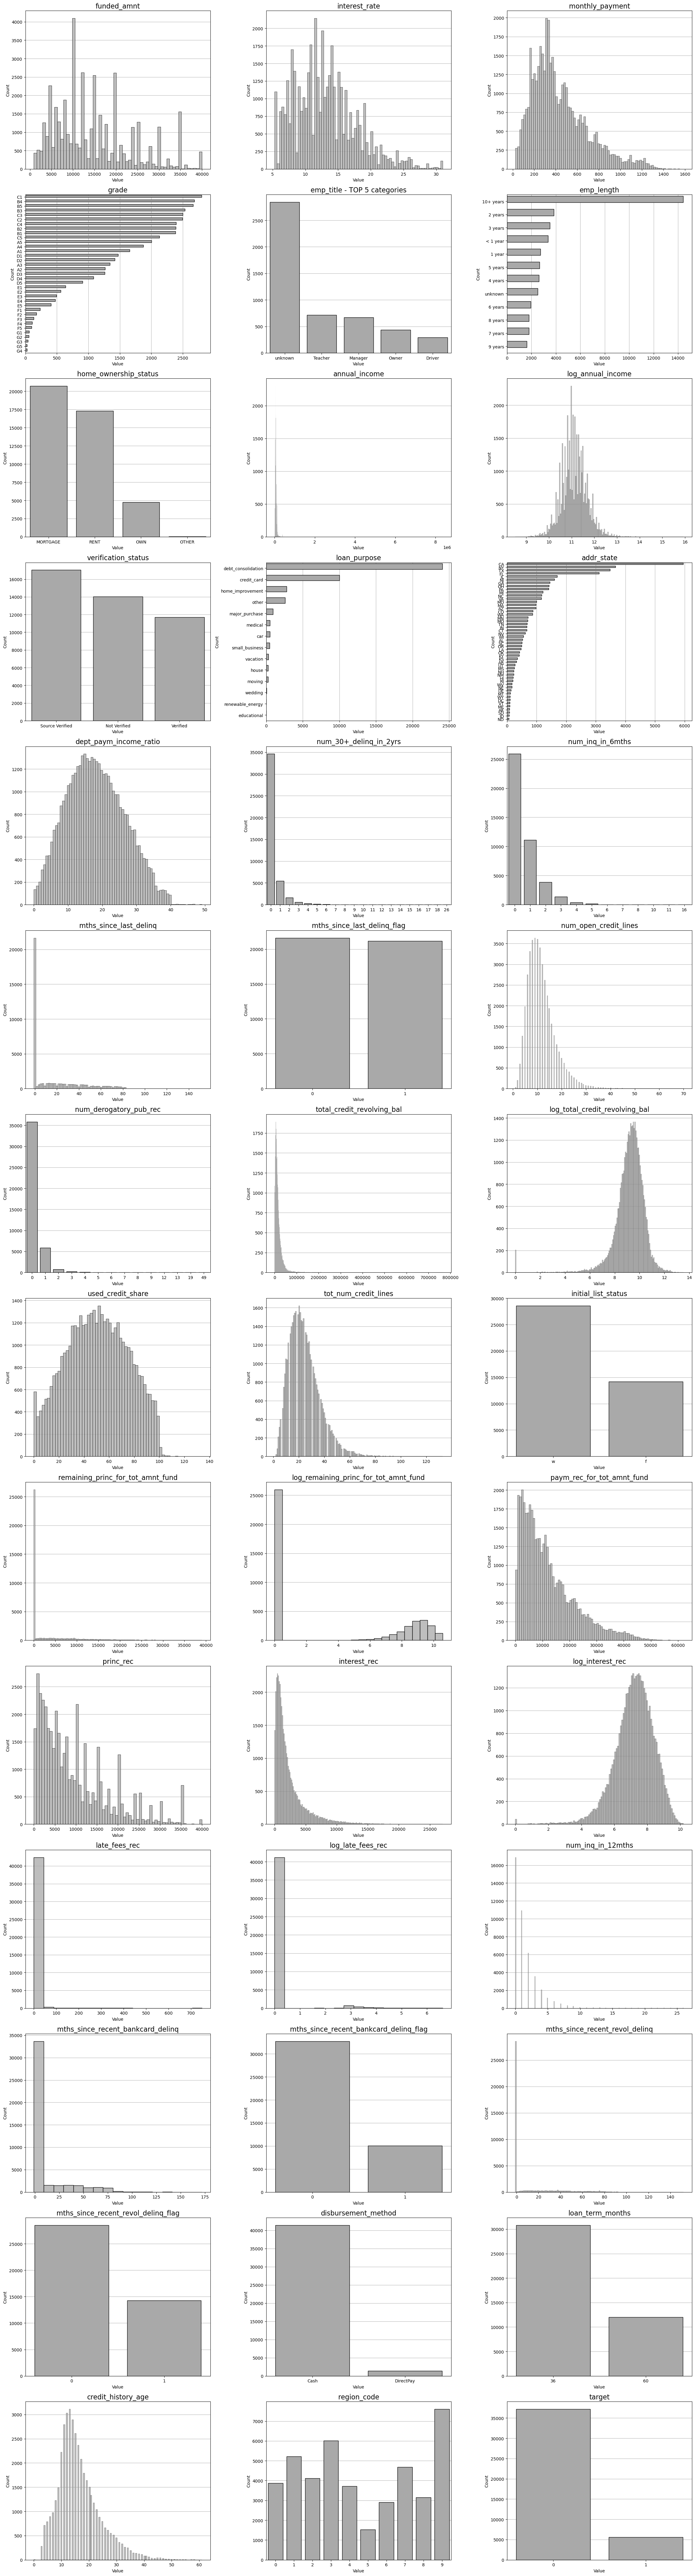

In [30]:
hf.draw_distribution(
    df=customer_data,
    subplot_size=(23, 85),
    subplot_cols=3,
	plot_color='darkgrey',
    title_fontsize=16
)

In [31]:
categorical_data = customer_data.select_dtypes(['object', 'category'])
categorical_data.head()

,grade,emp_title,emp_length,home_ownership_status,verification_status,loan_purpose,addr_state,initial_list_status,disbursement_method,loan_term_months,region_code
0,D1,Secretary I,< 1 year,RENT,Source Verified,other,MD,w,Cash,36,2
1,D3,Payroll Administrator,10+ years,RENT,Verified,vacation,MD,w,Cash,36,2
2,E1,Saint Anthony Hospital,10+ years,RENT,Verified,debt_consolidation,IL,f,Cash,36,6
3,D1,Estimator,3 years,RENT,Source Verified,debt_consolidation,NY,w,Cash,60,1
4,E1,Foreman,10+ years,MORTGAGE,Verified,small_business,NC,w,Cash,36,2


Categorical and numerical statistics (after adjusting variables to the proper groups of data)

In [32]:
categorical_data.describe().transpose()

,count,unique,top,freq
grade,42792,35,C1,2799
emp_title,42792,20444,unknown,2843
emp_length,42792,12,10+ years,14424
home_ownership_status,42792,4,MORTGAGE,20714
verification_status,42792,3,Source Verified,17034
loan_purpose,42792,14,debt_consolidation,24069
addr_state,42792,50,CA,5951
initial_list_status,42792,2,w,28598
disbursement_method,42792,2,Cash,41375
loan_term_months,42792,2,36,30797


In [33]:
numerical_data.columns

Index(['annual_income', 'credit_history_age', 'dept_paym_income_ratio',
       'funded_amnt', 'interest_rate', 'interest_rec', 'late_fees_rec',
       'log_annual_income', 'log_interest_rec', 'log_late_fees_rec',
       'log_remaining_princ_for_tot_amnt_fund',
       'log_total_credit_revolving_bal', 'monthly_payment',
       'mths_since_last_delinq', 'mths_since_recent_bankcard_delinq',
       'mths_since_recent_revol_delinq', 'num_30+_delinq_in_2yrs',
       'num_derogatory_pub_rec', 'num_inq_in_12mths', 'num_inq_in_6mths',
       'num_open_credit_lines', 'paym_rec_for_tot_amnt_fund', 'princ_rec',
       'remaining_princ_for_tot_amnt_fund', 'tot_num_credit_lines',
       'total_credit_revolving_bal', 'used_credit_share'],
      dtype='object')

Drawing boxplots [27/27]
[1969, 1421, 24, 495, 855, 3206, 1614, 748, 727, 1614, 0, 1554, 1415, 368, 10073, 4763, 8180, 6933, 2094, 1933, 1616, 1451, 1120, 4263, 949, 2635, 3]


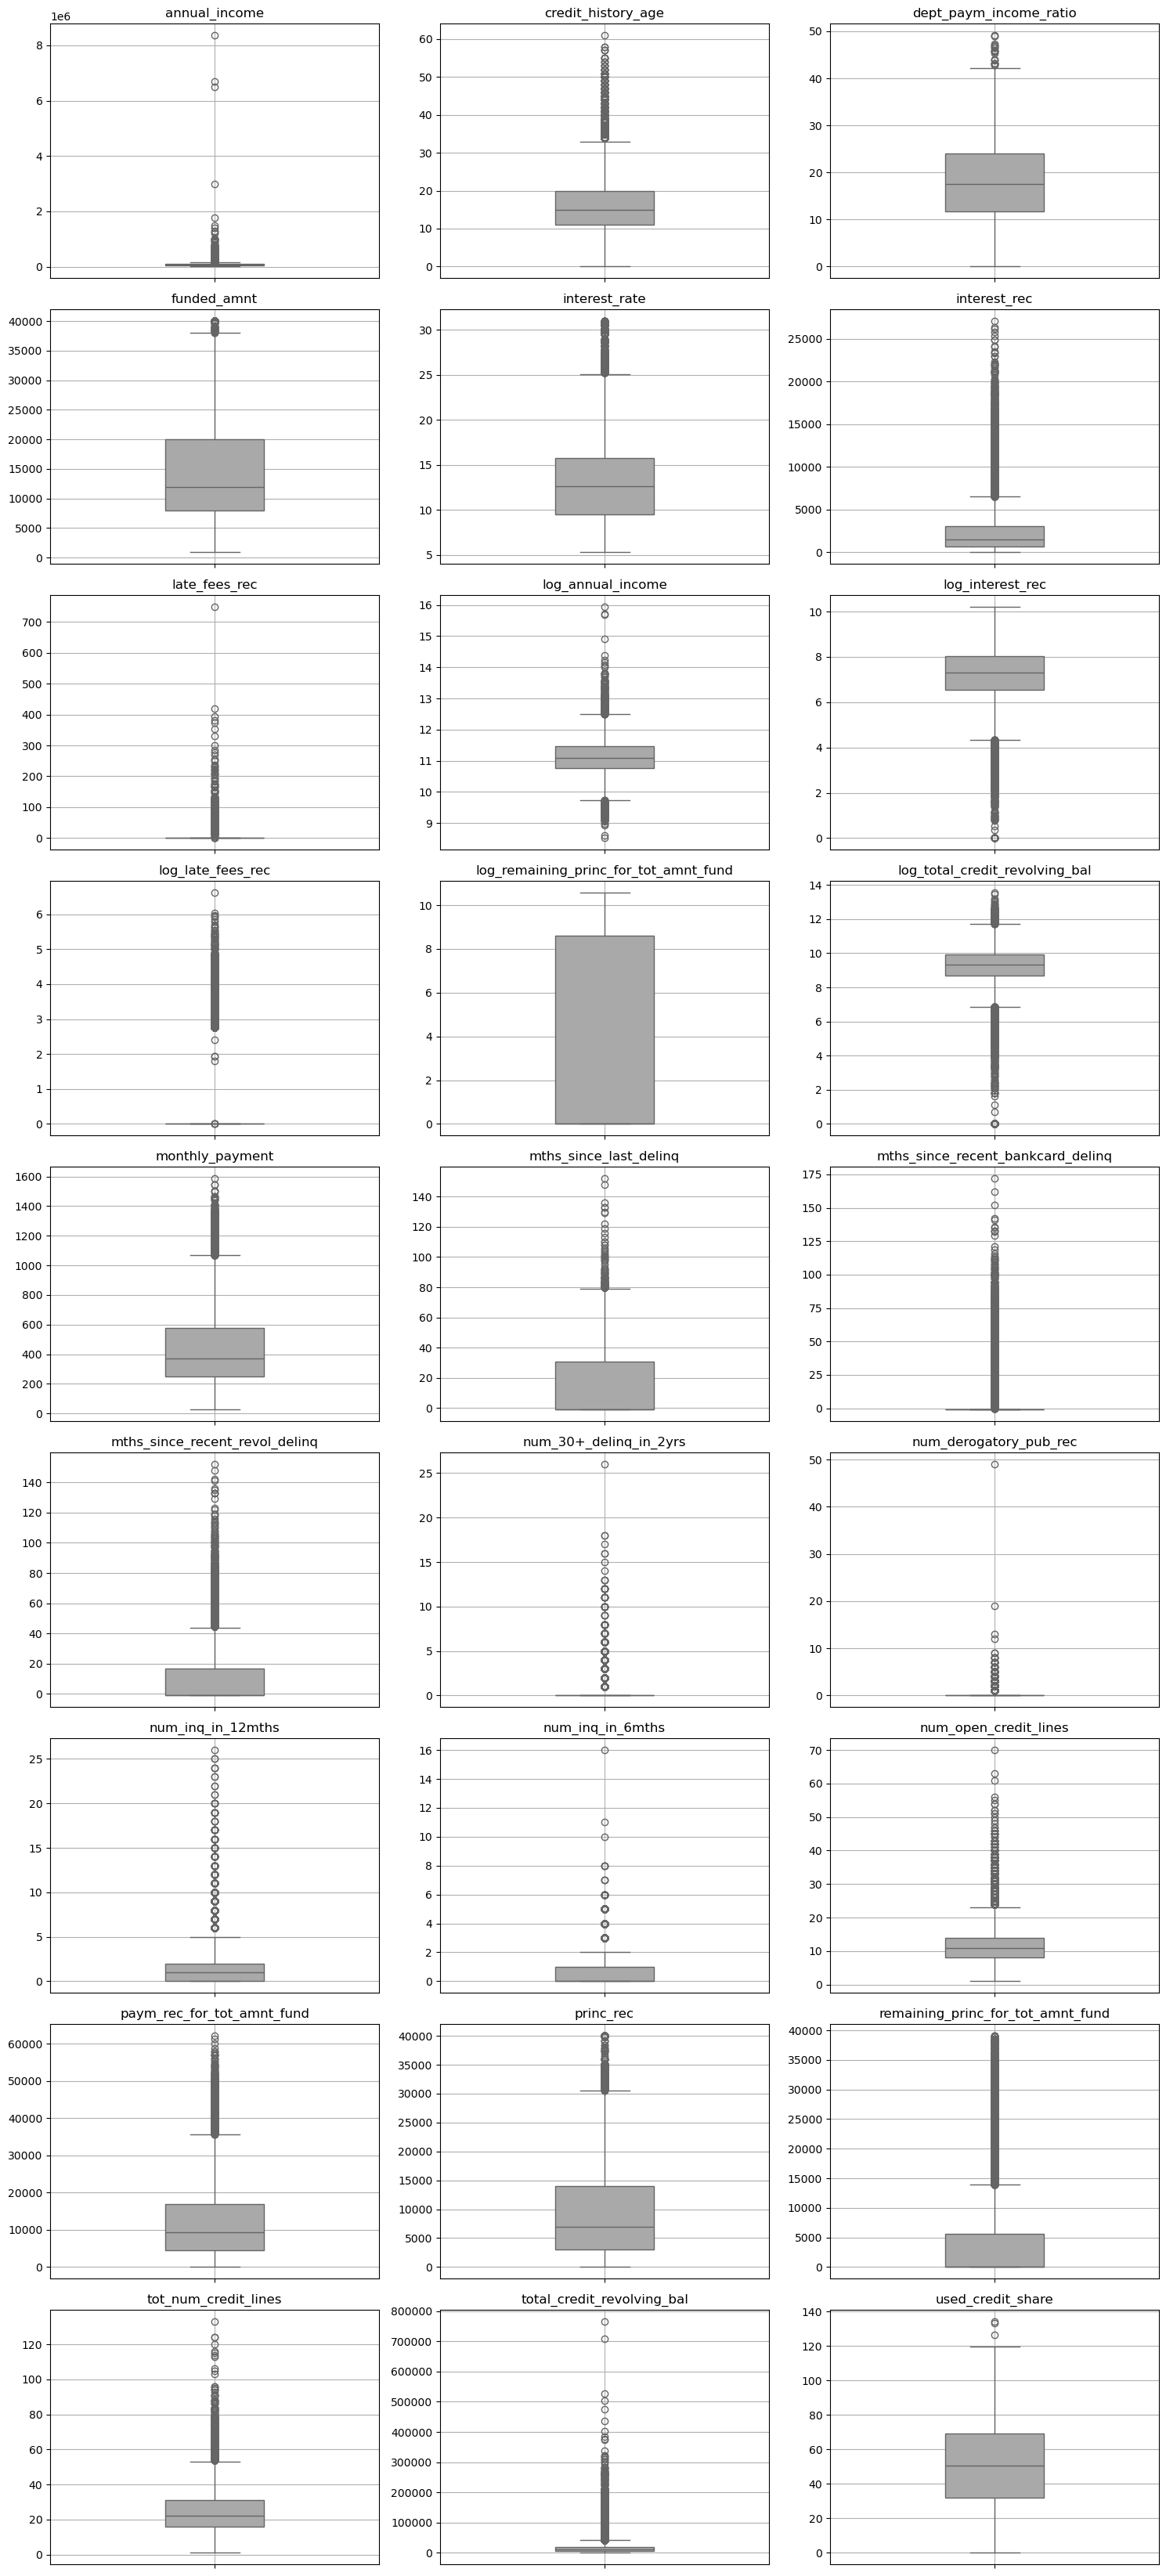

In [34]:
hf.draw_boxplots(
    df=numerical_data, # all numerical columns excluding the binary ones like the '_flag' columns and target
    subplot_size=(15, 33),
    plot_color='darkgrey'
)

In [35]:
"""
Checking data after removing the outliers, but it turns out that then we lose minority class so the outliers 
will be kept, because they seem to strongly represent the minority class
"""
df_dropped_outliers = hf.handle_outliers(customer_data, remove=True)
df_dropped_outliers['target'].value_counts()

Customer dataframe INPUT size: 42792
Deleted rows containing outliers: 30874
Customer dataframe OUTPUT size: 11918


target
0    11918
Name: count, dtype: int64

In [36]:
categorical_data.describe().transpose()

,count,unique,top,freq
grade,42792,35,C1,2799
emp_title,42792,20444,unknown,2843
emp_length,42792,12,10+ years,14424
home_ownership_status,42792,4,MORTGAGE,20714
verification_status,42792,3,Source Verified,17034
loan_purpose,42792,14,debt_consolidation,24069
addr_state,42792,50,CA,5951
initial_list_status,42792,2,w,28598
disbursement_method,42792,2,Cash,41375
loan_term_months,42792,2,36,30797


In [37]:
cat_data_df_describe = categorical_data.describe().transpose()
hf.dataframe_to_pdf(
	cat_data_df_describe, 
	'categorical_data_describe.pdf', 
	title="Categorical data describe (statistics)", 
	max_rows=30,
    max_table_width=110,
    int_values=True
)

PDF generated: categorical_data_describe.pdf (table width: 72.3mm)


In [38]:
""" Extracting grades in a more general form (only the letters ranging from A to G), avoiding too many unique values """
# customer_data['grade'] = customer_data['grade'].str[0]

' Extracting grades in a more general form (only the letters ranging from A to G), avoiding too many unique values '

In [39]:
""" Dropping the columns with too many unique values """
try:
	customer_data = customer_data.drop(
		columns=['grade', 'emp_title', 'addr_state']
	)
except Exception as e:
	print(f"The categorical columns with too many unique values have been already removed: {e}")
customer_data.select_dtypes('object').describe().transpose()

,count,unique,top,freq
emp_length,42792,12,10+ years,14424
home_ownership_status,42792,4,MORTGAGE,20714
verification_status,42792,3,Source Verified,17034
loan_purpose,42792,14,debt_consolidation,24069
initial_list_status,42792,2,w,28598
disbursement_method,42792,2,Cash,41375
loan_term_months,42792,2,36,30797
region_code,42792,10,9,7604


In [40]:
""" Dropping the original columns for which the log(x+1) transform column was added """
customer_data = customer_data.drop(
    columns=['annual_income', 'interest_rec', 'late_fees_rec', 'remaining_princ_for_tot_amnt_fund', 'total_credit_revolving_bal']
)

In [41]:
customer_data.head()

,funded_amnt,interest_rate,monthly_payment,emp_length,home_ownership_status,log_annual_income,verification_status,loan_purpose,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,mths_since_last_delinq,mths_since_last_delinq_flag,num_open_credit_lines,num_derogatory_pub_rec,log_total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,initial_list_status,log_remaining_princ_for_tot_amnt_fund,paym_rec_for_tot_amnt_fund,princ_rec,log_interest_rec,log_late_fees_rec,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_bankcard_delinq_flag,mths_since_recent_revol_delinq,mths_since_recent_revol_delinq_flag,disbursement_method,loan_term_months,credit_history_age,region_code,target
0,5000,16.99,178.24,< 1 year,RENT,10.60,Source Verified,other,15.75,1,0,19.00,1,8,0,8.40,65.30,22,w,7.78,3765.42,2604.87,7.06,0.00,1,-1.00,0,19.00,1,Cash,36,17,2,0
1,1500,18.25,54.42,10+ years,RENT,11.06,Verified,vacation,7.32,0,0,25.00,1,4,1,6.62,74.60,8,w,0.00,1955.93,1500.00,6.12,0.00,0,-1.00,0,36.00,1,Cash,36,25,2,0
2,33425,20.49,1250.56,10+ years,RENT,11.23,Verified,debt_consolidation,31.58,0,2,-1.00,0,16,0,10.55,58.60,51,f,0.00,40285.09,33425.00,8.83,0.00,2,-1.00,0,-1.00,0,Cash,36,18,6,0
3,15000,17.09,373.52,3 years,RENT,11.46,Source Verified,debt_consolidation,12.62,0,0,38.00,1,7,0,9.09,65.50,10,w,9.34,7490.22,3667.73,8.25,0.00,3,-1.00,0,-1.00,0,Cash,60,6,1,0
4,20000,18.25,725.56,10+ years,MORTGAGE,11.16,Verified,small_business,26.97,0,2,47.00,1,15,0,9.98,47.80,28,w,0.00,25468.90,20000.00,8.61,0.00,2,-1.00,0,-1.00,0,Cash,36,19,2,0


In [42]:
customer_data.shape

(42792, 34)

In [43]:
""" Splitting data into training (80 %) and test (20 %) sets """
df_train, df_test = train_test_split(
	customer_data,
    train_size=0.8,
    random_state=random_state,
    stratify=customer_data['target']
)
df_train.reset_index(drop=True, inplace=True)
df_test.reset_index(drop=True, inplace=True)
df_train['target'].value_counts(), df_test['target'].value_counts()

(target
 0    29758
 1     4475
 Name: count, dtype: int64,
 target
 0    7440
 1    1119
 Name: count, dtype: int64)

### Categorical values encoding using OneHotEncoder

In [44]:
"""
Passing only the training data to the encoding function to avoid data leakage (target column is in numeric
form already at this stage so it shouldn't and won't be affected)
"""
df_train_encoded, ohe_fitted = hf.encode_categoric_data(df=df_train)
print()
df_test_encoded, _ = hf.encode_categoric_data(df=df_test, ohe=ohe_fitted)

1) emp_length - encoded 12 categories [reference category: '1 year']
2) home_ownership_status - encoded 4 categories [reference category: 'MORTGAGE']
3) verification_status - encoded 3 categories [reference category: 'Not Verified']
4) loan_purpose - encoded 14 categories [reference category: 'car']
5) initial_list_status - encoded 2 categories [reference category: 'f']
6) disbursement_method - encoded 2 categories [reference category: 'Cash']
7) loan_term_months - encoded 2 categories [reference category: '36']
8) region_code - encoded 10 categories [reference category: '0']

1) emp_length - encoded 12 categories [reference category: '1 year']
2) home_ownership_status - encoded 4 categories [reference category: 'MORTGAGE']
3) verification_status - encoded 3 categories [reference category: 'Not Verified']
4) loan_purpose - encoded 14 categories [reference category: 'car']
5) initial_list_status - encoded 2 categories [reference category: 'f']
6) disbursement_method - encoded 2 categori

### Correlation Matrix for continous variables

In [45]:
df_train_encoded.head()

,funded_amnt,interest_rate,monthly_payment,log_annual_income,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,mths_since_last_delinq,mths_since_last_delinq_flag,num_open_credit_lines,num_derogatory_pub_rec,log_total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,log_remaining_princ_for_tot_amnt_fund,paym_rec_for_tot_amnt_fund,princ_rec,log_interest_rec,log_late_fees_rec,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_bankcard_delinq_flag,mths_since_recent_revol_delinq,mths_since_recent_revol_delinq_flag,credit_history_age,target,emp_length_10+ years,emp_length_2 years,emp_length_3 years,emp_length_4 years,emp_length_5 years,emp_length_6 years,emp_length_7 years,emp_length_8 years,emp_length_9 years,emp_length_< 1 year,emp_length_unknown,home_ownership_status_OTHER,home_ownership_status_OWN,home_ownership_status_RENT,verification_status_Source Verified,verification_status_Verified,loan_purpose_credit_card,loan_purpose_debt_consolidation,loan_purpose_educational,loan_purpose_home_improvement,loan_purpose_house,loan_purpose_major_purchase,loan_purpose_medical,loan_purpose_moving,loan_purpose_other,loan_purpose_renewable_energy,loan_purpose_small_business,loan_purpose_vacation,loan_purpose_wedding,initial_list_status_w,disbursement_method_DirectPay,loan_term_months_60,region_code_1,region_code_2,region_code_3,region_code_4,region_code_5,region_code_6,region_code_7,region_code_8,region_code_9
0,12000,15.02,416.11,10.69,17.38,1,0,17.00,1,5,0,8.05,50.00,12,0.00,396.08,265.91,4.88,0.00,0,-1.00,0,-1.00,0,11,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0
1,25000,9.76,803.87,11.26,15.95,0,0,-1.00,0,7,0,10.59,68.50,12,0.00,28939.14,25000.00,8.28,0.00,0,-1.00,0,-1.00,0,12,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
2,21000,12.62,473.74,11.81,23.77,0,0,-1.00,0,9,0,10.71,93.00,24,9.64,9460.08,5596.48,8.26,0.00,2,-1.00,0,-1.00,0,19,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0
3,19200,16.29,469.88,11.53,12.87,0,0,31.00,1,12,1,9.73,72.10,22,0.00,28134.16,19200.00,9.10,0.00,0,-1.00,0,-1.00,0,11,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,0
4,17000,26.30,512.02,11.07,17.01,0,0,-1.00,0,7,0,9.50,101.40,10,0.00,18770.00,17000.00,7.48,0.00,2,-1.00,0,-1.00,0,15,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0


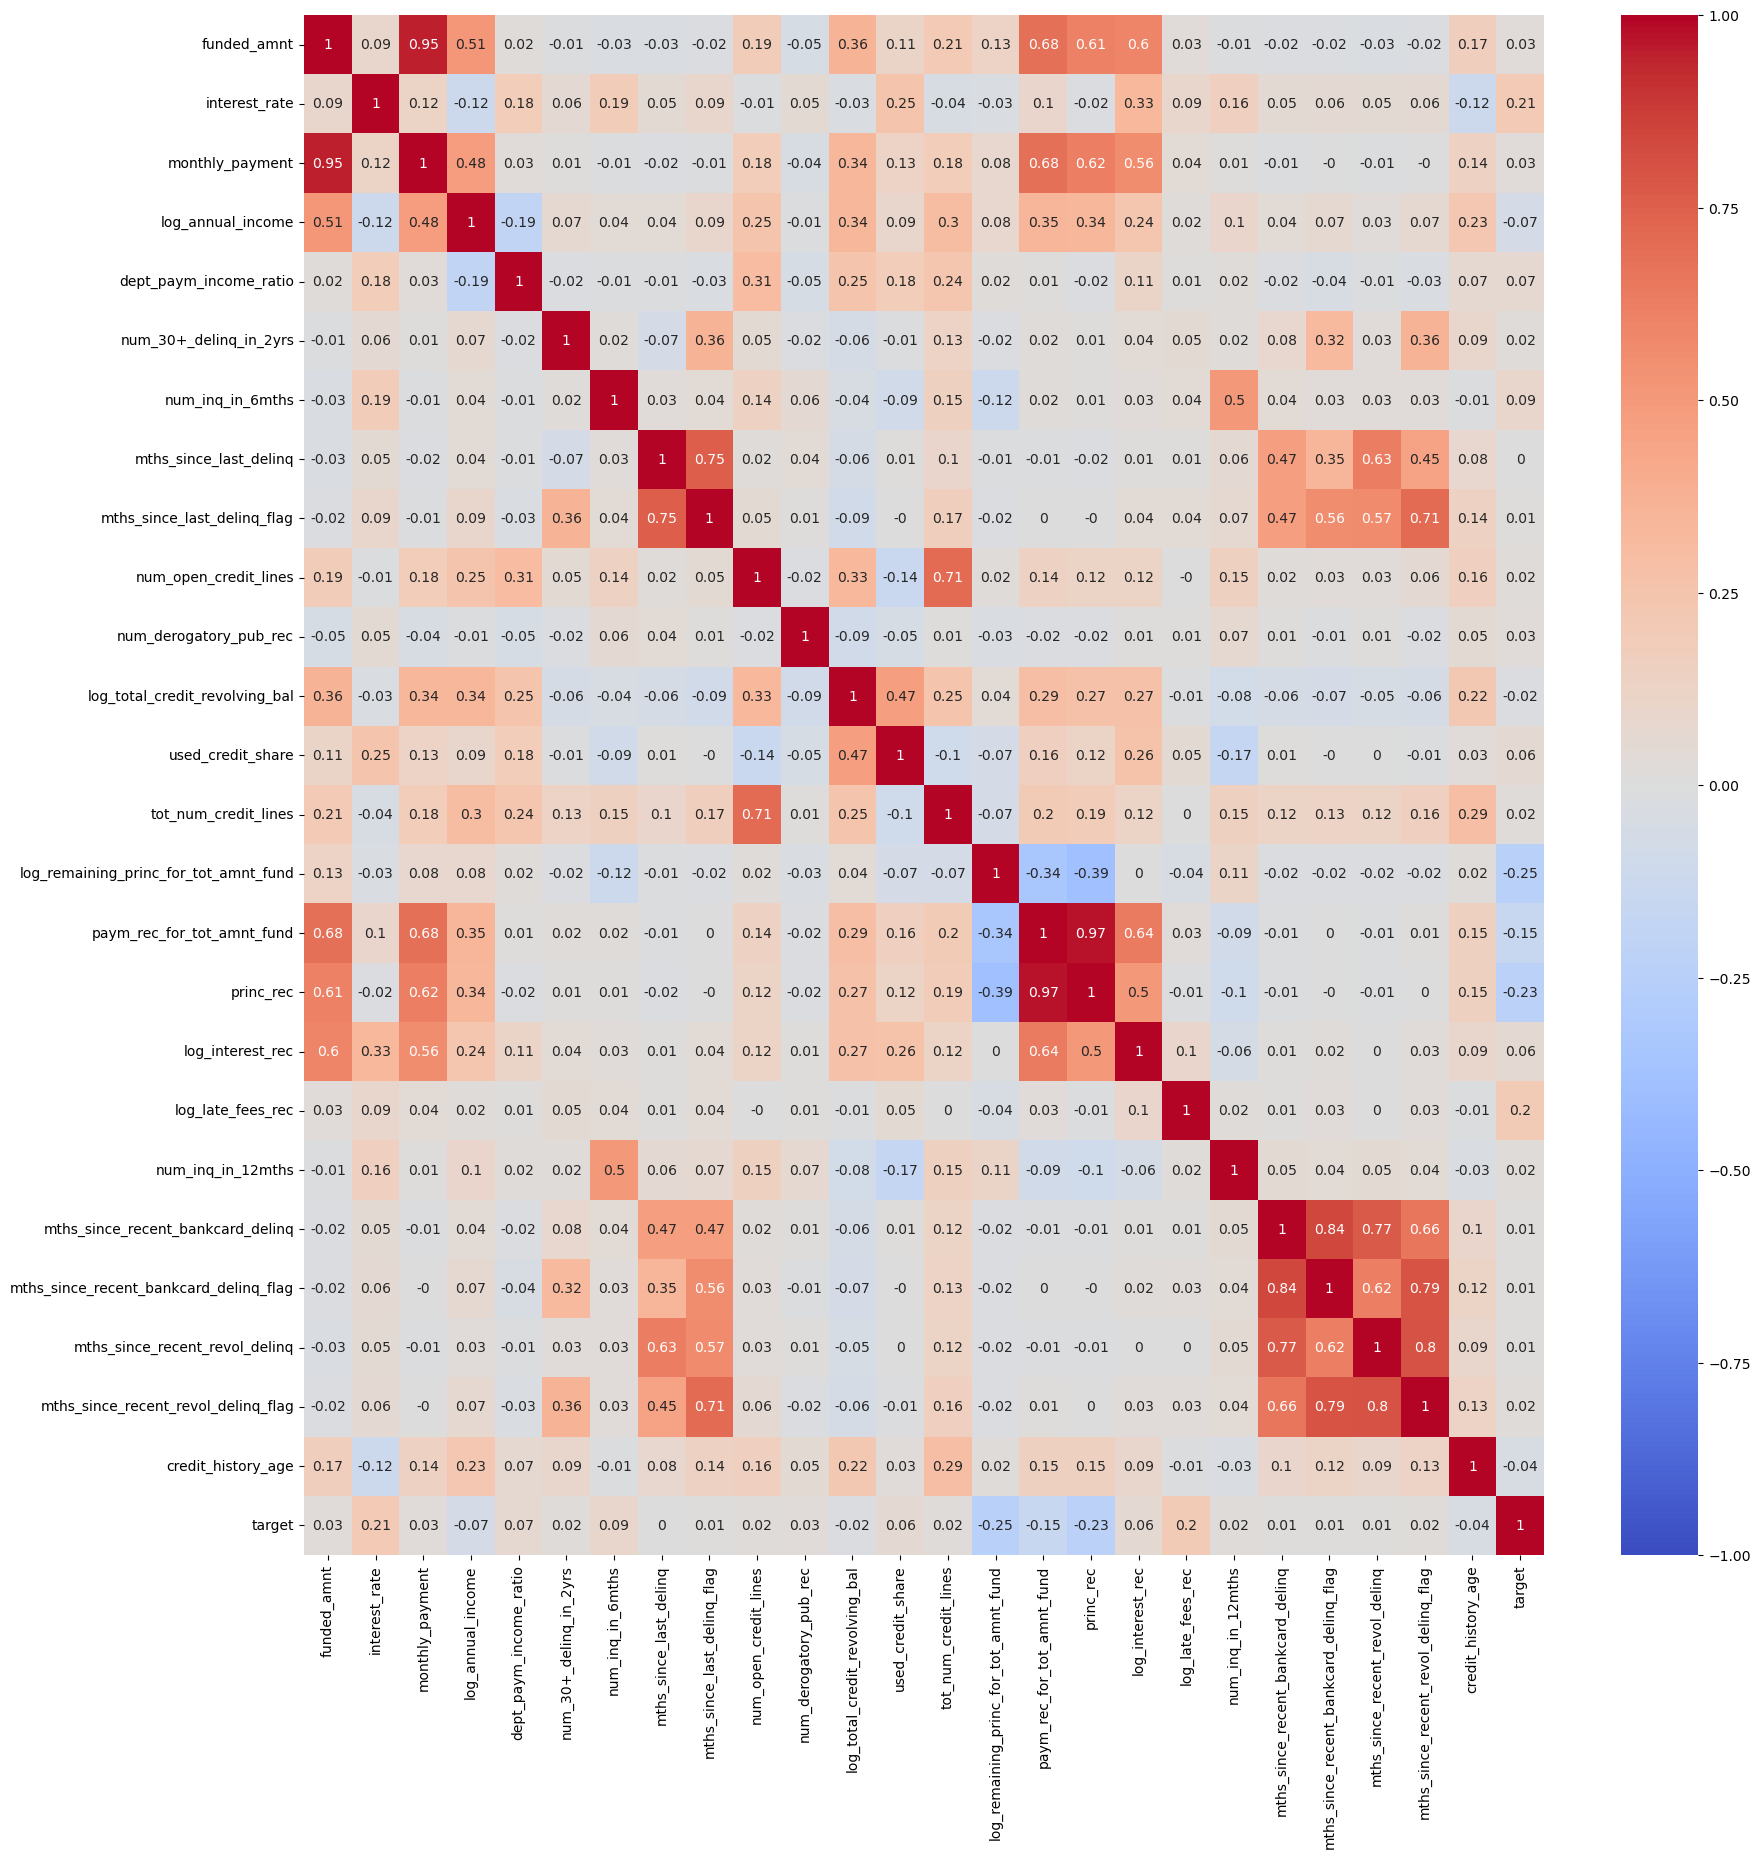

In [46]:
flag_cols_mask = df_train_encoded.columns.str.contains('_flag')
numeric_corr = (
    df_train_encoded
    .loc[:, :'target']
	.corr()
    .round(decimals=2)
)
plt.figure(figsize=(20, 20))
sns.heatmap(
    numeric_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.show()

potential columns to reject because of big correlations:
- "monthly_payment",
- "tot_num_credit_lines"
- "paym_rec_for_tot_amnt_fund" or "princ_rec"

### VIF (Variance Inflation Factor) analysis to determine linearity degree between independent variables
$$ VIF_i = \frac{1}{1 - {R_i}^2} \;\;\;\;\;\;\; i = 1, 2 ... k $$

In [47]:
vifs1 = hf.VIF(df_train_encoded.drop(columns='target'))
vifs1.iloc[:20, :]

,VIF
funded_amnt,52.52
monthly_payment,45.99
paym_rec_for_tot_amnt_fund,38.33
princ_rec,31.38
loan_purpose_debt_consolidation,22.59
loan_purpose_credit_card,16.90
mths_since_recent_revol_delinq_flag,10.77
mths_since_recent_revol_delinq,8.97
mths_since_recent_bankcard_delinq_flag,8.23
mths_since_recent_bankcard_delinq,7.68


In [48]:
"""
Dropping columns that have VIF > 10 because the linearity among the predictors might significantly affect quality of the model,
also there are cases that VIF > 10 and the correlation with another variable based on the correlation matrix is very high so that
confirms the validity of dropping those columns
 - monthly_payment and funded_amnt are highly correlated and both have high VIF so dropping one of them
 - paym_rec_for_tot_amnt_fund and princ_rec are highly correlated and both have high VIF so dropping one of them,
 - loan_purpose_credit_card and loan_purpose_debt_consolidation both have high VIFs so dropping one of them
"""
cols_to_drop = ['monthly_payment', 'paym_rec_for_tot_amnt_fund', 'loan_purpose_debt_consolidation']
vifs2 = hf.VIF( df_train_encoded.drop(columns=[*cols_to_drop, 'target']) )
vifs2.iloc[:20, :]

,VIF
mths_since_recent_revol_delinq_flag,10.77
mths_since_recent_revol_delinq,8.97
mths_since_recent_bankcard_delinq_flag,8.23
mths_since_recent_bankcard_delinq,7.68
mths_since_last_delinq_flag,6.86
mths_since_last_delinq,5.36
emp_length_10+ years,4.29
funded_amnt,3.27
princ_rec,2.92
num_open_credit_lines,2.50


In [49]:
"""
Then also dropping the 'mths_sincerecent_revol_delinq' because of its second highest VIF that is probably caused by its artificial correlation
with 'mths_since_recent_revol_delinq_flag' (which actually has the greatest VIF but on the other hand the flag itself might be more significant
for prediction). Additionally based on the correlation matrix the 'mths_since_recent_revol_delinq' is also correlated (0,77) with 
'mths_since_recent_bankcard_delinq' so dropping one of the is a good step anyway.     
Generally at the same the purpose of those modifications was to stick to the rule to not exceed the established VIF threshold which is here assumed to be VIF* = 10. 
"""
cols_to_drop_v2 = [
    *cols_to_drop,
	'mths_since_recent_revol_delinq'
]
vifs3 = hf.VIF( df_train_encoded.drop(columns=[*cols_to_drop_v2, 'target']) ) 
vifs3.iloc[:20, :]

,VIF
mths_since_recent_bankcard_delinq_flag,6.06
mths_since_last_delinq_flag,5.87
mths_since_recent_bankcard_delinq,4.72
emp_length_10+ years,4.29
mths_since_last_delinq,4.09
mths_since_recent_revol_delinq_flag,3.77
funded_amnt,3.27
princ_rec,2.92
num_open_credit_lines,2.50
region_code_9,2.48


In [50]:
top20_vifs = [vifs1.iloc[:20, :], vifs2.iloc[:20, :], vifs3.iloc[:20, :]]
all_vifs_dfs = []
vif_iters = []
for i, vif_df in enumerate(top20_vifs):
    vif_iters.append(f'Iter {i}')
    all_vifs_dfs.extend([
		vif_df.index,
        vif_df.values.ravel()
	])
df_vifs = pd.DataFrame(all_vifs_dfs).transpose()
# df_vifs.columns = 3*['Feature', 'VIF']
multi_cols = pd.MultiIndex.from_product([vif_iters, ['Feature', 'VIF']])
df_vifs.columns = multi_cols
df_vifs

Iter 0        \
                                   Feature   VIF   
0                              funded_amnt 52.52   
1                          monthly_payment 45.99   
2               paym_rec_for_tot_amnt_fund 38.33   
3                                princ_rec 31.38   
4          loan_purpose_debt_consolidation 22.59   
5                 loan_purpose_credit_card 16.90   
6      mths_since_recent_revol_delinq_flag 10.77   
7           mths_since_recent_revol_delinq  8.97   
8   mths_since_recent_bankcard_delinq_flag  8.23   
9        mths_since_recent_bankcard_delinq  7.68   
10             mths_since_last_delinq_flag  6.86   
11                     loan_term_months_60  6.71   
12           loan_purpose_home_improvement  6.45   
13                      loan_purpose_other  6.10   
14                  mths_since_last_delinq  5.36   
15                    emp_length_10+ years  4.29   
16                        log_interest_rec  2.96   
17             loan_purpose_major_purchase  2.89   
18                           interest_rate  2.86   
19                   num_open_credit_lines  2.50   

                                    Iter 1        \
                                   Feature   VIF   
0      mths_since_recent_revol_delinq_flag 10.77   
1           mths_since_recent_revol_delinq  8.97   
2   mths_since_recent_bankcard_delinq_flag  8.23   
3        mths_since_recent_bankcard_delinq  7.68   
4              mths_since_last_delinq_flag  6.86   
5                   mths_since_last_delinq  5.36   
6                     emp_length_10+ years  4.29   
7                              funded_amnt  3.27   
8                                princ_rec  2.92   
9                    num_open_credit_lines  2.50   
10                           region_code_9  2.48   
11                    tot_num_credit_lines  2.43   
12                        log_interest_rec  2.29   
13                           region_code_3  2.22   
14                      emp_length_2 years  2.18   
15                      emp_length_3 years  2.10   
16                           region_code_1  2.09   
17          log_total_credit_revolving_bal  2.05   
18                     emp_length_< 1 year  2.05   
19                           region_code_7  2.01   

                                    Iter 2       
                                   Feature  VIF  
0   mths_since_recent_bankcard_delinq_flag 6.06  
1              mths_since_last_delinq_flag 5.87  
2        mths_since_recent_bankcard_delinq 4.72  
3                     emp_length_10+ years 4.29  
4                   mths_since_last_delinq 4.09  
5      mths_since_recent_revol_delinq_flag 3.77  
6                              funded_amnt 3.27  
7                                princ_rec 2.92  
8                    num_open_credit_lines 2.50  
9                            region_code_9 2.48  
10                    tot_num_credit_lines 2.43  
11                        log_interest_rec 2.29  
12                           region_code_3 2.22  
13                      emp_length_2 years 2.18  
14                      emp_length_3 years 2.10  
15                           region_code_1 2.09  
16          log_total_credit_revolving_bal 2.05  
17                     emp_length_< 1 year 2.05  
18                           region_code_7 2.01  
19                       log_annual_income 2.00

In [51]:
save_latex_table(
    df_vifs['Iter 0'], 
    cwd_rel_path='latex_tables/vifs0.tex', 
    include_index=False, 
    float_format="%.2f"
)
save_latex_table(
    df_vifs['Iter 1'], 
    cwd_rel_path='latex_tables/vifs1.tex', 
    include_index=False, 
    float_format="%.2f"
)
save_latex_table(
    df_vifs['Iter 2'], 
    cwd_rel_path='latex_tables/vifs2.tex', 
    include_index=False, 
    float_format="%.2f"
)

In [52]:
df_train_encoded = df_train_encoded.drop( columns=cols_to_drop_v2 )
df_test_encoded = df_test_encoded.drop( columns=cols_to_drop_v2 )
df_train_encoded.shape, df_test_encoded.shape

((34233, 63), (8559, 63))

In [53]:
df_train_encoded.head()

,funded_amnt,interest_rate,log_annual_income,dept_paym_income_ratio,num_30+_delinq_in_2yrs,num_inq_in_6mths,mths_since_last_delinq,mths_since_last_delinq_flag,num_open_credit_lines,num_derogatory_pub_rec,log_total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,log_remaining_princ_for_tot_amnt_fund,princ_rec,log_interest_rec,log_late_fees_rec,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_bankcard_delinq_flag,mths_since_recent_revol_delinq_flag,credit_history_age,target,emp_length_10+ years,emp_length_2 years,emp_length_3 years,emp_length_4 years,emp_length_5 years,emp_length_6 years,emp_length_7 years,emp_length_8 years,emp_length_9 years,emp_length_< 1 year,emp_length_unknown,home_ownership_status_OTHER,home_ownership_status_OWN,home_ownership_status_RENT,verification_status_Source Verified,verification_status_Verified,loan_purpose_credit_card,loan_purpose_educational,loan_purpose_home_improvement,loan_purpose_house,loan_purpose_major_purchase,loan_purpose_medical,loan_purpose_moving,loan_purpose_other,loan_purpose_renewable_energy,loan_purpose_small_business,loan_purpose_vacation,loan_purpose_wedding,initial_list_status_w,disbursement_method_DirectPay,loan_term_months_60,region_code_1,region_code_2,region_code_3,region_code_4,region_code_5,region_code_6,region_code_7,region_code_8,region_code_9
0,12000,15.02,10.69,17.38,1,0,17.00,1,5,0,8.05,50.00,12,0.00,265.91,4.88,0.00,0,-1.00,0,0,11,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0
1,25000,9.76,11.26,15.95,0,0,-1.00,0,7,0,10.59,68.50,12,0.00,25000.00,8.28,0.00,0,-1.00,0,0,12,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
2,21000,12.62,11.81,23.77,0,0,-1.00,0,9,0,10.71,93.00,24,9.64,5596.48,8.26,0.00,2,-1.00,0,0,19,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0
3,19200,16.29,11.53,12.87,0,0,31.00,1,12,1,9.73,72.10,22,0.00,19200.00,9.10,0.00,0,-1.00,0,0,11,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,0
4,17000,26.30,11.07,17.01,0,0,-1.00,0,7,0,9.50,101.40,10,0.00,17000.00,7.48,0.00,2,-1.00,0,0,15,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0


In [54]:
""" 
Cleaning feature names by replacing special characters with more suitable strings due to further
problems that occured for XGBoost with such names
"""
def clean_feature_names(df):
    df = df.copy()
    df.columns = (
        df.columns
        .astype(str)
        .str.replace('<', '_lt_', regex=False)
        .str.replace('>', '_gt_', regex=False)
        .str.replace('[', '_', regex=False)
        .str.replace(']', '_', regex=False)
        .str.replace('+', '_plus_', regex=False)
    )
    return df

df_train_encoded = clean_feature_names(df_train_encoded)
df_test_encoded = clean_feature_names(df_test_encoded)
df_train_encoded.head(10)

,funded_amnt,interest_rate,log_annual_income,dept_paym_income_ratio,num_30_plus__delinq_in_2yrs,num_inq_in_6mths,mths_since_last_delinq,mths_since_last_delinq_flag,num_open_credit_lines,num_derogatory_pub_rec,log_total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,log_remaining_princ_for_tot_amnt_fund,princ_rec,log_interest_rec,log_late_fees_rec,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_bankcard_delinq_flag,mths_since_recent_revol_delinq_flag,credit_history_age,target,emp_length_10_plus_ years,emp_length_2 years,emp_length_3 years,emp_length_4 years,emp_length_5 years,emp_length_6 years,emp_length_7 years,emp_length_8 years,emp_length_9 years,emp_length__lt_ 1 year,emp_length_unknown,home_ownership_status_OTHER,home_ownership_status_OWN,home_ownership_status_RENT,verification_status_Source Verified,verification_status_Verified,loan_purpose_credit_card,loan_purpose_educational,loan_purpose_home_improvement,loan_purpose_house,loan_purpose_major_purchase,loan_purpose_medical,loan_purpose_moving,loan_purpose_other,loan_purpose_renewable_energy,loan_purpose_small_business,loan_purpose_vacation,loan_purpose_wedding,initial_list_status_w,disbursement_method_DirectPay,loan_term_months_60,region_code_1,region_code_2,region_code_3,region_code_4,region_code_5,region_code_6,region_code_7,region_code_8,region_code_9
0,12000,15.02,10.69,17.38,1,0,17.00,1,5,0,8.05,50.00,12,0.00,265.91,4.88,0.00,0,-1.00,0,0,11,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0
1,25000,9.76,11.26,15.95,0,0,-1.00,0,7,0,10.59,68.50,12,0.00,25000.00,8.28,0.00,0,-1.00,0,0,12,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
2,21000,12.62,11.81,23.77,0,0,-1.00,0,9,0,10.71,93.00,24,9.64,5596.48,8.26,0.00,2,-1.00,0,0,19,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0
3,19200,16.29,11.53,12.87,0,0,31.00,1,12,1,9.73,72.10,22,0.00,19200.00,9.10,0.00,0,-1.00,0,0,11,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,0
4,17000,26.30,11.07,17.01,0,0,-1.00,0,7,0,9.50,101.40,10,0.00,17000.00,7.48,0.00,2,-1.00,0,0,15,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0
5,24000,7.21,11.53,7.38,1,0,12.00,1,12,0,9.55,25.20,41,9.33,12692.49,7.68,0.00,0,12.00,1,1,18,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1
6,20800,9.93,11.23,16.32,0,0,-1.00,0,7,0,9.95,109.90,10,9.32,9630.17,7.79,0.00,0,-1.00,0,0,6,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
7,3500,10.49,11.48,16.29,0,0,72.00,1,18,0,9.48,34.50,36,0.00,3500.00,5.77,0.00,0,-1.00,0,1,21,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0
8,9500,6.92,10.87,12.21,0,0,-1.00,0,11,0,10.45,55.80,17,0.00,9500.00,6.95,0.00,0,-1.00,0,0,14,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
9,27050,16.29,11.01,28.66,0,2,41.00,1,7,0,9.32,83.70,15,0.00,27050.00,8.90,0.00,2,-1.00,0,1,21,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0


In [55]:
df_train_encoded['target'].value_counts()

target
0    29758
1     4475
Name: count, dtype: int64

In [56]:
X_train = df_train_encoded.drop(columns='target')
y_train = df_train_encoded['target']
X_test = df_test_encoded.drop(columns='target')
y_test = df_test_encoded['target']

#### Checking linearity assumptions for Logistic Regression (but it wasn't used included in the end)

In [57]:
lin_check_res = hf.check_logit_linearity(X_cont=X_train.loc[:, :'credit_history_age'], y=y_train)

e:\SGGW-przedmioty\praca_magisterska\Credit Scoring Modelling\helper_functions.py:234: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_stats = df_temp.groupby(f'{col}_bin')[target_col].agg(['mean', 'count'])
e:\SGGW-przedmioty\praca_magisterska\Credit Scoring Modelling\helper_functions.py:234: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bin_stats = df_temp.groupby(f'{col}_bin')[target_col].agg(['mean', 'count'])
e:\SGGW-przedmioty\praca_magisterska\Credit Scoring Modelling\helper_functions.py:234: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of

In [58]:
for key, value in lin_check_res.items():
	print(f"{key} | is linear: {value['is_linear']}")	

funded_amnt | is linear: False
interest_rate | is linear: False
log_annual_income | is linear: False
dept_paym_income_ratio | is linear: False
num_30_plus__delinq_in_2yrs | is linear: False
num_inq_in_6mths | is linear: True
mths_since_last_delinq | is linear: True
mths_since_last_delinq_flag | is linear: True
num_open_credit_lines | is linear: True
num_derogatory_pub_rec | is linear: False
log_total_credit_revolving_bal | is linear: True
used_credit_share | is linear: False
tot_num_credit_lines | is linear: False
log_remaining_princ_for_tot_amnt_fund | is linear: False
princ_rec | is linear: False
log_interest_rec | is linear: False
log_late_fees_rec | is linear: True
num_inq_in_12mths | is linear: True
mths_since_recent_bankcard_delinq | is linear: True
mths_since_recent_bankcard_delinq_flag | is linear: True
mths_since_recent_revol_delinq_flag | is linear: True
credit_history_age | is linear: False


In [59]:
"""Log(x + 1) transformation is applied to the features that do not have linear relationship with the logits of target variable"""
non_lin_cols = [key for key, value in lin_check_res.items() if not value['is_linear']]
non_lin_cols

['funded_amnt',
 'interest_rate',
 'log_annual_income',
 'dept_paym_income_ratio',
 'num_30_plus__delinq_in_2yrs',
 'num_derogatory_pub_rec',
 'used_credit_share',
 'tot_num_credit_lines',
 'log_remaining_princ_for_tot_amnt_fund',
 'princ_rec',
 'log_interest_rec',
 'credit_history_age']

In [60]:
""" 
Applying log transformation to the features that do not have linear relationship with the logits of target variable, but 
excluding 'num_30_plus__delinq_in_2yrs' and 'num_derogatory_pub_rec' because they are count variables and log transformation 
would not be suitable for them
"""
log_transform_cols = [col for col in non_lin_cols if col not in ['num_30_plus__delinq_in_2yrs', 'num_derogatory_pub_rec']]
log_transform_cols

['funded_amnt',
 'interest_rate',
 'log_annual_income',
 'dept_paym_income_ratio',
 'used_credit_share',
 'tot_num_credit_lines',
 'log_remaining_princ_for_tot_amnt_fund',
 'princ_rec',
 'log_interest_rec',
 'credit_history_age']

In [61]:
# X_train[log_transform_cols] = X_train[log_transform_cols].apply(lambda x: np.log(x + 1))
# X_test[log_transform_cols] = X_test[log_transform_cols].apply(lambda x: np.log(x + 1))

In [62]:
# lin_check_res_v2 = hf.check_logit_linearity(X_cont=X_train.loc[:, :'credit_history_age'], y=y_train)
# for key, value in lin_check_res_v2.items():
# 	print(f"{key} | is linear: {value['is_linear']}")

### Scaling numerical data

In [63]:
""" 
Saving flag columns mask within numeric input features (columns) to filter them out before scaling, 
because they are binary variables. So we want to avoid unnecessary transformations 
"""
numeric_X_cols_flag_cols_mask = (
    X_train
    .loc[:, :'credit_history_age']
    .columns
    .str
    .endswith('_flag')
)
numeric_cols_to_transform = (
    X_train
    .loc[:, :'credit_history_age']
    .columns[~numeric_X_cols_flag_cols_mask]
)

numeric_X_cols_flag_cols_mask, len(numeric_X_cols_flag_cols_mask), numeric_cols_to_transform, len(numeric_cols_to_transform)

(array([False, False, False, False, False, False, False,  True, False,
        False, False, False, False, False, False, False, False, False,
        False,  True,  True, False]),
 22,
 Index(['funded_amnt', 'interest_rate', 'log_annual_income',
        'dept_paym_income_ratio', 'num_30_plus__delinq_in_2yrs',
        'num_inq_in_6mths', 'mths_since_last_delinq', 'num_open_credit_lines',
        'num_derogatory_pub_rec', 'log_total_credit_revolving_bal',
        'used_credit_share', 'tot_num_credit_lines',
        'log_remaining_princ_for_tot_amnt_fund', 'princ_rec',
        'log_interest_rec', 'log_late_fees_rec', 'num_inq_in_12mths',
        'mths_since_recent_bankcard_delinq', 'credit_history_age'],
       dtype='object'),
 19)

In [64]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler
	
# Ultimately the RobustScaler was used to mitigate the influence of outliers, but other scalers were also tested
scaler = RobustScaler()

X_train[numeric_cols_to_transform] = scaler.fit_transform(
    X_train[numeric_cols_to_transform]
)
X_test[numeric_cols_to_transform] = scaler.transform(
    X_test[numeric_cols_to_transform]
)
X_train.head()

,funded_amnt,interest_rate,log_annual_income,dept_paym_income_ratio,num_30_plus__delinq_in_2yrs,num_inq_in_6mths,mths_since_last_delinq,mths_since_last_delinq_flag,num_open_credit_lines,num_derogatory_pub_rec,log_total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,log_remaining_princ_for_tot_amnt_fund,princ_rec,log_interest_rec,log_late_fees_rec,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_bankcard_delinq_flag,mths_since_recent_revol_delinq_flag,credit_history_age,emp_length_10_plus_ years,emp_length_2 years,emp_length_3 years,emp_length_4 years,emp_length_5 years,emp_length_6 years,emp_length_7 years,emp_length_8 years,emp_length_9 years,emp_length__lt_ 1 year,emp_length_unknown,home_ownership_status_OTHER,home_ownership_status_OWN,home_ownership_status_RENT,verification_status_Source Verified,verification_status_Verified,loan_purpose_credit_card,loan_purpose_educational,loan_purpose_home_improvement,loan_purpose_house,loan_purpose_major_purchase,loan_purpose_medical,loan_purpose_moving,loan_purpose_other,loan_purpose_renewable_energy,loan_purpose_small_business,loan_purpose_vacation,loan_purpose_wedding,initial_list_status_w,disbursement_method_DirectPay,loan_term_months_60,region_code_1,region_code_2,region_code_3,region_code_4,region_code_5,region_code_6,region_code_7,region_code_8,region_code_9
0,0.00,0.38,-0.57,-0.01,1.00,0.00,0.56,1,-1.00,0.00,-1.05,-0.01,-0.73,0.00,-0.61,-1.64,0.00,-0.50,0.00,0,0,-0.44,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0
1,1.08,-0.45,0.27,-0.13,0.00,0.00,0.00,0,-0.67,0.00,1.03,0.48,-0.73,0.00,1.64,0.67,0.00,-0.50,0.00,0,0,-0.33,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
2,0.75,0.00,1.07,0.51,0.00,0.00,0.00,0,-0.33,0.00,1.13,1.13,0.07,1.12,-0.13,0.65,0.00,0.50,0.00,0,0,0.44,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0,0,0
3,0.60,0.58,0.66,-0.38,0.00,0.00,1.00,1,0.17,1.00,0.32,0.58,-0.07,0.00,1.11,1.22,0.00,-0.50,0.00,0,0,-0.44,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,0
4,0.42,2.17,-0.02,-0.04,0.00,0.00,0.00,0,-0.67,0.00,0.14,1.36,-0.87,0.00,0.91,0.12,0.00,0.50,0.00,0,0,0.00,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0


#### Using Lasso Logistic Regression for feature selection

In [65]:
from sklearn.linear_model import LogisticRegressionCV

"""Using Lasso (L1) regularization with Logistic Regression to select features with non-zero coefficients"""
lasso_log_reg_start = time.time()
logrCV_model = LogisticRegressionCV(
    solver='saga',
    penalty='l1',
    class_weight='balanced',
    Cs=np.logspace(-4, 0, 20), # np.logspace(-4, 4, 40) was tested before but the optimal C was alwyas around 0.1 so the scope was limited for faster testing  
    scoring='roc_auc',
	max_iter=2000,
    tol=1e-4,
	cv=hf.StratifiedKFold(5, shuffle=True, random_state=random_state),
	random_state=random_state,
    n_jobs=-1
)
logrCV_model.fit(
    X=X_train,
    y=y_train
)
lasso_log_reg_end = time.time()
print(f"Lasso Logistic Regression training time: {(lasso_log_reg_end - lasso_log_reg_start):.2f} seconds")

col_names = X_train.columns
threshold_ = 1e-3
coeffs = logrCV_model.coef_.ravel()
selected_features_mask = np.abs(coeffs) > threshold_

# selected feature names
selected_features = col_names[selected_features_mask]
C = logrCV_model.C_[0]
print(f"C: {C:.3f}")
print(f"Lambda: {(1/C):.3f}")
print("\nFeatures with zeroed coeffs:")
print( *col_names[~selected_features_mask].to_list(), sep=",\n" )
print("\nSelected features:")
selected_features.to_list(), len(selected_features)

Lasso Logistic Regression training time: 206.44 seconds
C: 0.089
Lambda: 11.288

Features with zeroed coeffs:
mths_since_last_delinq_flag,
mths_since_recent_bankcard_delinq_flag,
emp_length_10_plus_ years,
emp_length_3 years,
emp_length_6 years,
emp_length_7 years,
emp_length_9 years,
home_ownership_status_OTHER,
loan_purpose_educational,
loan_purpose_home_improvement,
loan_purpose_house,
loan_purpose_major_purchase,
loan_purpose_medical,
loan_purpose_moving,
loan_purpose_renewable_energy,
loan_purpose_small_business,
loan_purpose_vacation,
loan_purpose_wedding,
region_code_2,
region_code_8

Selected features:


(['funded_amnt',
  'interest_rate',
  'log_annual_income',
  'dept_paym_income_ratio',
  'num_30_plus__delinq_in_2yrs',
  'num_inq_in_6mths',
  'mths_since_last_delinq',
  'num_open_credit_lines',
  'num_derogatory_pub_rec',
  'log_total_credit_revolving_bal',
  'used_credit_share',
  'tot_num_credit_lines',
  'log_remaining_princ_for_tot_amnt_fund',
  'princ_rec',
  'log_interest_rec',
  'log_late_fees_rec',
  'num_inq_in_12mths',
  'mths_since_recent_bankcard_delinq',
  'mths_since_recent_revol_delinq_flag',
  'credit_history_age',
  'emp_length_2 years',
  'emp_length_4 years',
  'emp_length_5 years',
  'emp_length_8 years',
  'emp_length__lt_ 1 year',
  'emp_length_unknown',
  'home_ownership_status_OWN',
  'home_ownership_status_RENT',
  'verification_status_Source Verified',
  'verification_status_Verified',
  'loan_purpose_credit_card',
  'loan_purpose_other',
  'initial_list_status_w',
  'disbursement_method_DirectPay',
  'loan_term_months_60',
  'region_code_1',
  'region_code

In [66]:
lr_lasso_model_params = logrCV_model.get_params()
keys = list(lr_lasso_model_params.keys())
values = list(lr_lasso_model_params.values())

In [67]:
keys

['Cs',
 'class_weight',
 'cv',
 'dual',
 'fit_intercept',
 'intercept_scaling',
 'l1_ratios',
 'max_iter',
 'multi_class',
 'n_jobs',
 'penalty',
 'random_state',
 'refit',
 'scoring',
 'solver',
 'tol',
 'verbose']

In [68]:
# StratifiedKFold object couldn't be saved to latex table so needed to filter it out
not_cv = list(map(lambda x: x != 'cv', keys))
filt_keys = [keys[i] for i, mask in enumerate(not_cv) if mask == True]
filt_values = [values[i] for i, mask in enumerate(not_cv) if mask == True]
filt_values[0] = logrCV_model.C_[0]

In [69]:
filt_keys, filt_values

(['Cs',
  'class_weight',
  'dual',
  'fit_intercept',
  'intercept_scaling',
  'l1_ratios',
  'max_iter',
  'multi_class',
  'n_jobs',
  'penalty',
  'random_state',
  'refit',
  'scoring',
  'solver',
  'tol',
  'verbose'],
 [0.08858667904100823,
  'balanced',
  False,
  True,
  1.0,
  None,
  2000,
  'deprecated',
  -1,
  'l1',
  68,
  True,
  'roc_auc',
  'saga',
  0.0001,
  0])

In [70]:
lr_lasso_params = pd.DataFrame(index=filt_keys, data=filt_values, columns=['Value'])
lr_lasso_params.index.name = 'Parameter - Lasso LR'
lr_lasso_params

,Value
Parameter - Lasso LR,
Cs,0.09
class_weight,balanced
dual,False
fit_intercept,True
intercept_scaling,1.00
l1_ratios,None
max_iter,2000
multi_class,deprecated
n_jobs,-1


In [71]:
save_latex_table(
	df=lr_lasso_params, 
	cwd_rel_path='latex_tables/lasso_lr_params.tex', 
	include_index=True, 
	float_format="%0.2f"
)

In [72]:
from itertools import batched

batches = list( batched(iterable=list(selected_features), n=21) )
df_selected_features = pd.DataFrame({'Feat1': batches[0], 'Feat2': batches[1]})
df_selected_features

,Feat1,Feat2
0,funded_amnt,emp_length_4 years
1,interest_rate,emp_length_5 years
2,log_annual_income,emp_length_8 years
3,dept_paym_income_ratio,emp_length__lt_ 1 year
4,num_30_plus__delinq_in_2yrs,emp_length_unknown
5,num_inq_in_6mths,home_ownership_status_OWN
6,mths_since_last_delinq,home_ownership_status_RENT
7,num_open_credit_lines,verification_status_Source Verified
8,num_derogatory_pub_rec,verification_status_Verified
9,log_total_credit_revolving_bal,loan_purpose_credit_card


In [73]:
save_latex_table(
    df_selected_features, 
    cwd_rel_path='latex_tables/selected_features.tex',
    include_index=False
)

In [74]:
""" Selecting only features with non-zero coefficients from Logistic Regression with L1 regularization """
""" Final X_train, X_test """
X_train = X_train[selected_features]
X_test = X_test[selected_features]

In [75]:
X_train.head()

,funded_amnt,interest_rate,log_annual_income,dept_paym_income_ratio,num_30_plus__delinq_in_2yrs,num_inq_in_6mths,mths_since_last_delinq,num_open_credit_lines,num_derogatory_pub_rec,log_total_credit_revolving_bal,used_credit_share,tot_num_credit_lines,log_remaining_princ_for_tot_amnt_fund,princ_rec,log_interest_rec,log_late_fees_rec,num_inq_in_12mths,mths_since_recent_bankcard_delinq,mths_since_recent_revol_delinq_flag,credit_history_age,emp_length_2 years,emp_length_4 years,emp_length_5 years,emp_length_8 years,emp_length__lt_ 1 year,emp_length_unknown,home_ownership_status_OWN,home_ownership_status_RENT,verification_status_Source Verified,verification_status_Verified,loan_purpose_credit_card,loan_purpose_other,initial_list_status_w,disbursement_method_DirectPay,loan_term_months_60,region_code_1,region_code_3,region_code_4,region_code_5,region_code_6,region_code_7,region_code_9
0,0.00,0.38,-0.57,-0.01,1.00,0.00,0.56,-1.00,0.00,-1.05,-0.01,-0.73,0.00,-0.61,-1.64,0.00,-0.50,0.00,0,-0.44,0,0,0,1,0,0,0,1,0,1,0,0,1,0,0,0,1,0,0,0,0,0
1,1.08,-0.45,0.27,-0.13,0.00,0.00,0.00,-0.67,0.00,1.03,0.48,-0.73,0.00,1.64,0.67,0.00,-0.50,0.00,0,-0.33,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0
2,0.75,0.00,1.07,0.51,0.00,0.00,0.00,-0.33,0.00,1.13,1.13,0.07,1.12,-0.13,0.65,0.00,0.50,0.00,0,0.44,0,1,0,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,0,0,0
3,0.60,0.58,0.66,-0.38,0.00,0.00,1.00,0.17,1.00,0.32,0.58,-0.07,0.00,1.11,1.22,0.00,-0.50,0.00,0,-0.44,0,0,0,0,0,0,0,1,1,0,1,0,1,0,1,0,0,0,0,0,0,0
4,0.42,2.17,-0.02,-0.04,0.00,0.00,0.00,-0.67,0.00,0.14,1.36,-0.87,0.00,0.91,0.12,0.00,0.50,0.00,0,0.00,0,0,0,0,0,0,0,1,0,1,0,0,1,0,1,0,0,0,0,1,0,0


In [76]:
# Numeric cols
num_cols = X_train.loc[:, :'log_late_fees_rec']
# OneHot Encoded columns
last_num_col_index = X_train.columns.to_list().index('log_late_fees_rec')
one_hot_encoded_cols = X_train.iloc[:, (last_num_col_index+1):]
num_cols.shape[1], one_hot_encoded_cols.shape[1]

(16, 26)

### Logistic Regression Model
$$ p=P(Y=1|X)= \frac{1}{1+\exp{(-(\beta_0+\beta_1 X_1+...+\beta_k X_k))}}

In [77]:
from sklearn.linear_model import LogisticRegression

beta = 2 # giving more weight to recall than precision

start_time = time.time()
log_reg_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    penalty='l2',
    random_state=random_state
)
lr_cv_res, lr_cv_agg_res, lr_beta = hf.model_cross_validation(
	log_reg_model,
	X_train,
	y_train,
	fbeta_param=beta,
	model_name='Logistic Regression',
	random_state=random_state,
	verbose=False
)
end_time = time.time()
print(f"Logistic Regression cross validation time: {(end_time - start_time):.2f} seconds")

Cross validation - Logistic Regression

FOLD 1
Model cloned: LogisticRegression(class_weight='balanced', max_iter=1000, random_state=68)

FOLD 2
Model cloned: LogisticRegression(class_weight='balanced', max_iter=1000, random_state=68)

FOLD 3
Model cloned: LogisticRegression(class_weight='balanced', max_iter=1000, random_state=68)

FOLD 4
Model cloned: LogisticRegression(class_weight='balanced', max_iter=1000, random_state=68)

FOLD 5
Model cloned: LogisticRegression(class_weight='balanced', max_iter=1000, random_state=68)
Logistic Regression cross validation time: 2.15 seconds


In [78]:
lr_model_params = log_reg_model.get_params()
lr_params = pd.DataFrame(index=lr_model_params.keys(), data=lr_model_params.values(), columns=['Value'])
lr_params.index.name = 'Parameter - LR'

save_latex_table(
	df=lr_params, 
	cwd_rel_path='latex_tables/logistic_regression_params.tex', 
	include_index=True, 
	float_format="%0.2f"
)

In [79]:
old_format = pd.options.display.float_format

In [80]:
pd.options.display.float_format = '{:.3f}'.format
lr_cv_res

,Fold,Best score,Threshold,Precision,Recall,PR AUC,F1-score,F2-score,Accuracy
0,1,0.849,0.618,0.734,0.883,0.879,0.802,0.848,0.943
1,2,0.832,0.649,0.753,0.854,0.871,0.800,0.831,0.944
2,3,0.829,0.567,0.685,0.874,0.866,0.768,0.828,0.931
3,4,0.841,0.641,0.770,0.859,0.886,0.812,0.840,0.948
4,5,0.833,0.611,0.718,0.866,0.871,0.785,0.832,0.938


In [81]:
lr_cv_agg_res

,Mean,Median,Std
Threshold,0.617,0.618,0.032
Precision,0.732,0.734,0.032
Recall,0.867,0.866,0.012
PR AUC,0.875,0.871,0.008
F1-score,0.793,0.800,0.017
F2-score,0.836,0.832,0.008
Accuracy,0.941,0.943,0.007


In [82]:
""" Save Logistic Regression cross validation results to latex tables """
save_latex_table(df=lr_cv_res, cwd_rel_path='latex_tables/lr_cv_res.tex', include_index=False, float_format="%.3f")
save_latex_table(df=lr_cv_agg_res, cwd_rel_path='latex_tables/lr_cv_agg_res.tex', include_index=True, float_format="%.3f")

In [83]:
pd.options.display.float_format = old_format

In [84]:
# Training model on full training data
log_reg_model.fit(
    X=X_train,
    y=y_train
)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,68
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [85]:
# import statsmodels.api as sm

# smlog = sm.Logit(y_train, sm.add_constant(X_train)).fit()
# smlog.summary()

In [86]:
y_probs_LR_train = log_reg_model.predict_proba(X_train)
y_probs_LR_test = log_reg_model.predict_proba(X_test)

# Obtaining best threshold for Logistic Regression based on Fbeta-score
lr_best_threshold = lr_cv_agg_res.loc['Threshold', 'Median']

y_pred_LR_train = np.where( y_probs_LR_train[:, 1] > lr_best_threshold, 1, 0 )
y_pred_LR_test = np.where( y_probs_LR_test[:, 1] > lr_best_threshold, 1, 0 ) # log_reg_model.predict(X_test)

#### Confusion Matrices

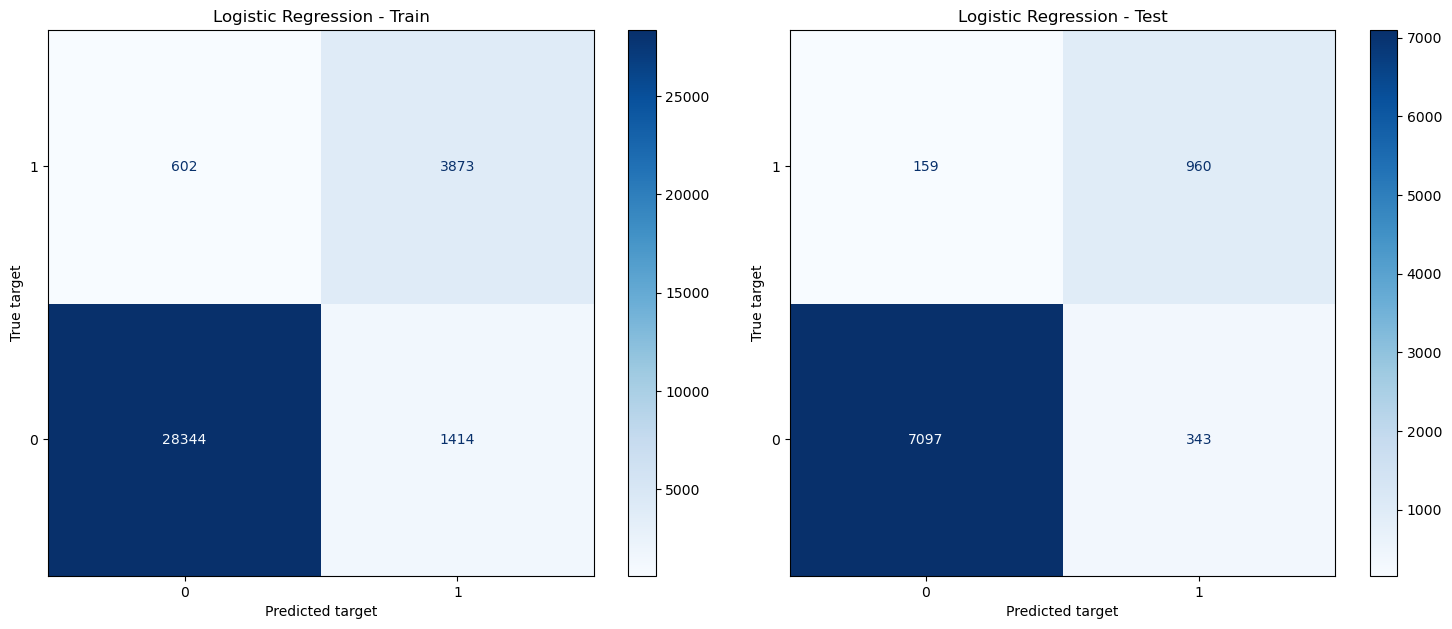

Train data:
Accuracy: 0.941
                  0        1  accuracy  macro avg  weighted avg
precision     0.979    0.733     0.941      0.856         0.947
recall        0.952    0.865     0.941      0.909         0.941
f1-score      0.966    0.793     0.941      0.880         0.943
support   29758.000 4475.000     0.941  34233.000     34233.000


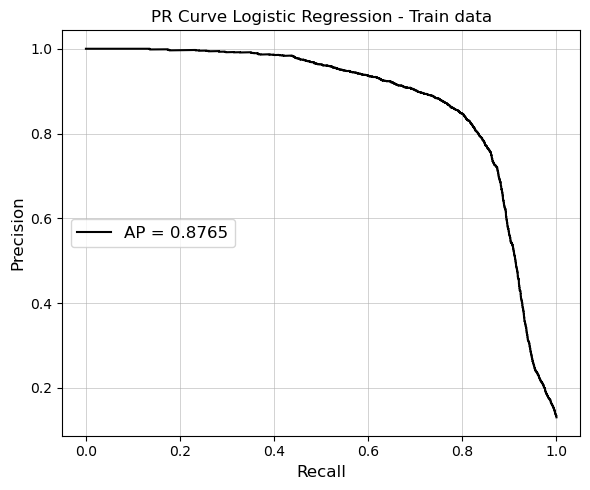


Test data:
Accuracy: 0.941
                 0        1  accuracy  macro avg  weighted avg
precision    0.978    0.737     0.941      0.857         0.947
recall       0.954    0.858     0.941      0.906         0.941
f1-score     0.966    0.793     0.941      0.879         0.943
support   7440.000 1119.000     0.941   8559.000      8559.000


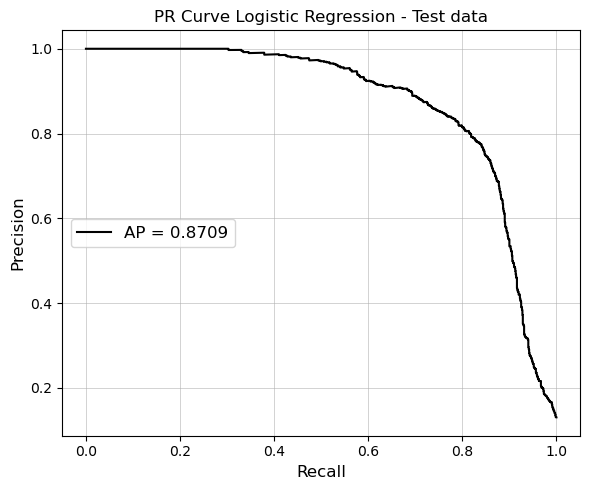

In [87]:
cm_valid_LR, cm_test_LR = hf.display_confusion_matrix(
    y1_true=y_train,
	y1_pred=y_pred_LR_train,
	y2_true=y_test,
	y2_pred=y_pred_LR_test,
	# title='Confusion Matrices - Logistic Regression | Train vs Test',
	model_name='logistic regression',
	cmap='Blues',
	compare=['Train', 'Test']
)
hf.quality_metrics(
    y_true=y_train,
    y_pred=y_pred_LR_train,
    y_probs=y_probs_LR_train[:, 1],
    label='Train data',
    pr_curve_title='PR Curve Logistic Regression - Train data'
)
clf_report_lr_test = hf.quality_metrics(
    y_true=y_test,
	y_pred=y_pred_LR_test,
	y_probs=y_probs_LR_test[:, 1],
	label='\nTest data',
	pr_curve_title='PR Curve Logistic Regression - Test data'
)

In [88]:
from string import capwords # Capitalizing first letter of each string

def transform_eval_res_dict_to_df(clf_report, y_true, y_pred, beta=2):
	# Input is classification_report from sklearn where accuracy is presented in columns while other quality measures are in rows so the
	# function transforms it so every measure name is in row and cols refer to class label
	df = clf_report.loc[['precision', 'recall', 'f1-score'], ['0', '1']]
	accuracy = clf_report['accuracy'].iloc[0]
	columns = pd.MultiIndex.from_product([['Class'], ['0', '1']])
	# Adding Fbeta-score to the table as well
	fbeta_score_neg = hf.fbeta_score(y_true=y_true, y_pred=y_pred, beta=beta, pos_label=0)
	fbeta_score_pos = hf.fbeta_score(y_true=y_true, y_pred=y_pred, beta=beta, pos_label=1)
	df.loc[f'f{beta}-score', '0'] = fbeta_score_neg
	df.loc[f'f{beta}-score', '1'] = fbeta_score_pos
	df.loc['accuracy', :] = accuracy
	df.index = df.index.map(capwords)
	df.columns = columns

	return df

lr_res_table_test = transform_eval_res_dict_to_df(
	clf_report=clf_report_lr_test, 
	y_true=y_test, 
	y_pred=y_pred_LR_test
)
lr_res_table_test

Class     
              0    1
Precision  0.98 0.74
Recall     0.95 0.86
F1-score   0.97 0.79
F2-score   0.96 0.83
Accuracy   0.94 0.94

In [89]:
save_latex_table(
	df=lr_res_table_test, 
	cwd_rel_path='latex_tables/lr_res_table_test.tex', 
	include_index=True, 
	float_format="%.3f"
)

#### Feature importances and SHAP values for Logistic Regression model

Calculating feature importances for Logistic regression model ...


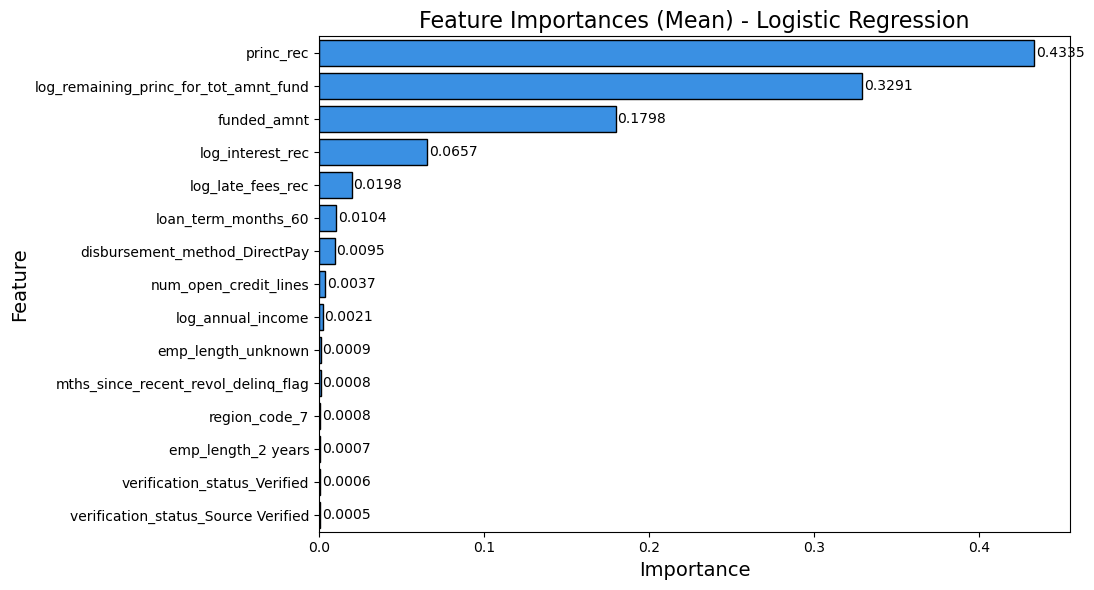

In [90]:
""" Feature importance for Logistic Regression model """
lr_scorer = hf.make_threshold_scorer(
    scoring='fbeta',
    threshold=lr_best_threshold,
	beta=lr_beta
)
lr_feat_names_sorted_desc_by_importance = hf.plot_feature_importances(
    model=log_reg_model,
	model_name='Logistic Regression',
	X_data=X_train,
	y_data=y_train,
	n_reps=5,
	scoring=lr_scorer,
	max_num_features=15,
	n_jobs=-1
)

Calculating SHAP values for Logistic regression model ...
(.values =
array([[ 1.08407086,  0.00934661, -0.00670894, ..., -0.00953802,
         0.20748435, -0.02177185],
       [-0.00940388, -0.1283235 , -0.17154936, ..., -0.00953802,
        -0.03377652, -0.02177185],
       [ 4.14580013,  0.02608786, -0.47488574, ..., -0.00953802,
        -0.03377652, -0.02177185],
       ...,
       [-3.15861113,  0.09857393, -0.04709827, ..., -0.00953802,
        -0.03377652,  0.09918286],
       [ 2.46184903,  0.16856662,  0.01555457, ..., -0.00953802,
        -0.03377652, -0.02177185],
       [-0.88418367,  0.09732724, -0.25120991, ..., -0.00953802,
        -0.03377652,  0.09918286]])

.base_values =
array([-2.87676347, -2.87676347, -2.87676347, ..., -2.87676347,
       -2.87676347, -2.87676347])

.data =
array([[ 0.75      ,  0.0681458 ,  0.20961771, ...,  0.        ,
         1.        ,  0.        ],
       [ 0.33333333, -1.15689382,  0.95789081, ...,  0.        ,
         0.        ,  0.      

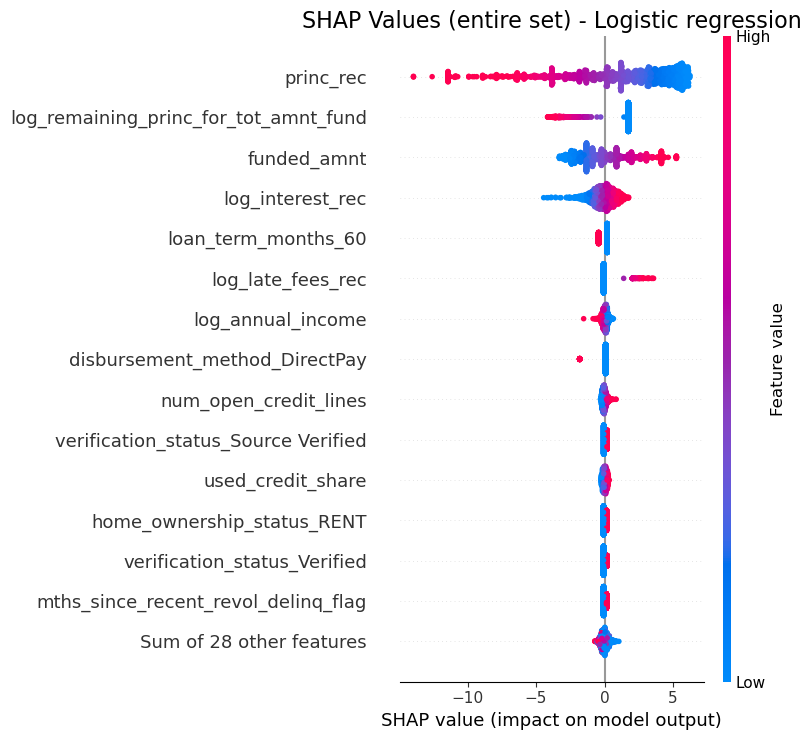

Sample pred: 1


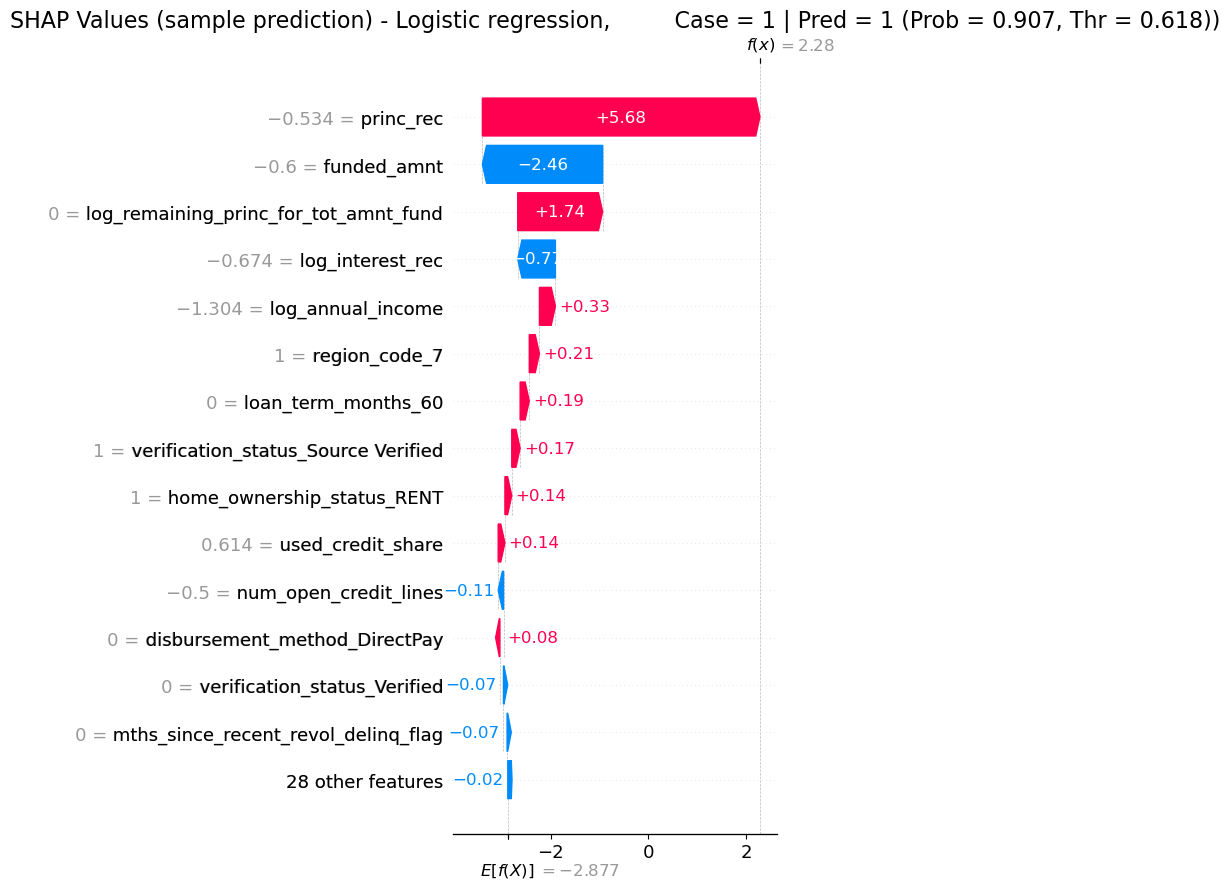

In [91]:
hf.plot_shap_values(
    model=log_reg_model,
    model_name='Logistic Regression',
    X_train=X_train,
    y_train=y_train,
    X_valid=X_train,
    y_valid=y_train,
    threshold=lr_best_threshold,
    random_state=random_state
)

#### PCA Visualization - Logistic Regression

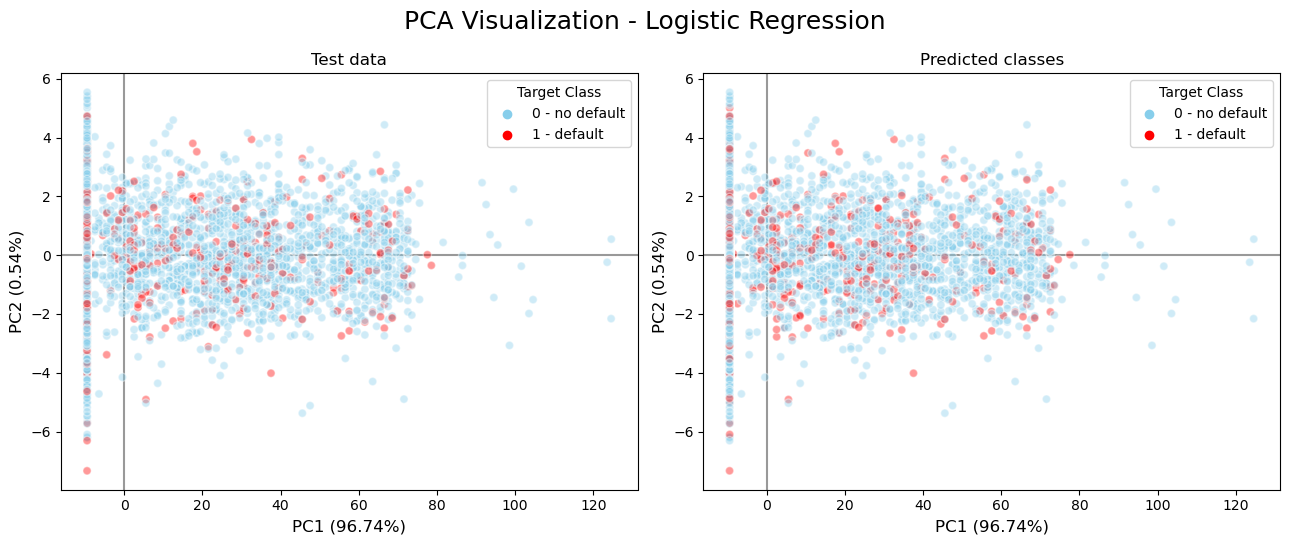

In [92]:
colors_dict = {0: 'skyblue', 1: 'red'}
class_names_dict = {0: 'no default', 1: 'default'}
hf.pca_visualization(
    X_train=X_train,
    X_new=X_test,
    y_new_true=y_test,
    y_new_pred=y_pred_LR_test,
    colors_dict=colors_dict,
    class_names_dict=class_names_dict,
    model_name='Logistic Regression',
    valid_or_test='Test',
    alpha=0.4
)

### XGBoost algorithm

In [93]:
import torch

""" setting device """
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [94]:
import xgboost as xgb

val_counts = y_train.value_counts()
class_freq_ratio = val_counts.loc[0] / val_counts.loc[1]

start_time = time.time()
xgb_model = xgb.XGBClassifier(
    n_estimators=1000,
    learning_rate=0.01,
    min_child_weight=8,
    max_depth=4,
    objective='binary:logistic',
    subsample=0.8,
    # colsample_bytree=0.6,
    eval_metric='logloss',
    scale_pos_weight=class_freq_ratio,
    random_state=random_state
)
xgb_cv_res, xgb_cv_agg_res, xgb_beta = hf.model_cross_validation(
	xgb_model,
	X_train,
	y_train,
    fbeta_param=beta,
	model_name='XGBoost',
	random_state=random_state,
	verbose=False
)
end_time = time.time()
print(f"XGBoost cross validation time: {(end_time - start_time):.2f} seconds")

Cross validation - XGBoost

FOLD 1
Model cloned: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.01, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=8, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=1000,
              n_jobs=None, num_parallel_tree=None, random_state=68, ...)

FOLD 2
Model cloned: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, ea

In [95]:
xgb_model_params = xgb_model.get_params()
xgb_params = pd.DataFrame(index=xgb_model_params.keys(), data=xgb_model_params.values(), columns=['Value'])
xgb_params.index.name = 'Parameter - XGB'

save_latex_table(
	df=xgb_params, 
	cwd_rel_path='latex_tables/xgboost_params.tex', 
	include_index=True, 
	float_format="%0.2f"
)

In [96]:
pd.options.display.float_format = '{:.3f}'.format
xgb_cv_res

,Fold,Best score,Threshold,Precision,Recall,PR AUC,F1-score,F2-score,Accuracy
0,1,0.932,0.431,0.950,0.926,0.964,0.938,0.931,0.984
1,2,0.928,0.409,0.953,0.921,0.961,0.936,0.927,0.984
2,3,0.922,0.389,0.968,0.911,0.958,0.938,0.922,0.984
3,4,0.935,0.366,0.942,0.932,0.966,0.937,0.934,0.984
4,5,0.919,0.376,0.920,0.917,0.957,0.919,0.918,0.979


In [97]:
xgb_cv_agg_res

,Mean,Median,Std
Threshold,0.394,0.389,0.026
Precision,0.947,0.950,0.017
Recall,0.921,0.921,0.008
PR AUC,0.961,0.961,0.004
F1-score,0.934,0.937,0.008
F2-score,0.926,0.927,0.007
Accuracy,0.983,0.984,0.002


In [98]:
""" Save XGBoost cross validation results to latex tables """
save_latex_table(df=xgb_cv_res, cwd_rel_path='latex_tables/xgb_cv_res.tex', include_index=False, float_format="%.3f")
save_latex_table(df=xgb_cv_agg_res, cwd_rel_path='latex_tables/xgb_cv_agg_res.tex', include_index=True, float_format="%.3f")

In [99]:
pd.options.display.float_format = old_format

In [100]:
X_train_xgb, X_valid_xgb, y_train_xgb, y_valid_xgb = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    stratify=y_train
)
# Setting early stopping for fitting final model, in the cross validation there was no early stopping included
xgb_model.early_stopping_rounds = 50
xgb_model.fit(
    X=X_train_xgb,
    y=y_train_xgb,
    eval_set=[(X_valid_xgb, y_valid_xgb)],
    verbose=50
)

[0]	validation_0-logloss:0.68645
[50]	validation_0-logloss:0.45913
[100]	validation_0-logloss:0.34040
[150]	validation_0-logloss:0.27029
[200]	validation_0-logloss:0.22452
[250]	validation_0-logloss:0.19499
[300]	validation_0-logloss:0.17593
[350]	validation_0-logloss:0.16159
[400]	validation_0-logloss:0.15147
[450]	validation_0-logloss:0.14285
[500]	validation_0-logloss:0.13632
[550]	validation_0-logloss:0.13104
[600]	validation_0-logloss:0.12623
[650]	validation_0-logloss:0.12250
[700]	validation_0-logloss:0.11982
[750]	validation_0-logloss:0.11701
[800]	validation_0-logloss:0.11448
[850]	validation_0-logloss:0.11214
[900]	validation_0-logloss:0.11038
[950]	validation_0-logloss:0.10886
[999]	validation_0-logloss:0.10722


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,50
,enable_categorical,False
,eval_metric,'logloss'


In [101]:
# Probabilities
y_probs_XGB_train = xgb_model.predict_proba(X_train_xgb)
y_probs_XGB_test = xgb_model.predict_proba(X_test)

# Obtaining best threshold for XGBoost based on recall
xgb_best_threshold = xgb_cv_agg_res.loc['Threshold', 'Median']

# Predictions (labels)
y_pred_XGB_train = np.where(y_probs_XGB_train[:, 1] > xgb_best_threshold, 1, 0) # xgb_model.predict(X_train)
y_pred_XGB_test = np.where(y_probs_XGB_test[:, 1] > xgb_best_threshold, 1, 0) # xgb_model.predict(X_test)

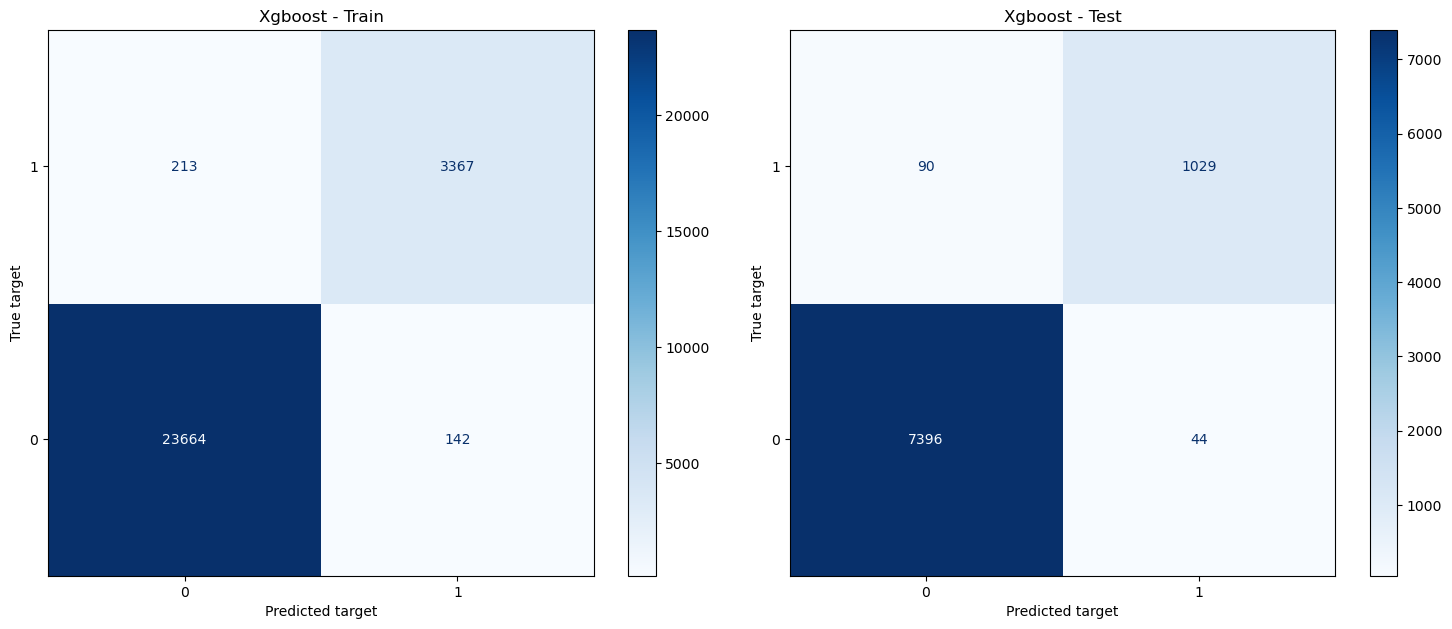

Train data:
Accuracy: 0.987
                  0        1  accuracy  macro avg  weighted avg
precision     0.991    0.960     0.987      0.975         0.987
recall        0.994    0.941     0.987      0.967         0.987
f1-score      0.993    0.950     0.987      0.971         0.987
support   23806.000 3580.000     0.987  27386.000     27386.000


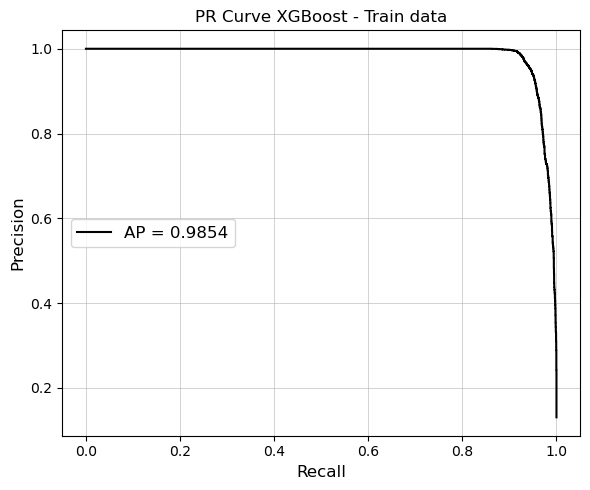


Test data:
Accuracy: 0.984
                 0        1  accuracy  macro avg  weighted avg
precision    0.988    0.959     0.984      0.973         0.984
recall       0.994    0.920     0.984      0.957         0.984
f1-score     0.991    0.939     0.984      0.965         0.984
support   7440.000 1119.000     0.984   8559.000      8559.000


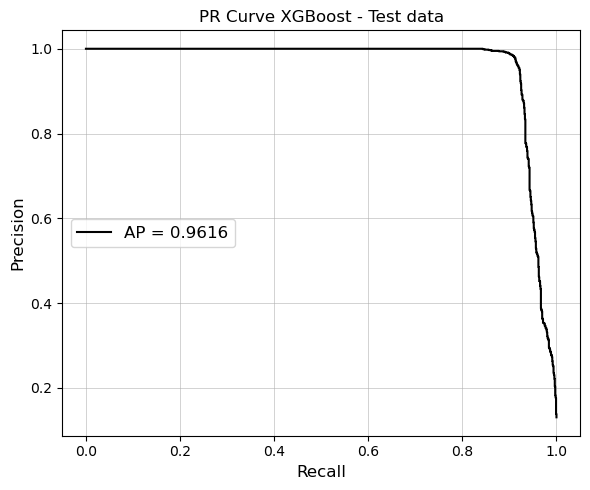

In [102]:
cm_valid_XGB, cm_test_XGB = hf.display_confusion_matrix(
    y1_true=y_train_xgb,
    y1_pred=y_pred_XGB_train,
    y2_true=y_test,
    y2_pred=y_pred_XGB_test,
    # title='Confusion Matrices - XGBoost | Train vs Test',
    model_name='xgboost',
    cmap="Blues",
    compare=['Train', 'Test']
)
hf.quality_metrics(
    y_true=y_train_xgb,
    y_pred=y_pred_XGB_train,
    y_probs=y_probs_XGB_train[:, 1],
    label='Train data',
    pr_curve_title='PR Curve XGBoost - Train data'
)
clf_report_xgb_test = hf.quality_metrics(
    y_true=y_test,
    y_pred=y_pred_XGB_test,
    y_probs=y_probs_XGB_test[:, 1],
    label='\nTest data',
    pr_curve_title='PR Curve XGBoost - Test data'
)

In [103]:
xgb_res_table_test = transform_eval_res_dict_to_df(
    clf_report=clf_report_xgb_test,
    y_true=y_test,
	y_pred=y_pred_XGB_test
)
xgb_res_table_test

Class     
              0    1
Precision  0.99 0.96
Recall     0.99 0.92
F1-score   0.99 0.94
F2-score   0.99 0.93
Accuracy   0.98 0.98

In [104]:
save_latex_table(
	df=xgb_res_table_test, 
	cwd_rel_path='latex_tables/xgb_res_table_test.tex', 
	include_index=True, 
	float_format="%.3f"
)

#### Visualizing decision trees, feature importances and SHAP values for XGBoost model

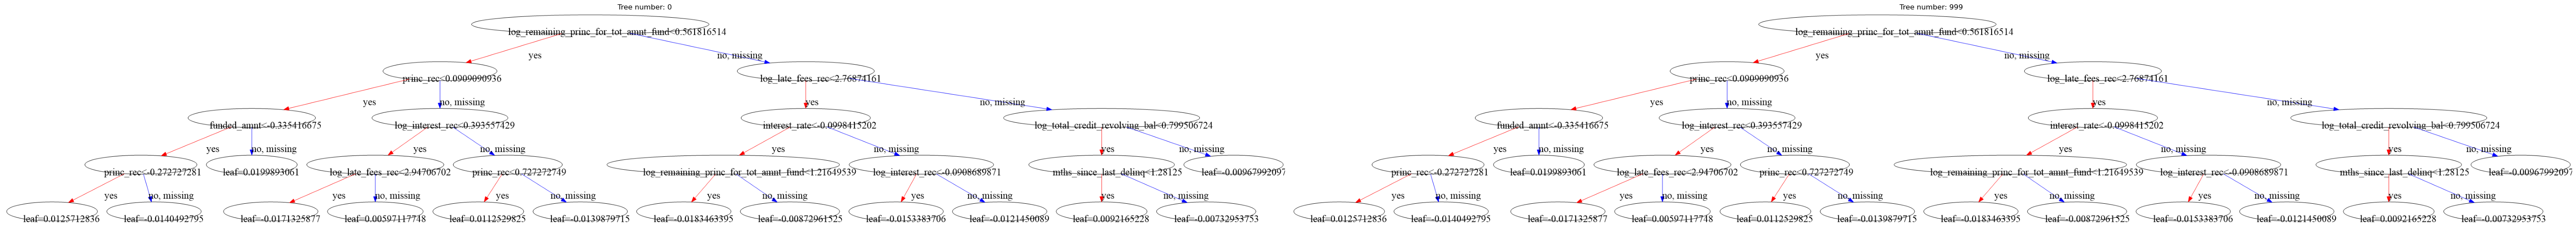

In [105]:
""" Plots decision trees for XGBoost model for chosen tree indices (first and last tree) """
tree_indices = [0, xgb_model.best_iteration]
fig, axes = plt.subplots(1, len(tree_indices), figsize=(60, 80))
axes = axes.flatten()
for tree_i, ax in zip(tree_indices, axes):
    xgb.plot_tree(
        booster=xgb_model,
        tree_idx=tree_i,
        ax=ax
    )
    ax.set_title(f'Tree number: {tree_i}')
plt.tight_layout()
plt.show()

Calculating feature importances for Xgboost model ...


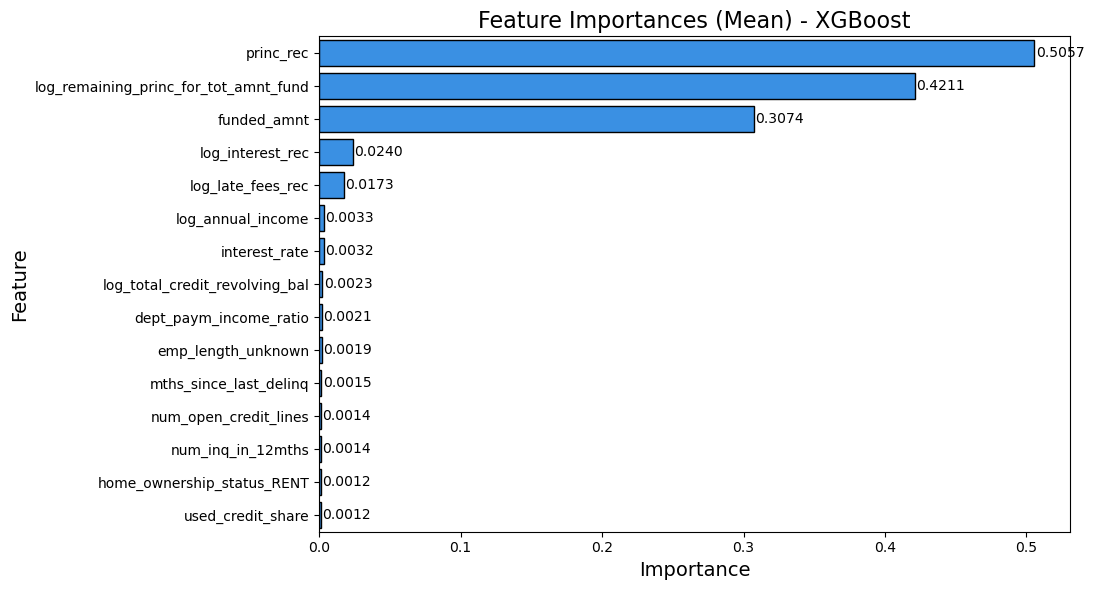

In [106]:
""" Feature importances for XGBoost model """
xgb_scorer = hf.make_threshold_scorer(
    scoring='fbeta',
    threshold=xgb_best_threshold,
    beta=xgb_beta
)
xgb_feat_names_sorted_desc_by_importance = hf.plot_feature_importances(
    model=xgb_model,
    model_name='XGBoost',
    X_data=X_train_xgb,
    y_data=y_train_xgb,
    n_reps=5,
    scoring=xgb_scorer,
    max_num_features=15,
    n_jobs=-1
)

Calculating SHAP values for Xgboost model ...
(.values =
array([[-8.0783093e-01, -6.3722320e-02,  2.6791083e-02, ...,
         2.9260223e-04, -9.8020455e-04,  7.6054312e-02],
       [-2.4917116e+00,  2.4480605e-02, -1.9771317e-02, ...,
         8.1260951e-06, -1.4352287e-03, -3.1902632e-03],
       [ 7.6785225e-01, -1.9898847e-02, -3.5656325e-03, ...,
        -1.0542226e-03, -1.6317666e-03, -2.7733136e-03],
       ...,
       [ 4.7136053e-01,  1.4341496e-01, -3.5361342e-02, ...,
         3.3799309e-04, -8.9288614e-04, -9.1638323e-03],
       [-8.9842565e-02,  2.1529453e-02,  5.5513214e-03, ...,
        -8.2850468e-04, -1.6848850e-03,  9.5203398e-03],
       [ 2.3431473e+00, -1.0913238e-02, -1.8655743e-02, ...,
        -5.2012777e-04, -8.3756907e-04, -2.7568268e-03]], dtype=float32)

.base_values =
array([0.04722018, 0.04722018, 0.04722018, ..., 0.04722018, 0.04722018,
       0.04722018], dtype=float32)

.data =
array([[-0.625     , -0.50554675,  1.40830547, ...,  0.        ,
         0

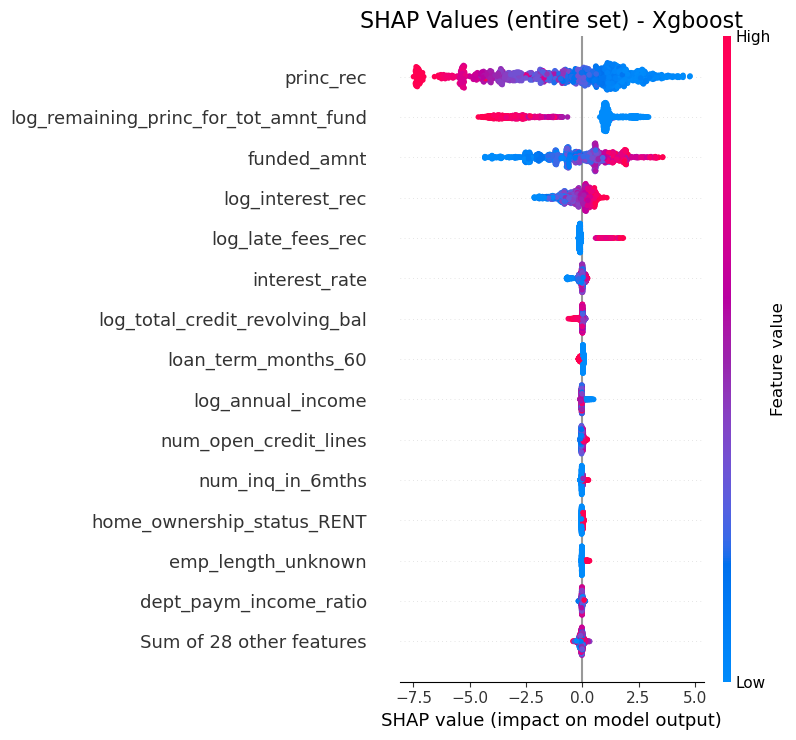

Sample pred: 1


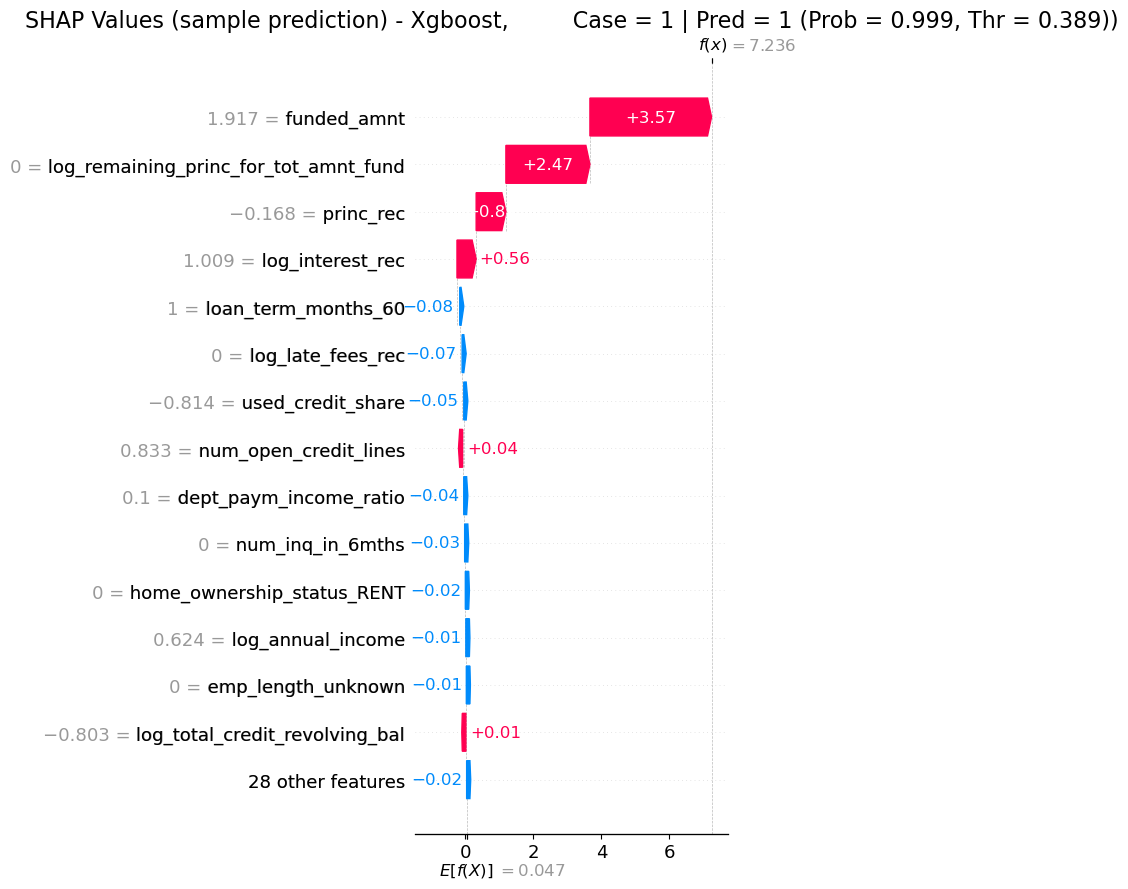

In [107]:
hf.plot_shap_values(
    model=xgb_model,
    model_name='XGBoost',
    X_train=X_train_xgb,
    y_train=y_train_xgb,
    X_valid=X_train_xgb,
    y_valid=y_train_xgb,
    threshold=xgb_best_threshold,
    random_state=random_state
)

#### PCA Visualization - XGBoost

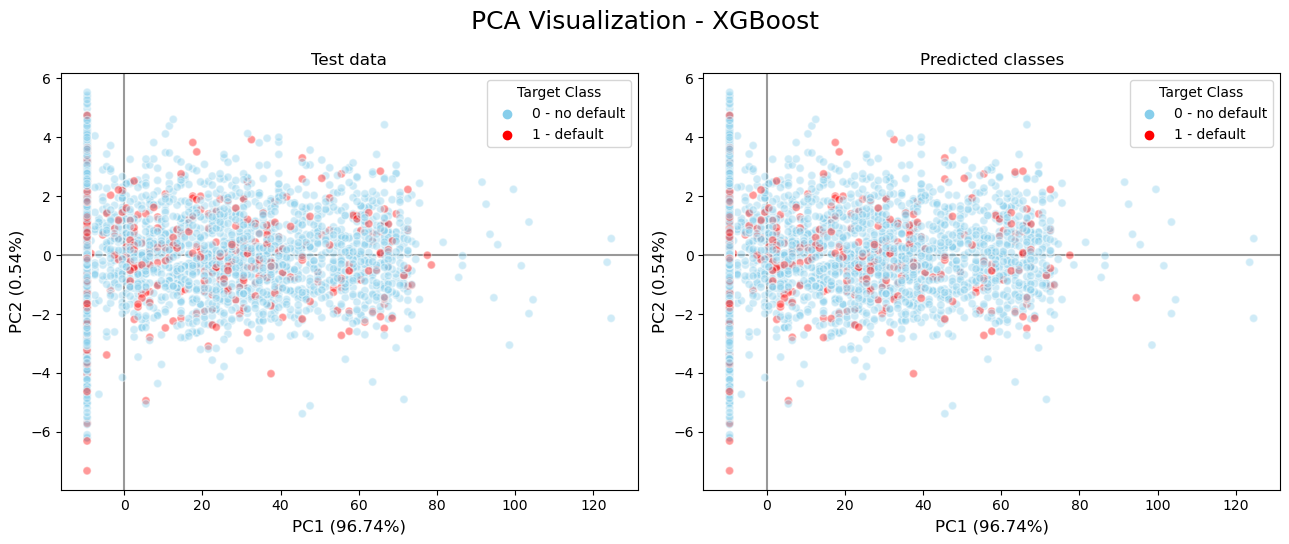

In [108]:
hf.pca_visualization(
    X_train=X_train_xgb,
    X_new=X_test,
    y_new_true=y_test,
    y_new_pred=y_pred_XGB_test,
    colors_dict=colors_dict,
    class_names_dict=class_names_dict,
    model_name='XGBoost',
    valid_or_test='Test',
	alpha=0.4
)

### Random Forest Classifier

In [109]:
val_counts

target
0    29758
1     4475
Name: count, dtype: int64

In [110]:
from sklearn.ensemble import RandomForestClassifier

start_time = time.time()
rf_model = RandomForestClassifier(
    n_estimators=200,
    criterion='gini',
    class_weight='balanced_subsample',
    max_depth=20,
    min_samples_leaf=4,
    random_state=random_state,
    n_jobs=-1
)
rf_cv_res, rf_cv_agg_res, rf_beta = hf.model_cross_validation(
	rf_model,
	X_train,
	y_train,
    fbeta_param=beta,
	model_name='Random Forest',
	random_state=random_state,
	verbose=False
)
end_time = time.time()
print(f"Random Forest cross validation time: {(end_time - start_time):.2f} seconds")

Cross validation - Random Forest

FOLD 1
Model cloned: RandomForestClassifier(class_weight='balanced_subsample', max_depth=20,
                       min_samples_leaf=4, n_estimators=200, n_jobs=-1,
                       random_state=68)

FOLD 2
Model cloned: RandomForestClassifier(class_weight='balanced_subsample', max_depth=20,
                       min_samples_leaf=4, n_estimators=200, n_jobs=-1,
                       random_state=68)

FOLD 3
Model cloned: RandomForestClassifier(class_weight='balanced_subsample', max_depth=20,
                       min_samples_leaf=4, n_estimators=200, n_jobs=-1,
                       random_state=68)

FOLD 4
Model cloned: RandomForestClassifier(class_weight='balanced_subsample', max_depth=20,
                       min_samples_leaf=4, n_estimators=200, n_jobs=-1,
                       random_state=68)

FOLD 5
Model cloned: RandomForestClassifier(class_weight='balanced_subsample', max_depth=20,
                       min_samples_leaf=4, n_esti

In [111]:
rf_model_params = rf_model.get_params()
rf_params = pd.DataFrame(index=rf_model_params.keys(), data=rf_model_params.values(), columns=['Value'])
rf_params.index.name = 'Parameter - RF'

save_latex_table(
	df=rf_params, 
	cwd_rel_path='latex_tables/random_forest_params.tex', 
	include_index=True, 
	float_format="%0.2f"
)

In [112]:
pd.options.display.float_format = '{:.3f}'.format
rf_cv_res

,Fold,Best score,Threshold,Precision,Recall,PR AUC,F1-score,F2-score,Accuracy
0,1,0.889,0.314,0.833,0.903,0.938,0.866,0.888,0.964
1,2,0.869,0.365,0.864,0.869,0.929,0.867,0.868,0.965
2,3,0.878,0.334,0.874,0.878,0.931,0.876,0.877,0.968
3,4,0.889,0.302,0.807,0.911,0.941,0.856,0.888,0.960
4,5,0.875,0.338,0.827,0.887,0.931,0.856,0.874,0.961


In [113]:
rf_cv_agg_res

,Mean,Median,Std
Threshold,0.330,0.334,0.024
Precision,0.841,0.833,0.028
Recall,0.890,0.887,0.017
PR AUC,0.934,0.931,0.005
F1-score,0.864,0.866,0.009
F2-score,0.879,0.877,0.009
Accuracy,0.963,0.964,0.003


In [114]:
""" Save Random Forest cross validation results to latex tables """
save_latex_table(
    df=rf_cv_res, 
    cwd_rel_path='latex_tables/rf_cv_res.tex',
    include_index=False, 
    float_format="%.3f"
)
save_latex_table(
    df=rf_cv_agg_res, 
    cwd_rel_path='latex_tables/rf_cv_agg_res.tex', 
    include_index=True, 
    float_format="%.3f"
)

In [115]:
pd.options.display.float_format = old_format

In [116]:
rf_model.fit(
    X=X_train,
    y=y_train
)

,n_estimators,200
,criterion,'gini'
,max_depth,20
,min_samples_split,2
,min_samples_leaf,4
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [117]:
y_probs_RF_train = rf_model.predict_proba(X_train)
y_probs_RF_test = rf_model.predict_proba(X_test)

# Obtaining best threshold for Random Forest based on recall
rf_best_threshold = rf_cv_agg_res.loc['Threshold', 'Median']

# Predictions (labels)
y_pred_RF_train = np.where(y_probs_RF_train[:, 1] > rf_best_threshold, 1, 0) # rf_model.predict(X_train)
y_pred_RF_test = np.where(y_probs_RF_test[:, 1] > rf_best_threshold, 1, 0) # rf_model.predict(X_test)

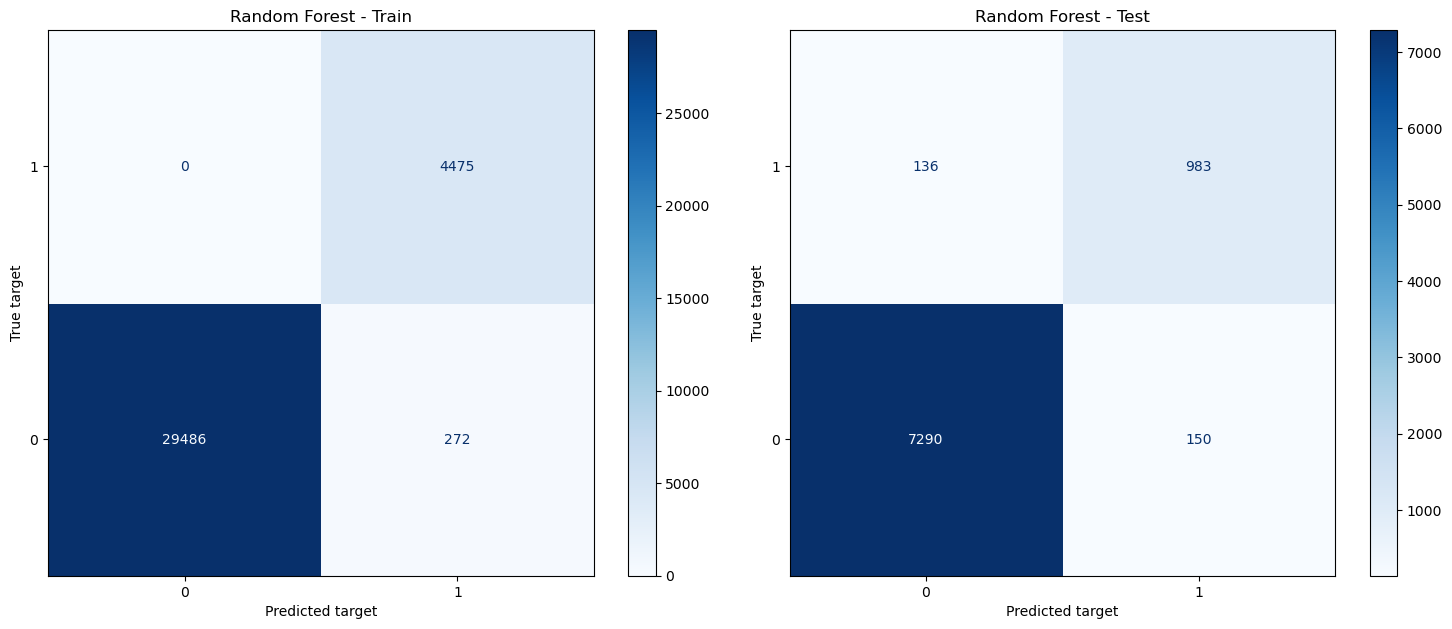

Train data:
Accuracy: 0.992
                  0        1  accuracy  macro avg  weighted avg
precision     1.000    0.943     0.992      0.971         0.993
recall        0.991    1.000     0.992      0.995         0.992
f1-score      0.995    0.971     0.992      0.983         0.992
support   29758.000 4475.000     0.992  34233.000     34233.000


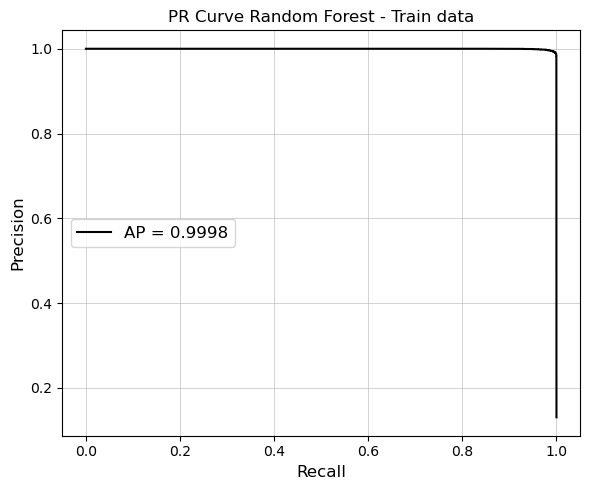


Test data:
Accuracy: 0.967
                 0        1  accuracy  macro avg  weighted avg
precision    0.982    0.868     0.967      0.925         0.967
recall       0.980    0.878     0.967      0.929         0.967
f1-score     0.981    0.873     0.967      0.927         0.967
support   7440.000 1119.000     0.967   8559.000      8559.000


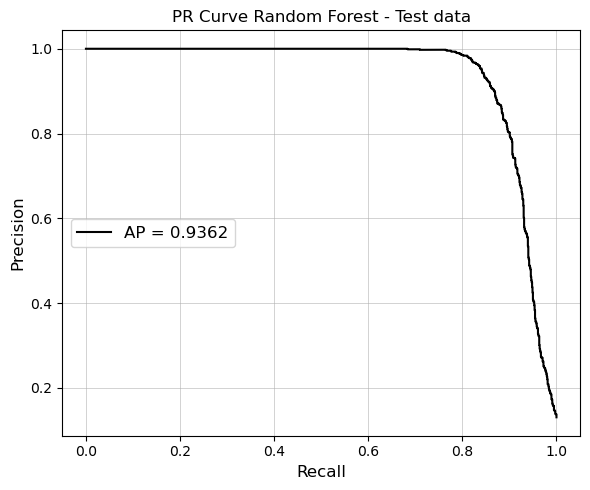

In [118]:
cm_train_RF, cm_test_RF = hf.display_confusion_matrix(
    y1_true=y_train,
	y1_pred=y_pred_RF_train,
	y2_true=y_test,
	y2_pred=y_pred_RF_test,
	# title='Confusion Matrices - Random Forest | Train vs Test',
	model_name='random forest',
	cmap="Blues",
	compare=['Train', 'Test']
)
hf.quality_metrics(
    y_true=y_train,
	y_pred=y_pred_RF_train,
	y_probs=y_probs_RF_train[:, 1],
	label='Train data',
	pr_curve_title='PR Curve Random Forest - Train data'
)
clf_report_rf_test = hf.quality_metrics(
    y_true=y_test,
	y_pred=y_pred_RF_test,
	y_probs=y_probs_RF_test[:, 1],
	label='\nTest data',
	pr_curve_title='PR Curve Random Forest - Test data'
)

In [119]:
rf_res_table_test = transform_eval_res_dict_to_df(
    clf_report=clf_report_rf_test,
    y_true=y_test,
	y_pred=y_pred_RF_test
)
rf_res_table_test

Class     
              0    1
Precision  0.98 0.87
Recall     0.98 0.88
F1-score   0.98 0.87
F2-score   0.98 0.88
Accuracy   0.97 0.97

In [120]:
save_latex_table(
    df=rf_res_table_test, 
	cwd_rel_path='latex_tables/rf_res_table_test.tex', 
	include_index=True, 
	float_format="%.3f"
)

#### Visualizing decision trees, feature importances and SHAP values for Random Forest model

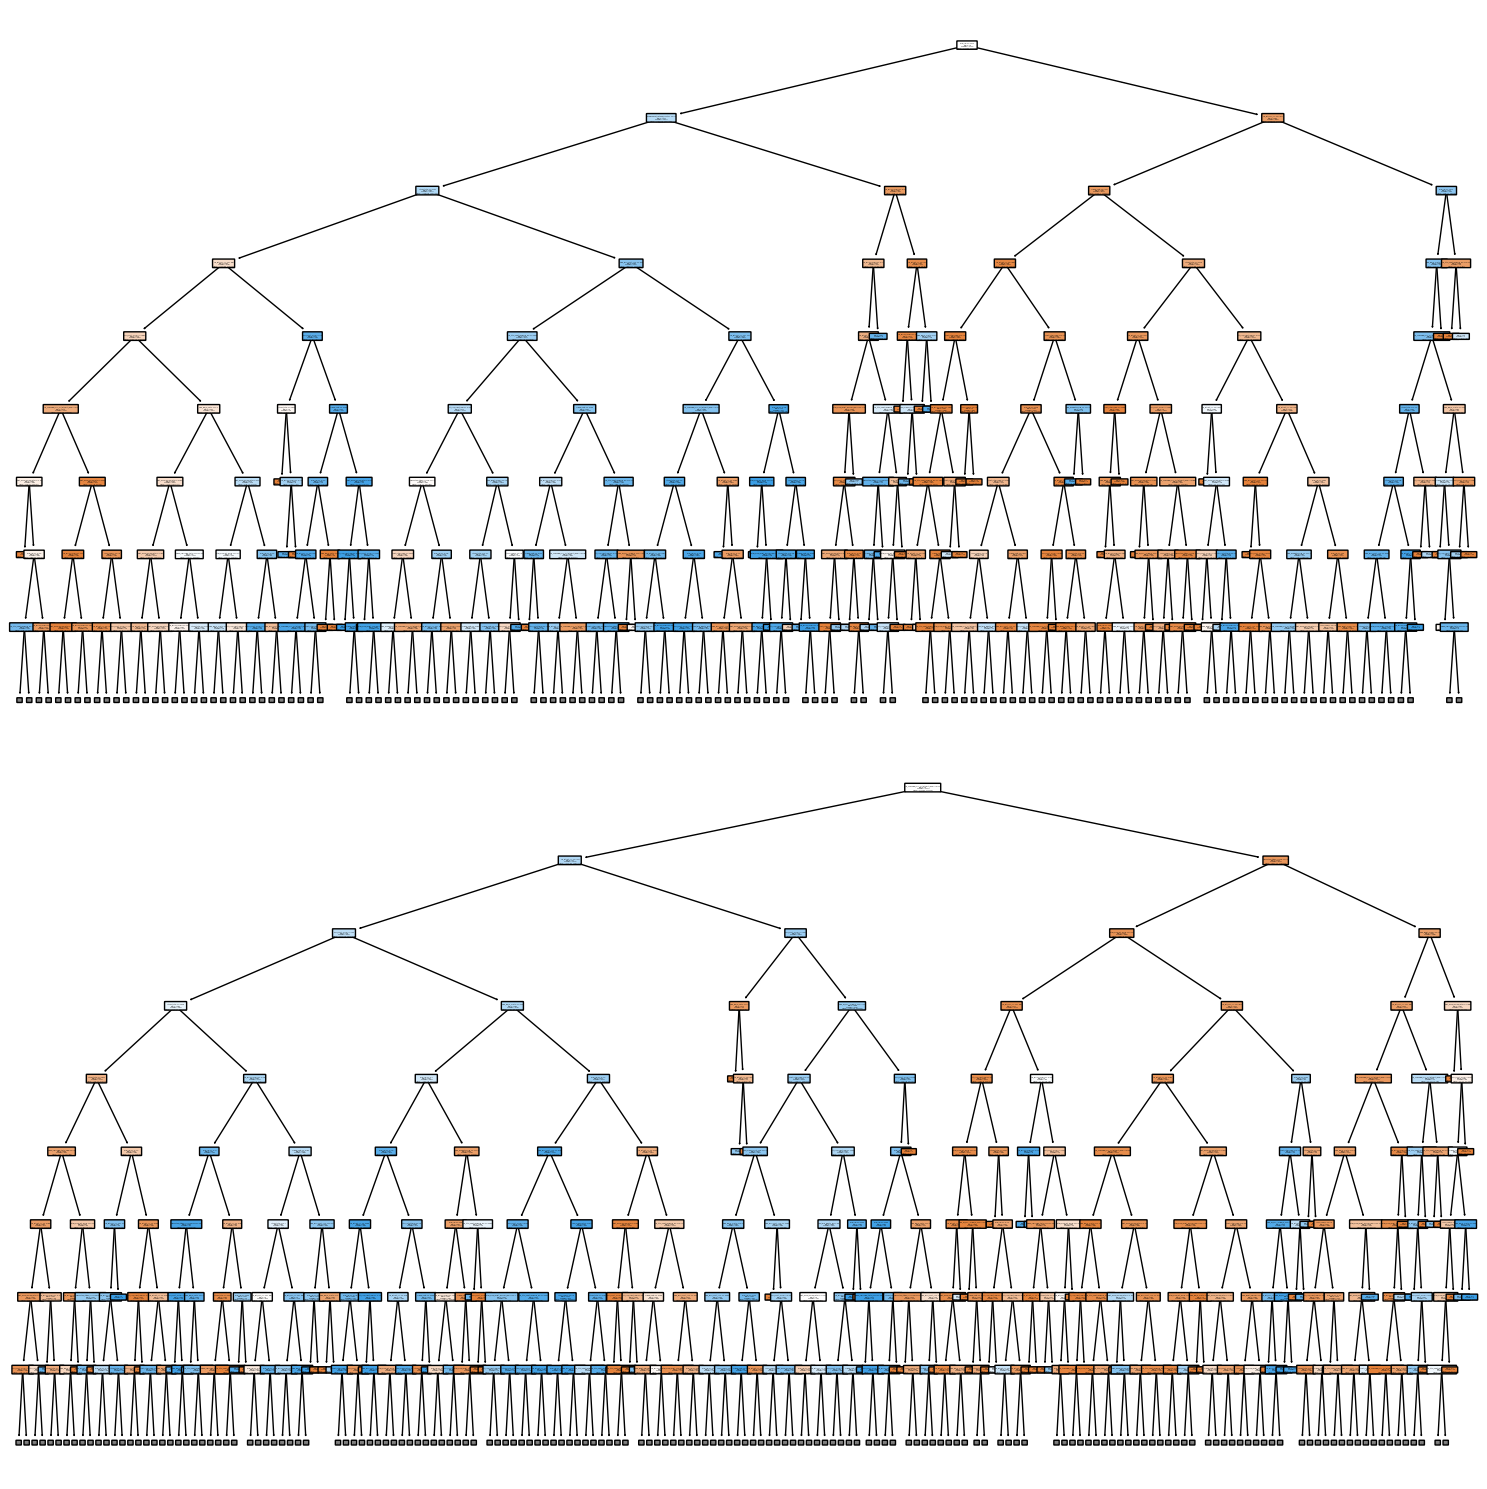

In [121]:
from sklearn import tree

""" Plots decision trees for Random Forest model for chosen tree indices (first and last tree) """
estimators_to_plot = [0, -1] # first and last trees in the forest
fig, axes = plt.subplots(len(estimators_to_plot), 1, figsize=(15, 15))
axes = axes.flatten()
max_depth = 8
for tree_i, ax in zip(estimators_to_plot, axes):
    tree.plot_tree(
		decision_tree=rf_model.estimators_[tree_i],
		feature_names=rf_model.feature_names_in_,
		class_names=rf_model.classes_.astype(str),
		filled=True,
		rounded=True,
		ax=ax,
		max_depth=max_depth
    )
plt.tight_layout()
plt.show()

Calculating feature importances for Random forest model ...


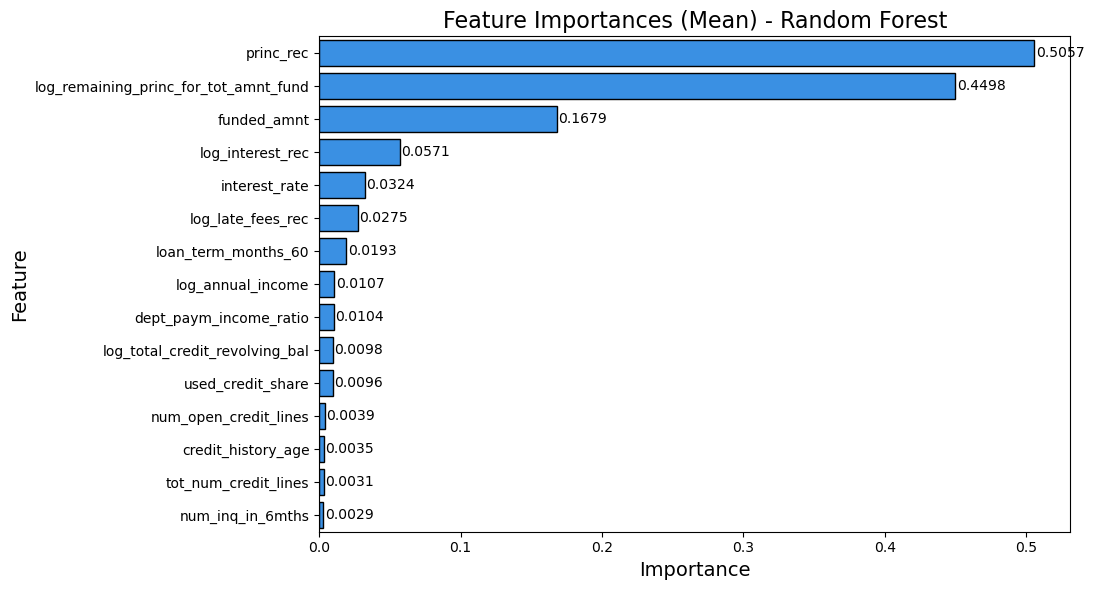

In [122]:
"""Feature importances for Random Forest model"""
rf_scorer = hf.make_threshold_scorer(
    scoring='fbeta',
	threshold=rf_best_threshold,
	beta=rf_beta
)
rf_feat_names_sorted_desc_by_importance = hf.plot_feature_importances(
	model=rf_model,
	model_name='Random Forest',
	X_data=X_train,
	y_data=y_train,
	n_reps=5,
	scoring=rf_scorer,
	max_num_features=15,
	n_jobs=1
)

Calculating SHAP values for Random forest model ...
(.values =
array([[[-1.67036962e-02,  1.67036962e-02],
        [-4.58429306e-03,  4.58429306e-03],
        [ 7.52260937e-03, -7.52260937e-03],
        ...,
        [ 1.09265588e-03, -1.09265588e-03],
        [-2.80063306e-03,  2.80063306e-03],
        [ 2.41139275e-04, -2.41139275e-04]],

       [[-4.53945674e-04,  4.53945674e-04],
        [ 8.80812564e-02, -8.80812564e-02],
        [ 1.85633121e-02, -1.85633121e-02],
        ...,
        [ 4.54086243e-04, -4.54086243e-04],
        [ 1.09439603e-03, -1.09439603e-03],
        [ 2.57825092e-04, -2.57825092e-04]],

       [[-3.31187214e-02,  3.31187214e-02],
        [-6.67136766e-03,  6.67136766e-03],
        [ 2.08875046e-02, -2.08875046e-02],
        ...,
        [ 6.65343883e-04, -6.65343883e-04],
        [ 1.30748134e-03, -1.30748134e-03],
        [ 3.14518543e-04, -3.14518543e-04]],

       ...,

       [[ 1.98622128e-01, -1.98622128e-01],
        [-2.95784919e-02,  2.95784919e-02],

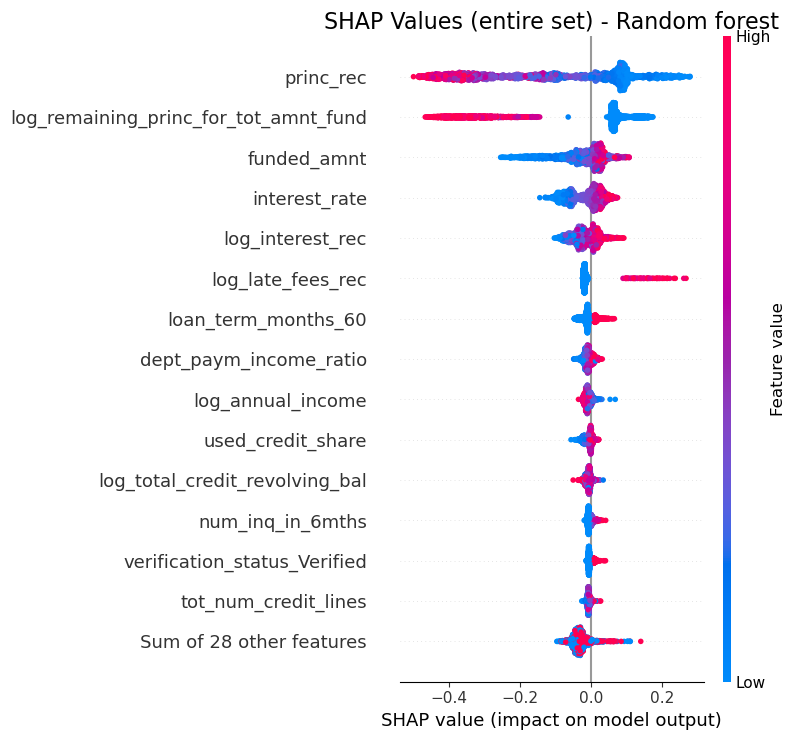

Sample pred: 1


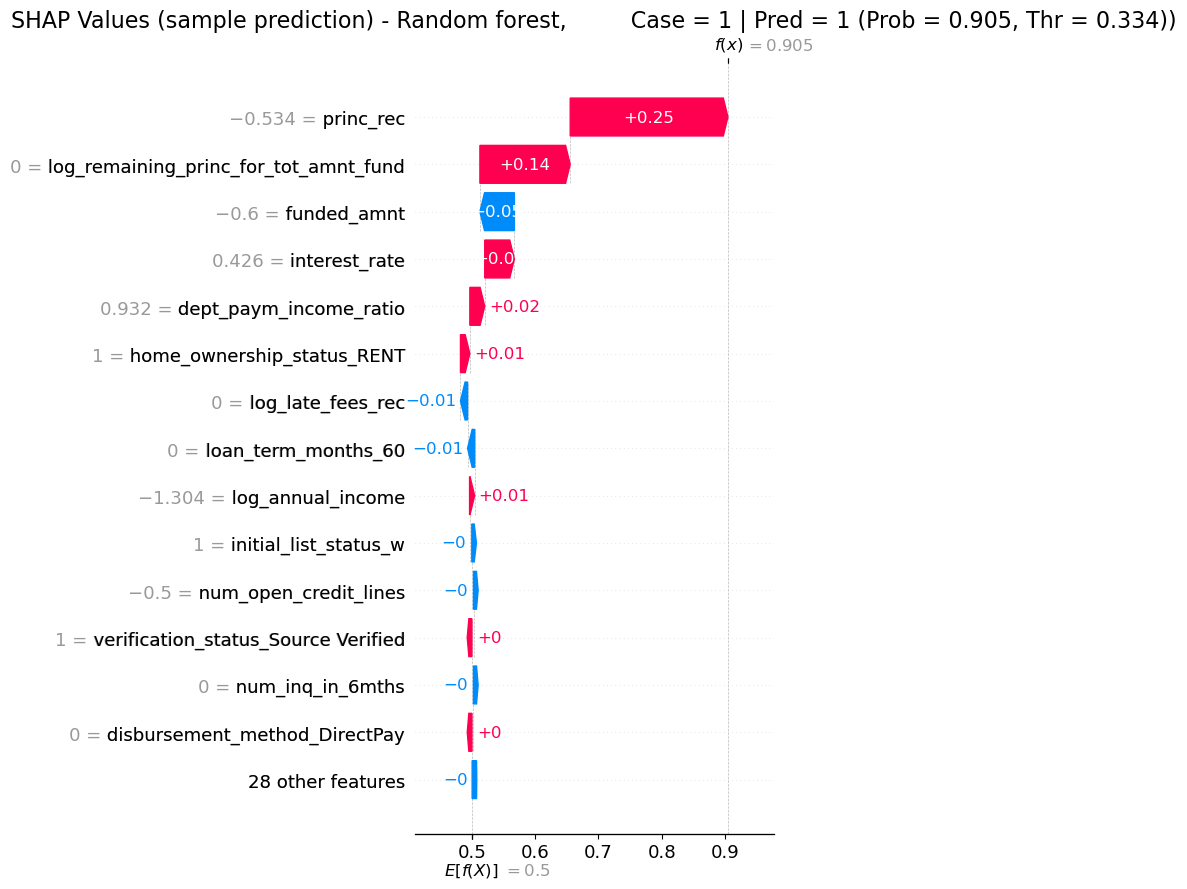

In [123]:
hf.plot_shap_values(
	model=rf_model,
	model_name='Random Forest',
	X_train=X_train,
	y_train=y_train,
	X_valid=X_train,
	y_valid=y_train,
	threshold=rf_best_threshold,
	random_state=random_state
)

#### PCA Visualization - Random Forest

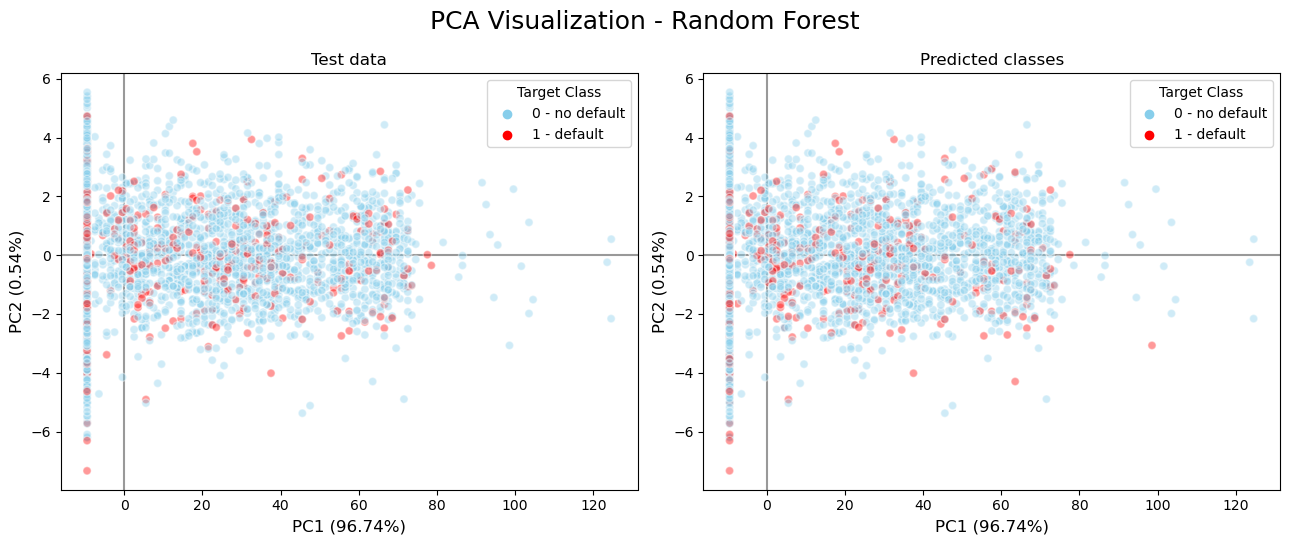

In [124]:
hf.pca_visualization(
	X_train=X_train,
	X_new=X_test,
	y_new_true=y_test,
	y_new_pred=y_pred_RF_test,
	colors_dict=colors_dict,
	class_names_dict=class_names_dict,
	model_name='Random Forest',
	valid_or_test='Test',
	alpha=0.4
)

### Neural Network

Training Neural Network model and validation on validation data

In [125]:
from nn_for_classification import NeuralNetClassifier
from sklearn.utils.class_weight import compute_class_weight

# Computing class weights to handle class imbalance in the target variable for Neural Network model
class_weights = compute_class_weight(
	class_weight='balanced',
	classes=np.unique(y_train),
	y=y_train
)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

start_time = time.time()
nn_model = NeuralNetClassifier(
	hidden_layers_sizes=[64],
	dropout_prob=0.2,
	class_weights=class_weights,
	learning_rate=0.001,
	validation_split=0.2,
	epochs=2000,
	regularization_type='L2',
	lambda_reg=0.001,
	patience=50,
	random_state=random_state,
	device=device
)
nn_cv_res, nn_cv_agg_res, nn_beta = hf.model_cross_validation(
	nn_model,
	X_train,
	y_train,
    fbeta_param=beta,
	model_name='Neural Network',
	random_state=random_state,
	verbose=False
)
end_time = time.time()
print(f"\nNeural network cross validation time: {(end_time - start_time):.2f} seconds")

Cross validation - Neural Network

FOLD 1
Model cloned: NeuralNetClassifier(class_weights=tensor([0.5752, 3.8249], device='cuda:0'),
                    device='cuda', epochs=2000, hidden_layers_sizes=[64],
                    lambda_reg=0.001, patience=50, regularization_type='L2')
Epoch: 100 | Train loss: 0.36518 | Valid loss: 0.31280 | Train PR AUC: 0.87013 | Valid PR AUC: 0.88392
Epoch: 200 | Train loss: 0.22937 | Valid loss: 0.17142 | Train PR AUC: 0.94881 | Valid PR AUC: 0.94872
Epoch: 300 | Train loss: 0.20337 | Valid loss: 0.15764 | Train PR AUC: 0.95896 | Valid PR AUC: 0.95257
Epoch: 400 | Train loss: 0.18321 | Valid loss: 0.15505 | Train PR AUC: 0.96670 | Valid PR AUC: 0.95332
Epoch: 500 | Train loss: 0.17674 | Valid loss: 0.14966 | Train PR AUC: 0.96740 | Valid PR AUC: 0.95488
Epoch: 600 | Train loss: 0.16677 | Valid loss: 0.14888 | Train PR AUC: 0.97041 | Valid PR AUC: 0.95549
Early stopping at epoch 639 ...

Epoch: 639 | Train loss: 0.16601 | Valid loss: 0.14748 | Train PR

In [126]:
print(class_weights[1] / class_weights[0])

tensor(6.6498, device='cuda:0')


In [127]:
nn_model_params = nn_model.get_params()
nn_model_params

{'class_weights': tensor([0.5752, 3.8249], device='cuda:0'),
 'device': 'cuda',
 'dropout_prob': 0.2,
 'epochs': 2000,
 'hidden_layers_sizes': [64],
 'lambda_reg': 0.001,
 'learning_rate': 0.001,
 'optimizer': None,
 'patience': 50,
 'random_state': 68,
 'regularization_type': 'L2',
 'validation_split': 0.2}

In [128]:
# Converting class_weights to list to make it possible to read 
nn_model_params['class_weights'] = nn_model_params['class_weights'].tolist()

In [129]:
nn_params = pd.DataFrame(index=list(nn_model_params.keys())[1:], data=list(nn_model_params.values())[1:], columns=['Value'])
nn_params.index.name = 'Parameter - NN'

save_latex_table(
	df=nn_params, 
	cwd_rel_path='latex_tables/neural_network_params.tex', 
	include_index=True, 
	float_format="%0.3f"
)

In [130]:
pd.options.display.float_format = '{:.3f}'.format
nn_cv_res

,Fold,Best score,Threshold,Precision,Recall,PR AUC,F1-score,F2-score,Accuracy
0,1,0.920,0.470,0.909,0.922,0.959,0.915,0.919,0.978
1,2,0.918,0.515,0.935,0.913,0.955,0.924,0.917,0.980
2,3,0.911,0.498,0.949,0.901,0.953,0.924,0.910,0.981
3,4,0.921,0.488,0.924,0.920,0.959,0.922,0.920,0.980
4,5,0.911,0.471,0.910,0.911,0.951,0.910,0.910,0.976


In [131]:
nn_cv_agg_res

,Mean,Median,Std
Threshold,0.488,0.488,0.019
Precision,0.925,0.924,0.017
Recall,0.913,0.913,0.008
PR AUC,0.955,0.955,0.003
F1-score,0.919,0.922,0.006
F2-score,0.915,0.917,0.005
Accuracy,0.979,0.980,0.002


In [132]:
""" Save Neural Network cross validation results to latex tables """
save_latex_table(
    df=nn_cv_res, 
    cwd_rel_path='latex_tables/nn_cv_res.tex', 
    include_index=False, 
    float_format="%.3f"
)
save_latex_table(
	df=nn_cv_agg_res, 
	cwd_rel_path='latex_tables/nn_cv_agg_res.tex', 
	include_index=True, 
	float_format="%.3f"
)

In [133]:
pd.options.display.float_format = old_format

In [134]:
""" 
Neural Network model is trained on the whole training set with validation split inside the fit method for early stopping purposes
"""
nn_model.fit(
    X=X_train,
    y=y_train
)

Epoch: 100 | Train loss: 0.42965 | Valid loss: 0.38363 | Train PR AUC: 0.76756 | Valid PR AUC: 0.78860
Epoch: 200 | Train loss: 0.23825 | Valid loss: 0.18570 | Train PR AUC: 0.94928 | Valid PR AUC: 0.94520
Epoch: 300 | Train loss: 0.21143 | Valid loss: 0.16922 | Train PR AUC: 0.95855 | Valid PR AUC: 0.95114
Epoch: 400 | Train loss: 0.19839 | Valid loss: 0.16275 | Train PR AUC: 0.96117 | Valid PR AUC: 0.95302
Epoch: 500 | Train loss: 0.18984 | Valid loss: 0.15961 | Train PR AUC: 0.96322 | Valid PR AUC: 0.95363
Epoch: 600 | Train loss: 0.17865 | Valid loss: 0.15840 | Train PR AUC: 0.96674 | Valid PR AUC: 0.95415
Epoch: 700 | Train loss: 0.17432 | Valid loss: 0.15525 | Train PR AUC: 0.96728 | Valid PR AUC: 0.95447
Epoch: 800 | Train loss: 0.16777 | Valid loss: 0.15393 | Train PR AUC: 0.96885 | Valid PR AUC: 0.95517
Epoch: 900 | Train loss: 0.16161 | Valid loss: 0.15294 | Train PR AUC: 0.97227 | Valid PR AUC: 0.95566
Early stopping at epoch 967 ...

Epoch: 967 | Train loss: 0.15997 | Valid

,hidden_layers_sizes,[64]
,dropout_prob,0.2
,class_weights,tensor([0.575...vice='cuda:0')
,learning_rate,0.001
,optimizer,None
,validation_split,0.2
,regularization_type,'L2'
,lambda_reg,0.001
,epochs,2000
,patience,50
,random_state,68


#### Training process visualisation

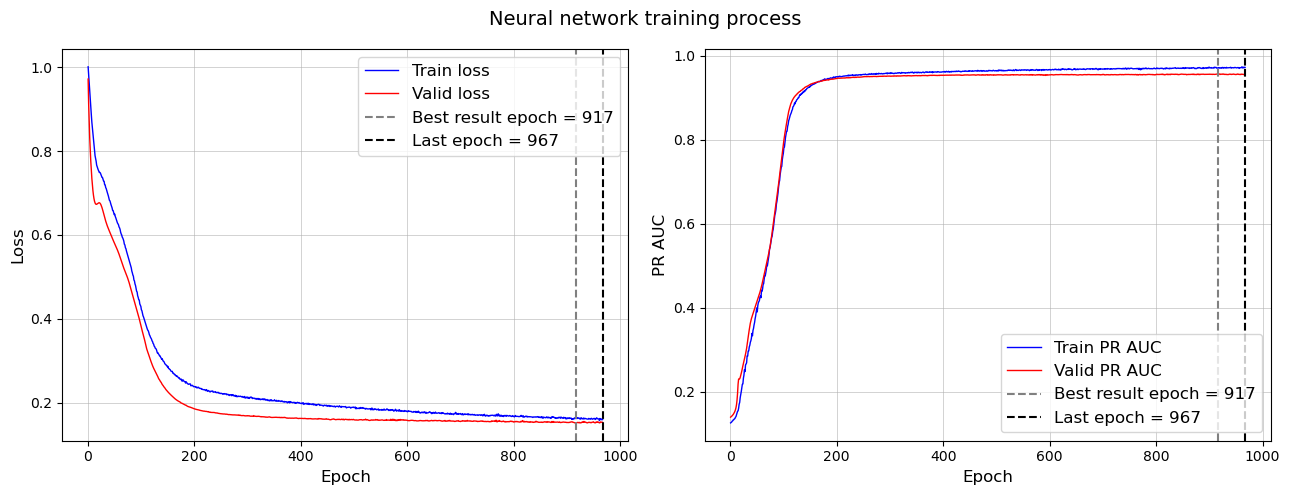

In [135]:
history = nn_model.history
epochs_axis = range(1, history.break_epoch + 1)
plt.figure(figsize=(13, 5))
plt.suptitle('Neural network training process', fontsize=14)
plt.subplot(1, 2, 1)
plt.plot(
    epochs_axis,
    history.train_losses,
    color='blue',
    linewidth=1,
    label='Train loss',
)
plt.plot(
    epochs_axis,
    history.valid_losses,
    color='red',
    linewidth=1,
    label='Valid loss'
)
plt.axvline(
    x=history.best_epoch,
    color='grey',
    linewidth=1.5,
    linestyle='--',
    label=f'Best result epoch = {history.best_epoch}'
)
plt.axvline(
    x=history.break_epoch,
    color='black',
    linewidth=1.5,
    linestyle='--',
    label=f'Last epoch = {history.break_epoch}'
)
plt.legend(fontsize=12, loc='upper right')
plt.xlabel('Epoch', fontsize=12); plt.ylabel('Loss', fontsize=12)
plt.grid(linewidth=0.4)
plt.tight_layout()

plt.subplot(1, 2, 2)
plt.plot(
    epochs_axis,
    history.train_pr_aucs,
    color='blue',
    linewidth=1,
    label='Train PR AUC',
)
plt.plot(
    epochs_axis,
    history.valid_pr_aucs,
    color='red',
    linewidth=1,
    label='Valid PR AUC'
)
plt.axvline(
    x=history.best_epoch,
    color='grey',
    linewidth=1.5,
    linestyle='--',
    label=f'Best result epoch = {history.best_epoch}'
)
plt.axvline(
    x=history.break_epoch,
    color='black',
    linewidth=1.5,
    linestyle='--',
    label=f'Last epoch = {history.break_epoch}'
)
plt.legend(fontsize=12, loc='lower right')
plt.xlabel('Epoch', fontsize=12); plt.ylabel('PR AUC', fontsize=12)
plt.grid(linewidth=0.4)
plt.tight_layout()
plt.show()

In [136]:
# Probabilities
y_probs_NN_train = nn_model.predict_proba(X_train)

# Obtaining best threshold for Neural Network based on Fbeta-score
nn_best_threshold = nn_cv_agg_res.loc['Threshold', 'Median']

# Predictions on train
y_pred_NN_train = np.where(y_probs_NN_train[:, 1] > nn_best_threshold, 1, 0) # nn_model.predict(X_train)

#### Testing model on test data

In [137]:
""" Evaluating best model on test data """
best_model = nn_model.history.best_model
print(best_model.layer_stack)

""" predict_proba() method uses best model """
y_probs_NN_test = nn_model.predict_proba(X_test)
y_pred_NN_test = np.where(y_probs_NN_test[:, 1] > nn_best_threshold, 1, 0) # nn_model.predict(X_test)

# Loss on test data
X_test_tensor = torch.tensor(X_test.to_numpy(), dtype=torch.float32, device=device)
y_test_tensor = torch.tensor(y_test.to_numpy(), dtype=torch.long, device=device)
y_test_logits = best_model(X_test_tensor).squeeze() # forward step to get logits for test data
test_loss = history.loss_fn(y_test_logits, y_test_tensor).item()
print(f"Test loss: {test_loss:.5f}")

Sequential(
  (0): Linear(in_features=42, out_features=64, bias=True)
  (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): Dropout(p=0.2, inplace=False)
  (4): Linear(in_features=64, out_features=2, bias=True)
)
Test loss: 0.14758


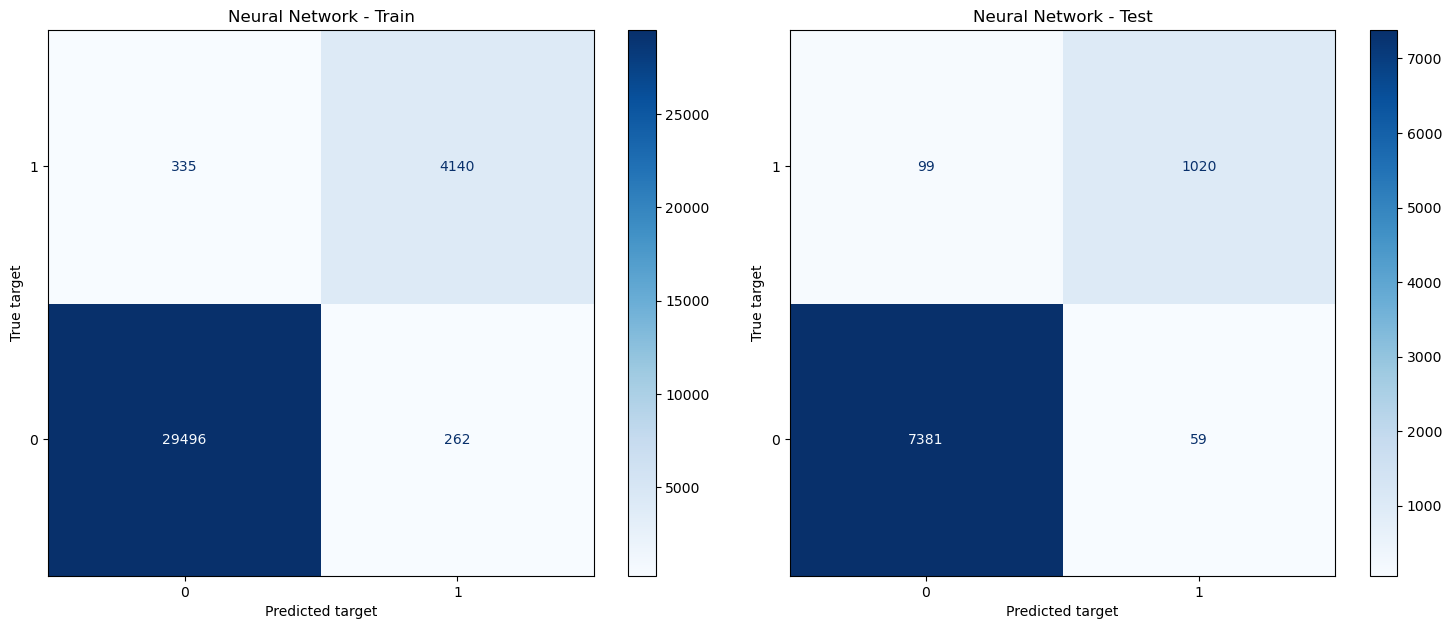

Train data:
Accuracy: 0.983
                  0        1  accuracy  macro avg  weighted avg
precision     0.989    0.940     0.983      0.965         0.982
recall        0.991    0.925     0.983      0.958         0.983
f1-score      0.990    0.933     0.983      0.961         0.982
support   29758.000 4475.000     0.983  34233.000     34233.000


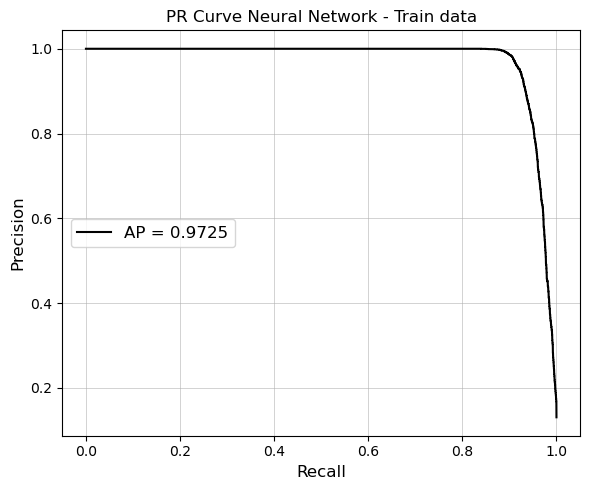


Test data:
Accuracy: 0.982
                 0        1  accuracy  macro avg  weighted avg
precision    0.987    0.945     0.982      0.966         0.981
recall       0.992    0.912     0.982      0.952         0.982
f1-score     0.989    0.928     0.982      0.959         0.981
support   7440.000 1119.000     0.982   8559.000      8559.000


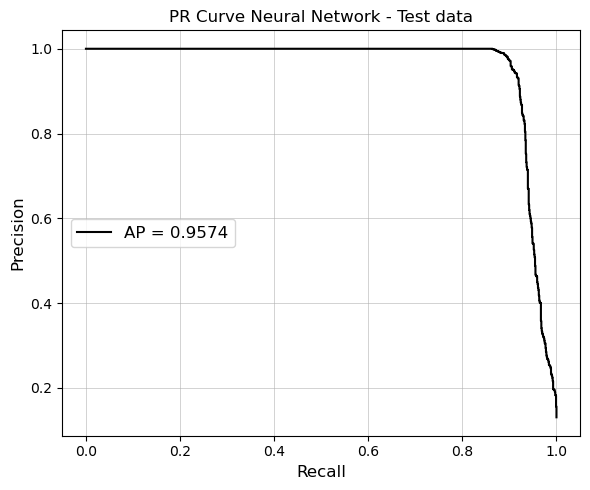

In [138]:
cm_train_NN, cm_test_NN = hf.display_confusion_matrix(
    y1_true=y_train,
    y1_pred=y_pred_NN_train,
    y2_true=y_test,
    y2_pred=y_pred_NN_test,
    # title='Confusion Matrices - Neural Network | Train vs Test',
    model_name='neural network',
    cmap="Blues",
    compare=['Train', 'Test']
)
hf.quality_metrics(
    y_true=y_train,
    y_pred=y_pred_NN_train,
    y_probs=y_probs_NN_train[:, 1],
    label='Train data',
    pr_curve_title='PR Curve Neural Network - Train data'
)
clf_report_nn_test = hf.quality_metrics(
    y_true=y_test,
    y_pred=y_pred_NN_test,
    y_probs=y_probs_NN_test[:, 1],
    label='\nTest data',
    pr_curve_title='PR Curve Neural Network - Test data'
)

In [139]:
nn_res_table_test = transform_eval_res_dict_to_df(
    clf_report=clf_report_nn_test,
	y_true=y_test,
	y_pred=y_pred_NN_test
)
nn_res_table_test

Class     
              0    1
Precision  0.99 0.94
Recall     0.99 0.91
F1-score   0.99 0.93
F2-score   0.99 0.92
Accuracy   0.98 0.98

In [140]:
save_latex_table(
    df=nn_res_table_test, 
	cwd_rel_path='latex_tables/nn_res_table_test.tex', 
	include_index=True, 
	float_format="%.3f"
)

#### Feature importances and SHAP values for Neural Network model

Calculating feature importances for Neural network model ...


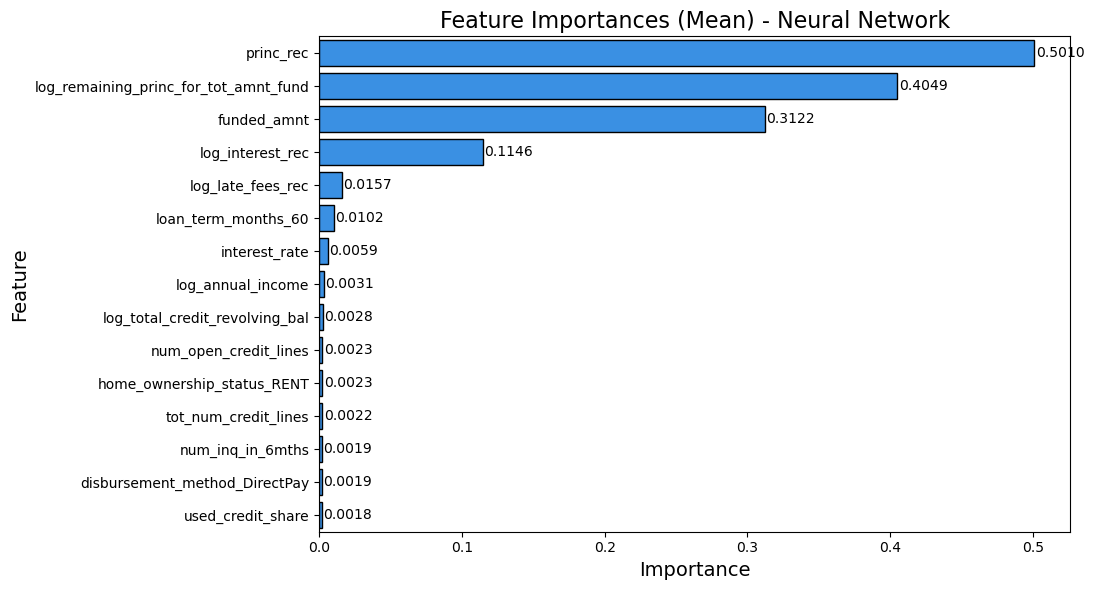

In [141]:
nn_scorer = hf.make_threshold_scorer(
    scoring='fbeta',
	threshold=nn_best_threshold,
    beta=nn_beta
)
nn_feat_names_sorted_desc_by_importance = hf.plot_feature_importances(
	model=nn_model,
	model_name='Neural Network',
	X_data=X_train,
	y_data=y_train,
	n_reps=5,
	scoring=nn_scorer,
	max_num_features=15,
	n_jobs=2
)

Calculating SHAP values for Neural network model ...


PermutationExplainer explainer: 1712it [01:13, 23.37it/s]                          


(.values =
array([[[-9.55150034e-02,  9.55150022e-02],
        [ 4.89155552e-04, -4.89158045e-04],
        [ 5.95703027e-04, -5.95701004e-04],
        ...,
        [ 1.85573183e-04, -1.85572851e-04],
        [-1.10991727e-02,  1.10991714e-02],
        [-5.87273268e-04,  5.87272746e-04]],

       [[ 2.32587429e-02, -2.32587438e-02],
        [-3.36633290e-03,  3.36633262e-03],
        [ 4.48204536e-03, -4.48204395e-03],
        ...,
        [-2.33400884e-04,  2.33400671e-04],
        [ 7.64435762e-05, -7.64432862e-05],
        [ 1.60248851e-03, -1.60248750e-03]],

       [[-2.84562568e-01,  2.84562568e-01],
        [ 5.45378400e-04, -5.45376159e-04],
        [ 3.60760299e-03, -3.60759947e-03],
        ...,
        [-5.75151509e-05,  5.75152307e-05],
        [-1.25258937e-03,  1.25258906e-03],
        [ 8.97987249e-04, -8.97986849e-04]],

       ...,

       [[ 3.17157209e-01, -3.17157209e-01],
        [ 9.32849405e-03, -9.32849541e-03],
        [ 2.86581655e-03, -2.86581787e-03],
       

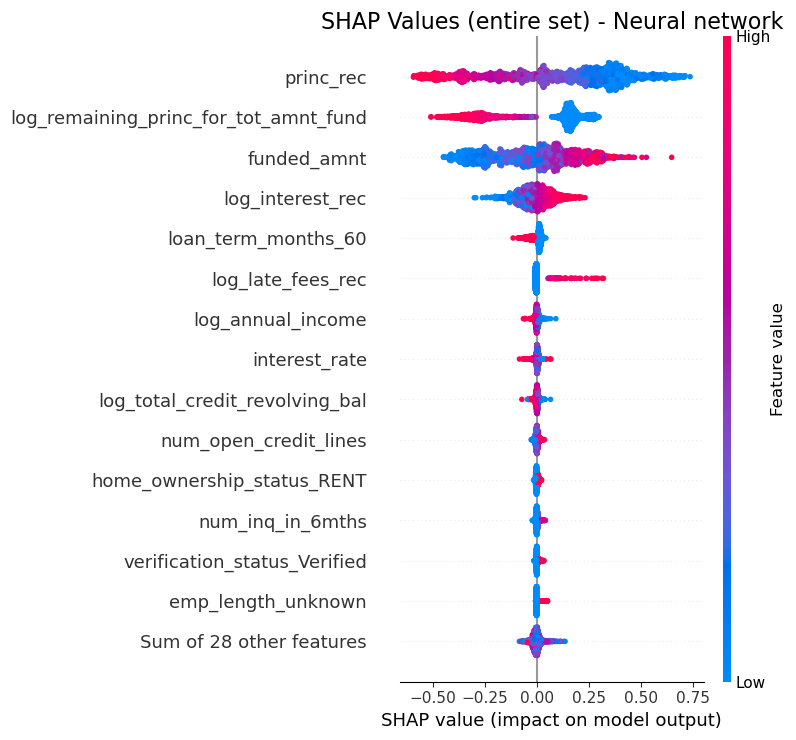

Sample pred: 1


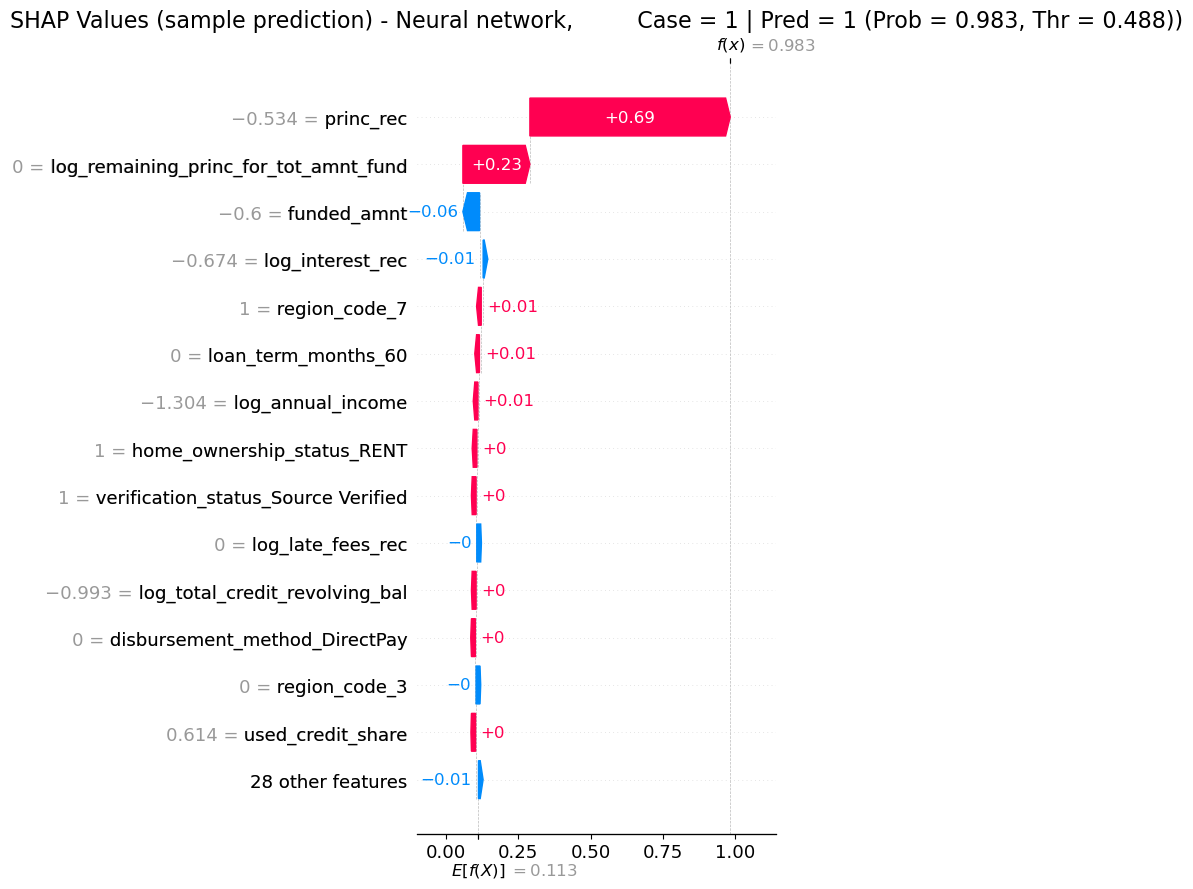

In [142]:
hf.plot_shap_values(
    model=nn_model,
    model_name="Neural Network",
    X_train=X_train,
    y_train=y_train,
	X_valid=X_train,
    y_valid=y_train,
    threshold=nn_best_threshold,
    random_state=random_state
)

#### PCA Visualization - Neural Network

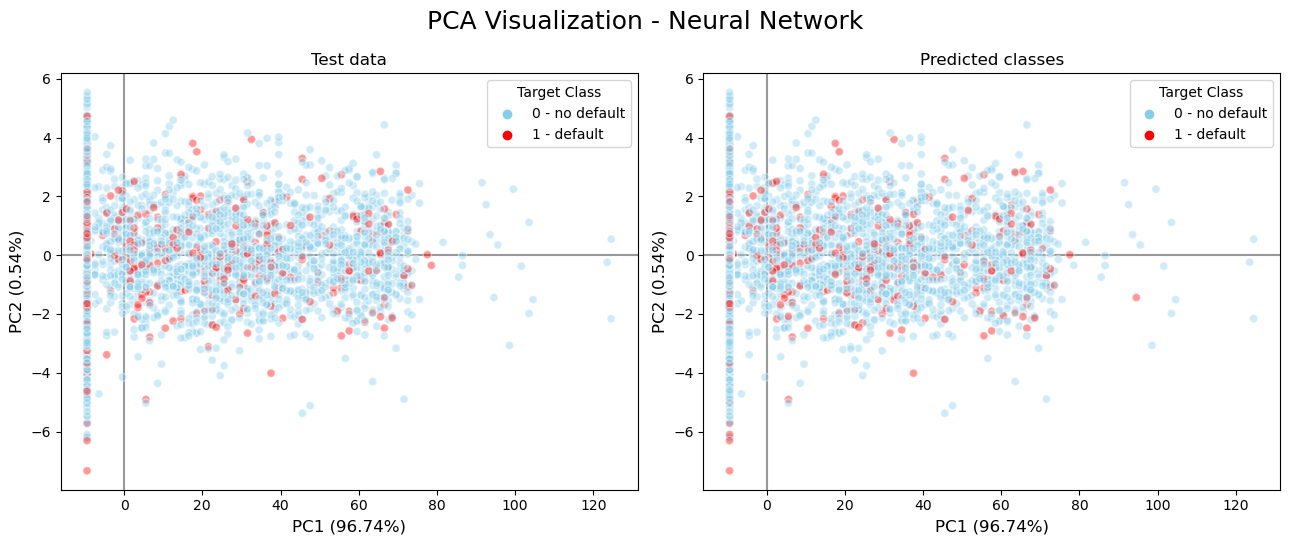

In [143]:
hf.pca_visualization(
	X_train=X_train,
	X_new=X_test,
	y_new_true=y_test,
	y_new_pred=y_pred_NN_test,
	colors_dict=colors_dict,
	class_names_dict=class_names_dict,
	model_name='Neural Network',
	valid_or_test='Test',
	alpha=0.4
)

### Visualising threshold values in each fold and for each method 

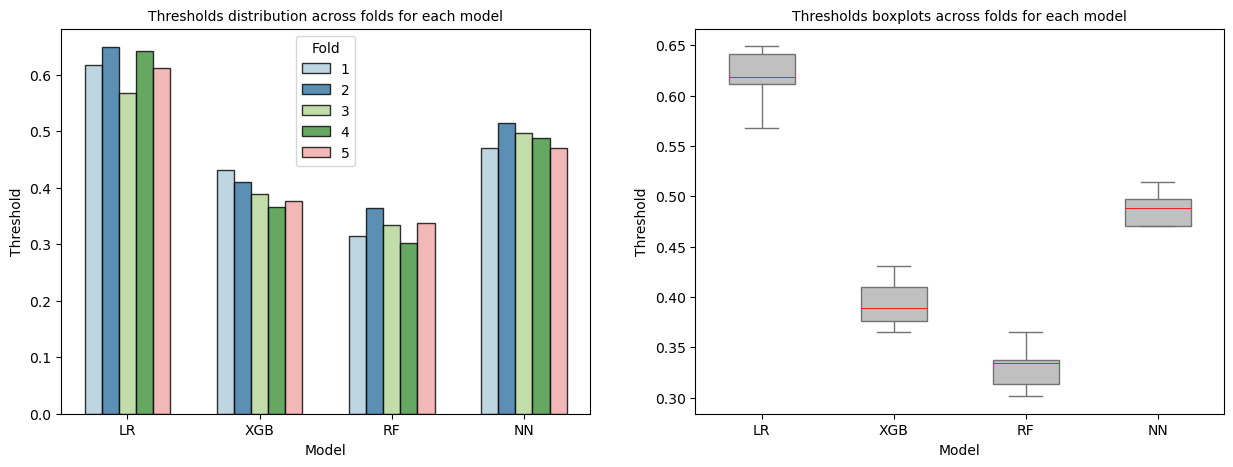

In [144]:
df_thresholds = pd.DataFrame({
    'Fold': lr_cv_res['Fold'],
    'LR': lr_cv_res['Threshold'],
	'XGB': xgb_cv_res['Threshold'],
	'RF': rf_cv_res['Threshold'],
	'NN': nn_cv_res['Threshold']
})
df_thresholds_melted = df_thresholds.melt(
    id_vars='Fold', 
	var_name='Model', 
	value_name='Threshold'
)

_, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(
    data=df_thresholds_melted,
    x='Model',
    y='Threshold',
    hue='Fold',
    ax=axes[0],
    palette='Paired',
    edgecolor='black',
    width=0.65,
    alpha=0.8
)
axes[0].set_title('Thresholds distribution across folds for each model', fontsize=10)
sns.boxplot(
    data=df_thresholds_melted,
    x='Model',
	y='Threshold', 
    ax=axes[1],
    color='silver',
    width=0.5,
    medianprops={'color': 'red', 'linewidth': 0.6}
)
axes[1].set_title('Thresholds boxplots across folds for each model', fontsize=10)
plt.show()

### Visualising PR curves for each method for test data

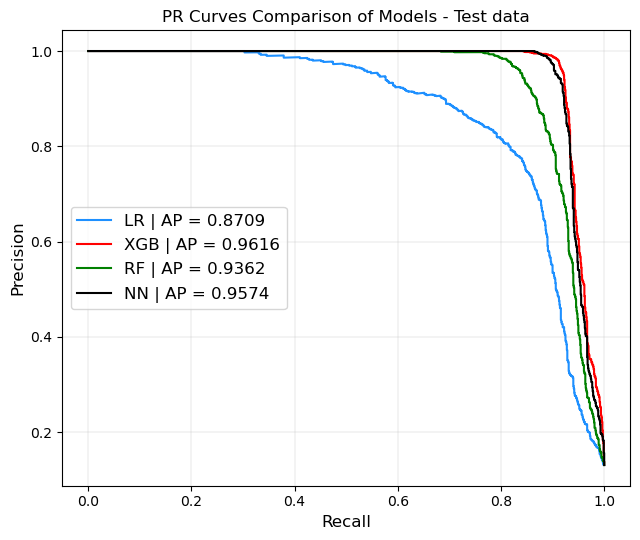

In [145]:
y_probs_test = [y_probs_LR_test, y_probs_XGB_test, y_probs_RF_test, y_probs_NN_test]
model_names = ['LR', 'XGB', 'RF', 'NN']
colors = ['dodgerblue', 'red', 'green', 'black']

plt.figure(figsize=(6.5, 5.5))
for probs, name, color in zip(y_probs_test, model_names, colors):
    precisions, recalls, _ = hf.precision_recall_curve(y_true=y_test, y_score=probs[:, 1], pos_label=1)
    avg_precision_score = hf.average_precision_score(y_true=y_test, y_score=probs[:, 1])
    plt.plot(
      recalls,
      precisions,
      label=f'{name} | AP = {avg_precision_score:.4f}',
      color=color
  )
plt.xlabel('Recall', fontsize=12); plt.ylabel('Precision', fontsize=12)
plt.legend(loc='center left', fontsize=12)
plt.title('PR Curves Comparison of Models - Test data', fontsize=12)
plt.grid(linewidth=0.2)
plt.tight_layout()
plt.show()

In [146]:
""" 
Fbeta-score for all models on test data with beta value calculated based on class imbalance 
in the target variable to give more weight to recall than precision
"""
lr_fbeta_score = hf.fbeta_score(y_true=y_test, y_pred=y_pred_LR_test, beta=beta)
xgb_fbeta_score = hf.fbeta_score(y_true=y_test, y_pred=y_pred_XGB_test, beta=beta)
rf_fbeta_score = hf.fbeta_score(y_true=y_test, y_pred=y_pred_RF_test, beta=beta)
nn_fbeta_score = hf.fbeta_score(y_true=y_test, y_pred=y_pred_NN_test, beta=beta)

lr_eval_scores = clf_report_lr_test.loc[['precision', 'recall', 'f1-score'], '1']
xgb_eval_scores = clf_report_xgb_test.loc[['precision', 'recall', 'f1-score'], '1']
rf_eval_scores = clf_report_rf_test.loc[['precision', 'recall', 'f1-score'], '1']
nn_eval_scores = clf_report_nn_test.loc[['precision', 'recall', 'f1-score'], '1']

lr_acc_score = clf_report_lr_test['accuracy'].iloc[0]
xgb_acc_score = clf_report_xgb_test['accuracy'].iloc[0]
rf_acc_score = clf_report_rf_test['accuracy'].iloc[0]
nn_acc_score = clf_report_nn_test['accuracy'].iloc[0]

models_eval_res = {
    "LR": [ *lr_eval_scores.values, lr_fbeta_score, lr_acc_score ],
    "XGB": [ *xgb_eval_scores.values, xgb_fbeta_score, xgb_acc_score ],
    "RF": [ *rf_eval_scores.values, rf_fbeta_score, rf_acc_score ],
    "NN": [ *nn_eval_scores.values, nn_fbeta_score, nn_acc_score ]
}
fbeta_score_colname = f'F{beta}-score'

In [147]:
old_format = pd.options.display.float_format
pd.options.display.float_format = '{:.3f}'.format

# Scores for positive class for each model on test data in dataframe
model_scores_df = pd.DataFrame(
    models_eval_res.values(),
    index=models_eval_res.keys(),
    columns=[ *lr_eval_scores.index.map(capwords), fbeta_score_colname, 'Accuracy' ]
)
model_scores_df

,Precision,Recall,F1-score,F2-score,Accuracy
LR,0.737,0.858,0.793,0.831,0.941
XGB,0.959,0.920,0.939,0.927,0.984
RF,0.868,0.878,0.873,0.876,0.967
NN,0.945,0.912,0.928,0.918,0.982


In [148]:
save_latex_table(
	df=model_scores_df, 
	cwd_rel_path='latex_tables/model_scores_df.tex', 
	include_index=True, 
	float_format="%.3f"
)

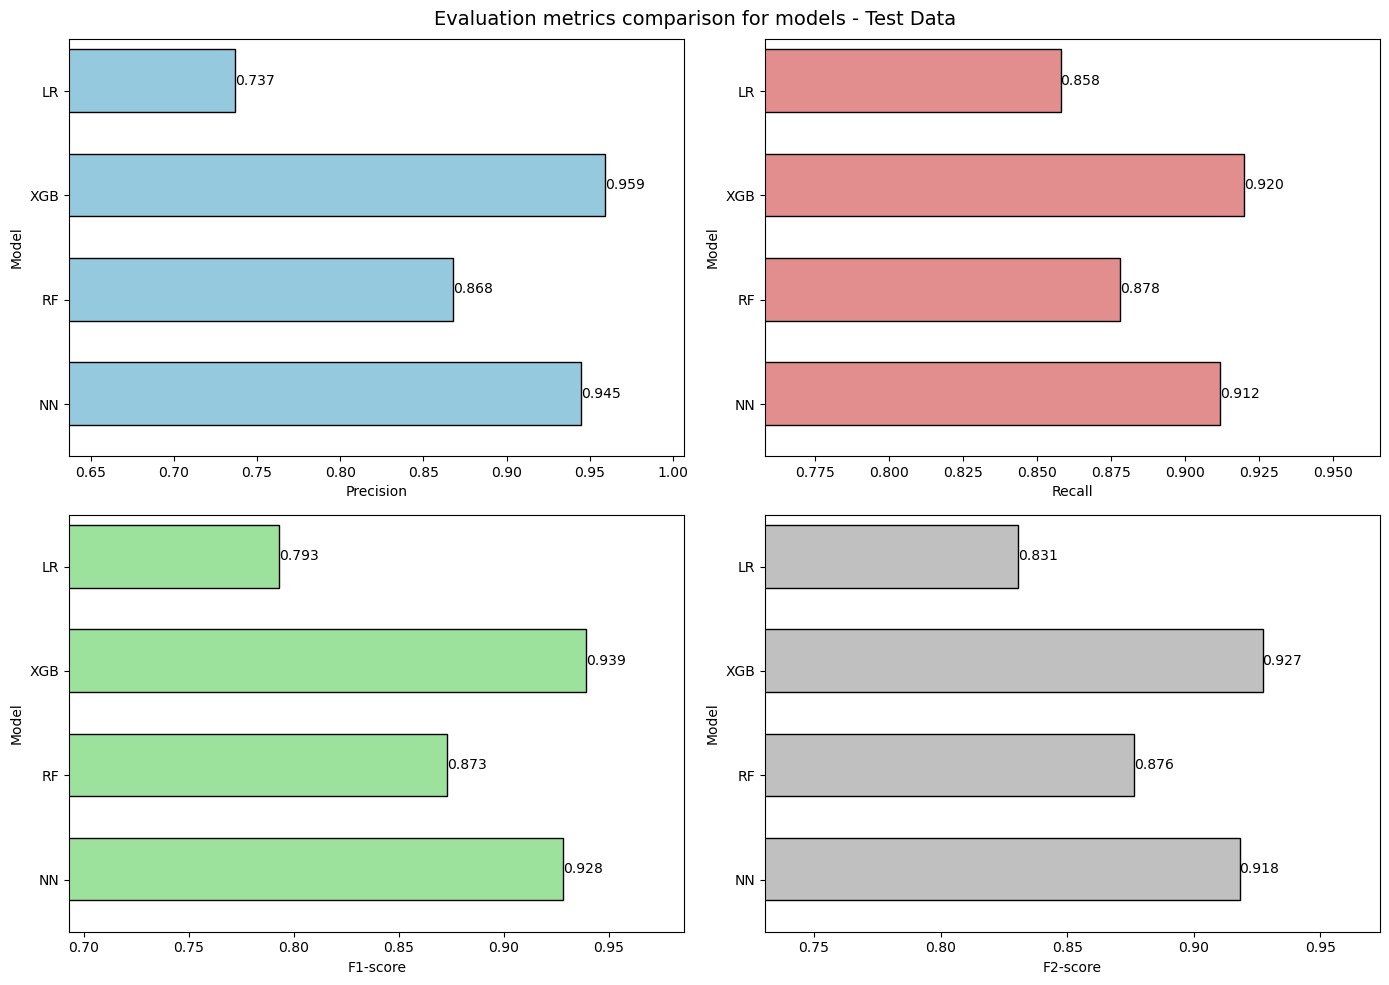

In [149]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
sns.barplot(
    data=model_scores_df,
    x="Precision",
    y=model_scores_df.index,
    ax=axes[0],
    linewidth=1,
    edgecolor='black',
    height=0.6,
    color='skyblue'
)
axes[0].bar_label(axes[0].containers[0], fmt='%.3f')
axes[0].set_xlabel("Precision")
axes[0].set_ylabel("Model")
axes[0].set_xlim( left=model_scores_df['Precision'].min() - 0.1 )

sns.barplot(
    data=model_scores_df,
    x="Recall",
    y=model_scores_df.index,
    ax=axes[1],
    linewidth=1,
    edgecolor='black',
    height=0.6,
    color='lightcoral'
)
axes[1].bar_label(axes[1].containers[0], fmt='%.3f')
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Model")
axes[1].set_xlim( left=model_scores_df['Recall'].min() - 0.1 )

sns.barplot(
    data=model_scores_df,
    x="F1-score",
    y=model_scores_df.index,
    ax=axes[2],
    linewidth=1,
    edgecolor='black',
    height=0.6,
    color='lightgreen'
)
axes[2].bar_label(axes[2].containers[0], fmt='%.3f')
axes[2].set_xlabel("F1-score")
axes[2].set_ylabel("Model")
axes[2].set_xlim( left=model_scores_df['F1-score'].min() - 0.1 )

sns.barplot(
    data=model_scores_df,
    x=fbeta_score_colname,
    y=model_scores_df.index,
    ax=axes[3],
    linewidth=1,
    edgecolor='black',
    height=0.6,
    color='silver'
)
axes[3].bar_label(axes[3].containers[0], fmt='%.3f')
axes[3].set_xlabel(fbeta_score_colname)
axes[3].set_ylabel("Model")
axes[3].set_xlim( left=model_scores_df[fbeta_score_colname].min() - 0.1 )
plt.suptitle('Evaluation metrics comparison for models - Test Data', fontsize=14)
plt.tight_layout()
plt.show()

In [150]:
pd.options.display.float_format = old_format
gloabl_end_time = time.time()
print(f"Total execution time: {(gloabl_end_time - global_start_time):.2f} seconds")

Total execution time: 1141.65 seconds
